# cluster specific TF-gene activaltion
#### cluster can be cell type, niche, spatial cluster etc

1. Link peaks to marker genes for clusters and to genes in gene set
    - annotate as proximal: 100-2000bp upstream TSS 
    - annotate as distal: +/- 150kbp TSS (and not proximal)
2. Identify relevant peaks for specific cluster: differs from BA
    - test for cluster: overaccessible compared to background clusters?
3. Identify TFs for which motifs are enriched in these peaks 
    - continue with 2 analysis paths: 
        - for single clusters
        - for all clusters
4. Score local footprints
    - mean(valley) - mean(flanks)
    - standard diviation in flanks/ total number of sites with Tn5 insertions in flanks



In [1]:
library(parallel)
library(GenomicFeatures)
set.seed(1234)
library(repr)
library(motifmatchr)
library(fastmatch)
library(qlcMatrix)

library(ensembldb)
library(EnsDb.Hsapiens.v86)
library(AnnotationFilter)

library(Signac)
library(Seurat)
library(JASPAR2024)
library(TFBSTools)
library(BSgenome.Hsapiens.UCSC.hg38)
library(patchwork)
library(ggplot2)
library(Matrix)
library(zoo)
library(tidyr)

source("../multiome_methods/function_calls.r")
source("../multiome_methods/peak_gene_relations.r")
source("../multiome_methods/binding_site_identification.r")
source("../multiome_methods/TF_activity.r")
source("../multiome_methods/signac_utils.r")

library(dplyr)

library(ggplot2)
library(hexbin)
library(RColorBrewer)
library(cowplot)
library(gridExtra)
library(ggExtra)

library(pheatmap)
library(purrr)
library(data.table)
library(Rsamtools)
library(stringi)


Loading required package: BiocGenerics

Loading required package: generics


Attaching package: ‘generics’


The following objects are masked from ‘package:base’:

    as.difftime, as.factor, as.ordered, intersect, is.element, setdiff,
    setequal, union



Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, is.unsorted, lapply, Map, mapply, match, mget,
    order, paste, pmax, pmax.int, pmin, pmin.int, Position, rank,
    rbind, Reduce, rownames, sapply, saveRDS, table, tapply, unique,
    unsplit, which.max, which.min


Loading required package: S4Vectors

Loading required package: stats4


Attaching package: ‘S4Vectors’


The following object is masked from ‘package:utils’:

    findMatches


The follo

In [23]:
# use output of global motif analysis
global_analysis_out <- readRDS("/nfs/home/students/m.back/swarm/backend/uploads/job_1773308453583_d28cf2eb-28cd-49e0-8ec3-d1871c00d0eb/kackhaufen1/global_motif_analysis.rds")

In [146]:
colnames(global_analysis_out@meta.data)

[1] "orig.ident"                 "nCount_RNA"                
 [3] "nFeature_RNA"               "nCount_ATAC"               
 [5] "nFeature_ATAC"              "percent.mt"                
 [7] "nucleosome_signal"          "nucleosome_percentile"     
 [9] "TSS.enrichment"             "TSS.percentile"            
[11] "nCount_peaks"               "nFeature_peaks"            
[13] "nCount_SCT"                 "nFeature_SCT"              
[15] "RNA.weight"                 "peaks.weight"              
[17] "RNA_peaks_clusters_res0.2"  "RNA_peaks_clusters_res0.1" 
[19] "RNA_peaks_clusters_res0.05" "SCT.weight"                
[21] "SCT_peaks_clusters_res0.2"  "SCT_peaks_clusters_res0.1" 
[23] "cell_type"

In [153]:
table(global_analysis_out@meta.data["cell_type"])

cell_type
   0    1    2    3    4    5    6    7    8    9 
1519 1109  956  505  327  252  198  164  133   57 

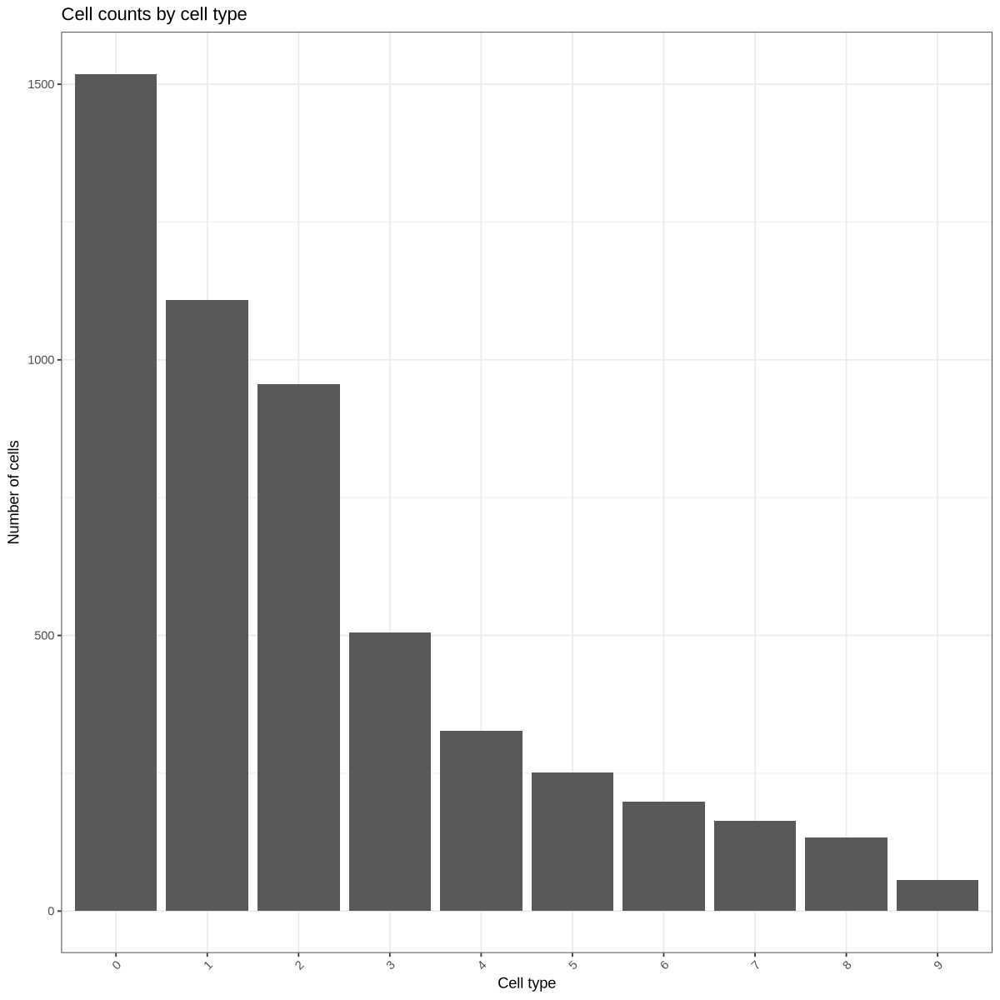

In [154]:
# Count cells per cell type
celltype_counts <- table(global_analysis_out@meta.data[["cell_type"]])

# Convert to data frame
df <- as.data.frame(celltype_counts)
colnames(df) <- c("cell_type", "n_cells")

# Bar chart
library(ggplot2)

ggplot(df, aes(x = reorder(cell_type, -n_cells), y = n_cells)) +
  geom_bar(stat = "identity") +
  theme_bw() +
  labs(x = "Cell type", y = "Number of cells", title = "Cell counts by cell type") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

In [58]:
global_analysis_out@misc$markers.annotated[global_analysis_out@misc$markers.annotated$annotation=="marker.pos.0",]$gene

[1] "IL1RAPL2"    "AP003555.2"  "AC044810.2"  "GRIA4"       "UNC5C"      
  [6] "TP63"        "LINC01060"   "FHOD3"       "OXTR"        "NRG1"       
 [11] "KRT5"        "TNS4"        "COL17A1"     "MIR31HG"     "AC124852.1" 
 [16] "PTPRT"       "PAMR1"       "AC113383.1"  "PDGFA"       "RBBP8"      
 [21] "AC098617.1"  "NFASC"       "PDE1C"       "CDH3"        "AC073050.1" 
 [26] "AL033504.1"  "FBXO32"      "SEMA3C"      "MYH11"       "MYLK"       
 [31] "KLHL29"      "MME"         "EPHB1"       "ISM1"        "CLDN11"     
 [36] "SAMD5"       "KLHL13"      "TENM2"       "RYR3"        "SDK2"       
 [41] "KCNMA1"      "SLC7A14-AS1" "ACTA2"       "EDIL3"       "MIR205HG"   
 [46] "LAMC2"       "TRABD2B"     "RASSF6"      "ANO1"        "TPM1"       
 [51] "CRISPLD1"    "IL17RD"      "NECTIN1"     "COL4A5"      "LTBP2"      
 [56] "PTPRZ1"      "SEMA5A"      "ITGBL1"      "MAMDC2-AS1"  "MAMDC2"     
 [61] "FGFR2"       "BTBD11"      "ITPR1"       "SLC2A9"      "AC093535.1" 
 [66] "TRPC6"       "FAM126A"     "MAOB"        "CSRP1"       "LMOD1"      
 [71] "SYNM"        "GRAMD2B"     "MPPED2"      "SGK1"        "ITGA2"      
 [76] "FGF1"        "WNT5B"       "ATP2B1"      "AC104041.1"  "TPM2"       
 [81] "IL1RAPL1"    "CACNA1C"     "ALDH7A1"     "NT5DC3"      "WLS"        
 [86] "SULF1"       "CARMN"       "GLI3"        "GAN"         "SYNPO2"     
 [91] "LINC01876"   "AL109930.1"  "RARB"        "USP31"       "TFAP2C"     
 [96] "IRX2"        "NTM"         "MEF2C-AS1"   "CMYA5"       "AMOTL1"

In [59]:
global_analysis_out@misc$markers.annotated[global_analysis_out@misc$markers.annotated$annotation=="marker.pos.1",]$gene

[1] "CCL28"      "EGF"        "GABRP"      "ELF5"       "KIT"       
  [6] "MYEOV"      "EHF"        "ATP13A5"    "BARX2"      "ATP13A4"   
 [11] "LINC00842"  "C10orf90"   "PADI2"      "APCDD1L-DT" "COBL"      
 [16] "KRT15"      "PLCH1"      "GRHL1"      "LINC02613"  "GUCY1A1"   
 [21] "GCNT2"      "NEBL"       "PROM1"      "AC009041.2" "RHPN2"     
 [26] "AC093817.2" "ELF3"       "KRT19"      "ADGRV1"     "LINC01152" 
 [31] "CHRM3"      "HS3ST4"     "AC009313.1" "SHANK2"     "IGF2BP2"   
 [36] "KIAA1324"   "AL109809.5" "ERBB3"      "HOMER2"     "AC023051.1"
 [41] "LRP2"       "AL583785.1" "WWC1"       "AC024145.1" "ROCR"      
 [46] "MACC1"      "ARHGEF38"   "KLF5"       "DSC2"       "RBM47"     
 [51] "WNK2"       "CATSPERB"   "CMTM8"      "SORBS2"     "CGNL1"     
 [56] "ITPR2"      "SGCD"       "SFRP1"      "TPD52L1"    "C4orf19"   
 [61] "AC108134.2" "SLC25A29"   "DTNB"       "NDRG2"      "NTN1"      
 [66] "MYO5B"      "MYEF2"      "MAPT"       "UPP2"       "NSUN7"     
 [71] "ARHGAP8"    "PRLR"       "SLC12A2"    "AP001442.1" "SOX9-AS1"  
 [76] "NRG3"       "CHKA"       "NLGN4X"     "ST8SIA1"    "EXPH5"     
 [81] "SNTB1"      "MFGE8"      "SHROOM3"    "PLA2R1"     "GPM6B"     
 [86] "TANK"       "SLC25A37"   "PYGB"       "NPAS2"      "ITPRID2"   
 [91] "POLR2F"     "AK5"        "CSRNP3"     "PIK3C2G"    "PDCD4"     
 [96] "PPP1R9A"    "SLC24A3"    "IQGAP2"     "ETV6"       "TRPS1"

In [61]:
global_analysis_out@misc$markers.annotated[global_analysis_out@misc$markers.annotated$annotation=="marker.pos.2",]$gene

[1] "AC110023.1"  "AADACL2-AS1" "HPSE2"       "LINC02511"   "GRIA3"      
  [6] "LINC01482"   "IGSF10"      "FAP"         "COL6A6"      "LINC02224"  
 [11] "AC005064.1"  "FGF10-AS1"   "AC005323.2"  "DCLK1"       "VCAN"       
 [16] "AC011503.1"  "COL6A3"      "LAMA2"       "THBS2"       "LYPLAL1-AS1"
 [21] "ADAM12"      "SLIT2"       "ADAM33"      "ABCA9-AS1"   "FAM20A"     
 [26] "ALX4"        "RGMA"        "COL1A2"      "CCBE1"       "KCNMB2"     
 [31] "NEGR1"       "DCN"         "PDGFRA"      "FGF7"        "TBX18"      
 [36] "COL1A1"      "MMP16"       "ABCA9"       "SRPX"        "FGF10"      
 [41] "MEG8"        "ARHGAP6"     "COL3A1"      "ABCA6"       "FMN2"       
 [46] "ABCA8"       "CNTN1"       "AL445250.1"  "CXCL12"      "FREM1"      
 [51] "PRRX1"       "ADAMTS12"    "ABCA10"      "GAS7"        "KCND2"      
 [56] "FBLN5"       "CDON"        "NOVA1"       "AC116362.1"  "AC104211.1" 
 [61] "FBLN1"       "ZFHX4"       "GRID1"       "TBX15"       "NLGN1"      
 [66] "SPON2"       "DOK6"        "SLC26A5"     "CFH"         "MEG3"       
 [71] "APOD"        "GALNT17"     "COL5A1"      "ST3GAL5"     "BMPER"      
 [76] "NR2F1-AS1"   "ALDH1A2"     "IGF1"        "PDGFRB"      "MITF"       
 [81] "KCNT2"       "GLI2"        "PLXDC1"      "ARHGAP28"    "PTPRD"      
 [86] "PID1"        "COL15A1"     "BICC1"       "LPAR1"       "PLAGL1"     
 [91] "SLIT3"       "RUNX1T1"     "ADGRA2"      "BNC2"        "ROR2"       
 [96] "PDE10A"      "LRFN5"       "TWIST2"      "ABI3BP"      "SLC7A2"

**in the myoepithelial/basal compartment of normal breast tissue**, smooth-muscle-contraction biology is genuinely important. Mammary **myoepithelial cells are contractile cells** that surround ducts/alveoli and respond to **oxytocin** to help eject milk; that role is well established in reviews and functional studies. ([PMC][1])

For **healthy breast single-cell data**, that means a “smooth muscle contraction” signal is often a **normal myoepithelial program**, not automatically a problem. Human breast atlases describe basal/myoepithelial cells as a contractile epithelial population, and marker sets for that compartment include genes such as **TP63, KRT5, ACTA2, and MYLK**, which overlap strongly with your list. ([PMC][2])

The main nuance is that this pathway is **important in some breast cells, not all breast cells**. It is especially expected in **myoepithelial cells**, and much less so in luminal epithelial cells. Also, a very strong contractile signature can sometimes reflect **vascular smooth muscle/pericytes** instead of myoepithelium, so the epithelial markers matter for interpretation. In your list, genes like **TP63, KRT5, COL17A1, CDH3, and LAMC2** push the interpretation toward **myoepithelial/basal breast cells** rather than pure vascular smooth muscle. ([PubMed][3])


**specifically because normal breast contains a contractile myoepithelial layer.**
Given your genes, **“normal breast myoepithelial contractile program”** is a better label than the broader phrase **“smooth muscle”** alone.

[1]: https://pmc.ncbi.nlm.nih.gov/articles/PMC3123380/ "Myoepithelial Cell Contraction and Milk Ejection Are Impaired ..."
[2]: https://pmc.ncbi.nlm.nih.gov/articles/PMC9202341 "A Human Breast Atlas Integrating Single-Cell Proteomics and ..."
[3]: https://pubmed.ncbi.nlm.nih.gov/14758723/ "The usefulness of p63 as a marker of breast myoepithelial ..."


In [2]:

library(AnnotationDbi)
library(org.Hs.eg.db)
smooth_muscle_contraction <- AnnotationDbi::select(
  org.Hs.eg.db,
  keys    = "GO:0006939",
  keytype = "GOALL",
  columns = c("ENSEMBL", "SYMBOL", "GOALL", "ONTOLOGYALL")
)
head(smooth_muscle_contraction)
dim(smooth_muscle_contraction)

'select()' returned 1:many mapping between keys and columns



,GOALL,EVIDENCEALL,ONTOLOGYALL,ENSEMBL,SYMBOL
,<chr>,<chr>,<chr>,<chr>,<chr>
1,GO:0006939,IEA,BP,ENSG00000183044,ABAT
2,GO:0006939,IEA,BP,ENSG00000107796,ACTA2
3,GO:0006939,IEA,BP,ENSG00000196839,ADA
4,GO:0006939,IEA,BP,ENSG00000170425,ADORA2B
5,GO:0006939,IEA,BP,ENSG00000120907,ADRA1A
6,GO:0006939,TAS,BP,ENSG00000120907,ADRA1A


[1] 123   5

In [67]:
intersect(smooth_muscle_contraction$SYMBOL, global_analysis_out@misc$markers.annotated[global_analysis_out@misc$markers.annotated$annotation=="marker.pos.0",]$gene)

[1] "ACTA2"  "ATP2B1" "ITGA2"  "KCNMA1" "MYH11"  "MYLK"   "OXTR"   "SULF1"

# smooth muscle contration 
A common **gene regulatory pathway in healthy human breast tissue** is the **estrogen receptor alpha (ERα) signaling network**, especially in **luminal epithelial cells**. In this pathway, **estradiol** activates **ERα (encoded by *ESR1*)**, which works with transcription factors such as **FOXA1** and **GATA3** to regulate downstream genes involved in normal luminal identity and hormone responsiveness. ([PMC][1])

**estradiol → ERα/*ESR1* → FOXA1/GATA3-assisted DNA binding → target genes such as *PGR*, *GREB1*, and *TFF1***. ([PMC][2])

One useful nuance: in **normal human breast tissue**, ERα is not in every cell; it is mainly found in a **subset of luminal epithelial cells** rather than the whole tissue. ([PMC][1])


[1]: https://pmc.ncbi.nlm.nih.gov/articles/PMC8616513/?utm_source=chatgpt.com "Positive Regulation of Estrogen Receptor Alpha in Breast ..."
[2]: https://pmc.ncbi.nlm.nih.gov/articles/PMC6627240/?utm_source=chatgpt.com "Transcriptional regulation of normal human mammary cell ..."


# 0. find cluster that might be relevant for this pathway


In [3]:
seed_genes <- smooth_muscle_contraction$SYMBOL

In [81]:
priorGRN <- read.csv("/nfs/data3/mopitas/mapra/TFnets/breast_tbl_full.csv")

In [82]:
head(priorGRN)

,TF,Gene,Prior,Breast_netTS,Breast_net
,<chr>,<chr>,<int>,<int>,<dbl>
1,ARID3A,ENSG00000000003,1,0,4.8115
2,CDC5L,ENSG00000000003,1,0,4.5396
3,CEBPA,ENSG00000000003,1,0,4.4718
4,CPEB1,ENSG00000000003,1,0,4.1023
5,CTCF,ENSG00000000003,1,0,4.1788
6,CTCFL,ENSG00000000003,1,0,3.1294


In [83]:
# combine priorGRN with seed genes and extrend by relevant marker genes for cluster
gene_name_2_gene_id <- read.csv("/nfs/data3/mopitas/mapra/TFnets/genename2EID.csv")
head(gene_name_2_gene_id)

,gene_name,gene_id
,<chr>,<chr>
1,DDX11L1,ENSG00000223972
2,MIR1302-2HG,ENSG00000243485
3,OR4G4P,ENSG00000268020
4,ENSG00000290826,ENSG00000290826
5,OR4G11P,ENSG00000240361
6,OR4F5,ENSG00000186092


In [84]:
priorGRN <- priorGRN %>%
  dplyr::left_join(gene_name_2_gene_id, by = c("Gene" = "gene_id"))

Warning message in dplyr::left_join(., gene_name_2_gene_id, by = c(Gene = "gene_id")):
"Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 1 of `x` matches multiple rows in `y`.
ℹ Row 63317 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning."


In [85]:
head(priorGRN)

,TF,Gene,Prior,Breast_netTS,Breast_net,gene_name
,<chr>,<chr>,<int>,<int>,<dbl>,<chr>
1,ARID3A,ENSG00000000003,1,0,4.8115,TSPAN6
2,ARID3A,ENSG00000000003,1,0,4.8115,TE
3,CDC5L,ENSG00000000003,1,0,4.5396,TSPAN6
4,CDC5L,ENSG00000000003,1,0,4.5396,TE
5,CEBPA,ENSG00000000003,1,0,4.4718,TSPAN6
6,CEBPA,ENSG00000000003,1,0,4.4718,TE


In [90]:
priorGRN_full <- priorGRN[(priorGRN$gene_name %in% seed_genes) & ((priorGRN$Prior ==1) | (priorGRN$Breast_netTS ==1)) & (priorGRN$Breast_net > 2), ]

In [91]:
dim(priorGRN_full)

[1] 7223    6

In [18]:
length(unique(seed_genes))

[1] 110

In [93]:
priorGRN_full[priorGRN_full$gene_name %in% c("MYLK", "MYH11", "KCNMA1") & priorGRN_full$TF=="SP1",]

,TF,Gene,Prior,Breast_netTS,Breast_net,gene_name
,<chr>,<chr>,<int>,<int>,<dbl>,<chr>
105194,SP1,ENSG00000065534,1,0,2.3744,MYLK
649983,SP1,ENSG00000133392,1,0,2.5551,MYH11
961450,SP1,ENSG00000156113,1,0,2.3581,KCNMA1


In [94]:
intersect(priorGRN_full$gene_name, global_analysis_out@misc$markers.annotated[global_analysis_out@misc$markers.annotated$annotation=="marker.pos.0",]$gene)

[1] "MYLK"   "ATP2B1" "ACTA2"  "MYH11"  "SULF1"  "KCNMA1" "ITGA2"  "OXTR"

In [95]:

write.csv(priorGRN_full, "/nfs/data3/mopitas/mapra/TFnets/breast_tbl_priorGRN_smooth_muscle_contraction_full.csv", row.names = FALSE)

In [74]:
priorGRN <- priorGRN[(priorGRN$gene_name %in% seed_genes) & (priorGRN$Breast_netTS ==1) & (priorGRN$Breast_net >5), ]

In [76]:
intersect(priorGRN$gene_name, global_analysis_out@misc$markers.annotated[global_analysis_out@misc$markers.annotated$annotation=="marker.pos.0",]$gene)

[1] "MYLK"  "ACTA2" "SULF1" "ITGA2" "OXTR"

In [77]:
write.csv(priorGRN, "/nfs/data3/mopitas/mapra/TFnets/breast_tbl_priorGRN_smooth_muscle_contraction.csv", row.names = FALSE)

In [78]:
priorGRN

,TF,Gene,Prior,Breast_netTS,Breast_net,gene_name
,<chr>,<chr>,<int>,<int>,<dbl>,<chr>
105176,SCRT2,ENSG00000065534,1,1,5.0926,MYLK
105206,TBX21,ENSG00000065534,1,1,5.2576,MYLK
105220,TFCP2,ENSG00000065534,1,1,6.8470,MYLK
189666,PKNOX2,ENSG00000085733,1,1,5.0987,CTTN
189706,TGIF1,ENSG00000085733,1,1,5.1848,CTTN
352492,ZBTB3,ENSG00000107796,1,1,5.2770,ACTA2
544058,ZBTB18,ENSG00000124205,1,1,6.2028,EDN3
554159,RFX4,ENSG00000125124,1,1,5.3587,BBS2
554193,TBX19,ENSG00000125124,1,1,5.7005,BBS2


In [79]:
plot_module_scores <- function(
  object,
  seed_genes,
  module_name = "ER_pathway_score",
  assay_name = "RNA",
  cluster_name = "cell_type",
  test_method = c("wilcox", "t.test"),
  alternative = c("greater", "two.sided", "less"),
  p_adjust_method = "BH",
  label_type = c("stars", "p.adj"),
  show_ns = TRUE
) {
  test_method <- match.arg(test_method)
  alternative <- match.arg(alternative)
  label_type <- match.arg(label_type)

  DefaultAssay(object) <- assay_name
  score_col <- paste0(module_name, "1")

  # Keep only genes present in this object
  seed_genes_present <- intersect(seed_genes, rownames(object))
  missing_genes <- setdiff(seed_genes, seed_genes_present)

  if (length(seed_genes_present) == 0) {
    stop("None of the seed genes are present in the object.")
  }

  cat("Genes found:", length(seed_genes_present), "\n")
  if (length(missing_genes) > 0) {
    cat("Missing genes:", paste(missing_genes, collapse = ", "), "\n")
  }

  Idents(object) <- cluster_name

  # Add module score
  object <- AddModuleScore(
    object = object,
    features = list(seed_genes_present),
    name = module_name,
    assay = assay_name,
    seed = 123
  )

  # Pull data for plotting
  plot_df <- FetchData(object, vars = c(cluster_name, score_col))
  colnames(plot_df) <- c("cluster", "score")

  # Order clusters by median score
  celltype_order <- plot_df %>%
    dplyr::group_by(cluster) %>%
    dplyr::summarise(med = median(score, na.rm = TRUE), .groups = "drop") %>%
    dplyr::arrange(dplyr::desc(med)) %>%
    dplyr::pull(cluster)

  plot_df$cluster <- factor(plot_df$cluster, levels = celltype_order)

  # Per-cluster enrichment test: cluster vs all other cells
  stats_df <- lapply(levels(plot_df$cluster), function(cl) {
    x <- plot_df$score[plot_df$cluster == cl]
    y <- plot_df$score[plot_df$cluster != cl]

    test_res <- switch(
      test_method,
      wilcox = stats::wilcox.test(x, y, alternative = alternative, exact = FALSE),
      `t.test` = stats::t.test(x, y, alternative = alternative)
    )

    data.frame(
      cluster = cl,
      n_cluster = length(x),
      n_other = length(y),
      mean_cluster = mean(x, na.rm = TRUE),
      mean_other = mean(y, na.rm = TRUE),
      median_cluster = median(x, na.rm = TRUE),
      median_other = median(y, na.rm = TRUE),
      effect_mean = mean(x, na.rm = TRUE) - mean(y, na.rm = TRUE),
      effect_median = median(x, na.rm = TRUE) - median(y, na.rm = TRUE),
      p_val = test_res$p.value,
      stringsAsFactors = FALSE
    )
  }) %>%
    dplyr::bind_rows() %>%
    dplyr::mutate(
      p_adj = stats::p.adjust(p_val, method = p_adjust_method)
    )

  # Significance labels
  p_to_stars <- function(p) {
    dplyr::case_when(
      is.na(p)        ~ NA_character_,
      p <= 1e-4       ~ "****",
      p <= 1e-3       ~ "***",
      p <= 1e-2       ~ "**",
      p <= 5e-2       ~ "*",
      TRUE            ~ "ns"
    )
  }

  stats_df <- stats_df %>%
    dplyr::mutate(
      label = if (label_type == "stars") {
        p_to_stars(p_adj)
      } else {
        paste0("adj.P=", signif(p_adj, 2))
      }
    )

  if (!show_ns && label_type == "stars") {
    stats_df$label[stats_df$label == "ns"] <- ""
  }

  # Y-positions for annotation
  y_range <- diff(range(plot_df$score, na.rm = TRUE))
  if (y_range == 0) y_range <- 1

  annot_df <- plot_df %>%
    dplyr::group_by(cluster) %>%
    dplyr::summarise(y_pos = max(score, na.rm = TRUE) + 0.06 * y_range, .groups = "drop") %>%
    dplyr::left_join(stats_df, by = "cluster")

  # Plot
  p <- ggplot(plot_df, aes(x = cluster, y = score, fill = cluster)) +
    geom_violin(trim = FALSE, scale = "width", color = "grey30") +
    geom_boxplot(width = 0.15, outlier.shape = NA, alpha = 0.5, color = "white") +
    geom_text(
      data = annot_df,
      aes(x = cluster, y = y_pos, label = label),
      inherit.aes = FALSE,
      vjust = 0,
      size = 4
    ) +
    theme_classic() +
    labs(
      x = cluster_name,
      y = score_col,
      subtitle = paste0(
        "Per-cluster enrichment test: ",
        test_method,
        " (", alternative, "), p-adjust = ", p_adjust_method
      )
    ) +
    scale_y_continuous(expand = ggplot2::expansion(mult = c(0.05, 0.15))) +
    theme(
      axis.text.x = element_text(angle = 45, hjust = 1),
      legend.position = "none"
    )

  return(list(
    plot = p,
    object = object,
    stats = stats_df,
    plot_data = plot_df
  ))
}

Genes found: 106 
Missing genes: MIR143, MIR145, MIR153-1, MIR21 


cluster,n_cluster,n_other,mean_cluster,mean_other,median_cluster,median_other,effect_mean,effect_median,p_val,p_adj,label
<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
9,57,5163,0.117804676,0.024261995,0.113939263,0.0160828318,0.093542681,0.097856432,1.094170e-16,5.470852e-16,****
0,1519,3701,0.075935027,0.004494526,0.076436828,-0.0001548249,0.071440502,0.076591653,1.484486e-300,1.484486e-299,****
7,164,5056,0.043811478,0.024682449,0.045593654,0.0155945380,0.019129029,0.029999116,1.057816e-07,3.526052e-07,****
8,133,5087,0.029037694,0.025185283,0.025724600,0.0164410091,0.003852411,0.009283591,5.686785e-02,1.421696e-01,
4,327,4893,0.024077351,0.025364041,0.022475161,0.0163657398,-0.001286690,0.006109421,1.310790e-01,2.621579e-01,
3,505,4715,0.023425880,0.025482392,0.018311426,0.0163657398,-0.002056512,0.001945687,2.774078e-01,4.623463e-01,
6,198,5022,-0.003216362,0.026407086,-0.007139568,0.0175813427,-0.029623448,-0.024720911,1.000000e+00,1.000000e+00,
2,956,4264,-0.005455229,0.032175128,-0.008513163,0.0249095672,-0.037630357,-0.033422730,1.000000e+00,1.000000e+00,
1,1109,4111,-0.007526441,0.034134364,-0.010543107,0.0263927743,-0.041660805,-0.036935881,1.000000e+00,1.000000e+00,


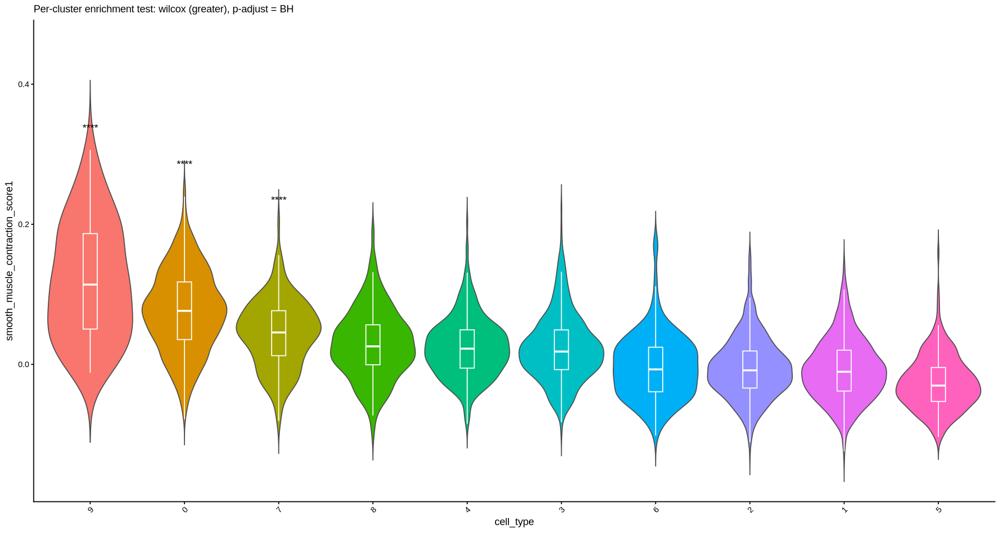

In [80]:
res <- plot_module_scores(
  object = global_analysis_out,
  seed_genes = seed_genes,
  module_name = "smooth_muscle_contraction_score",
  assay_name = "RNA",
  cluster_name = "cell_type",
  test_method = "wilcox",     # or "t.test"
  alternative = "greater",    # enrichment = higher in cluster than others
  label_type = "stars",
  show_ns = FALSE
)

res$plot
res$stats
global_analysis_out <- res$object

In [33]:
table(global_analysis_out@meta.data["cell_type"])

cell_type
   0    1    2    3    4    5    6    7    8    9 
1519 1109  956  505  327  252  198  164  133   57 

# 1. begin with linking peaks

In [81]:
# combine priorGRN with seed genes and extrend by relevant marker genes for cluster
gene_name_2_gene_id <- read.csv("/nfs/data3/mopitas/mapra/TFnets/genename2EID.csv")

linking_peaks_for_module_cluster <- function(object, 
                                            seed_genes, 
                                            priorGRN, 
                                            cluster,
                                            gene_name_2_gene_id,
                                            log2FC_threshold = 5,
                                            p_adj_threshold = 0.05,
                                            genome=BSgenome.Hsapiens.UCSC.hg38,
                                            frag_path=NULL) {
    marker_genes_cluster <- object@misc$markers.annotated[
        !is.na(object@misc$markers.annotated[["cluster"]]) &
        !is.na(object@misc$markers.annotated[["p_val_adj"]]) &
        !is.na(object@misc$markers.annotated[["avg_log2FC"]]) &
        object@misc$markers.annotated[["avg_log2FC"]] > log2FC_threshold &
        object@misc$markers.annotated[["p_val_adj"]] < p_adj_threshold &
        object@misc$markers.annotated[["cluster"]] == cluster,
        ,
        drop = FALSE
    ]

    priorGRN <- priorGRN %>%
        rename(
            gene = gene_name,
            EID = Gene
        )

    priorGRN_ext <- gene_name_2_gene_id[gene_name_2_gene_id[["gene_name"]] %in% seed_genes, , drop = FALSE] %>%
    rename(
        gene = gene_name,
        EID = gene_id
    )
    priorGRN <- bind_rows(priorGRN, priorGRN_ext)

    print(typeof(marker_genes_cluster))
    print(class(marker_genes_cluster))

    print(typeof(priorGRN))
    print(class(priorGRN))

    print(head(priorGRN))
    print(head(marker_genes_cluster))
    object<-linking_peaks(object, priorGRN, seeds=marker_genes_cluster, genome=genome)
    if (!is.null(frag_path)) {
        frag_obj <- CreateFragmentObject(
            path = frag_path,
            cells = colnames(object)   # restrict to cells in this object
        )
        object[["peaks"]]@fragments <- list(frag_obj)
    }
    

    # plot links
    p <- plot_links_per_gene(object)
    return(list(object = object, plot_links = p, marker_genes_cluster=marker_genes_cluster, priorGRN=priorGRN))

}
   

[1] "list"
[1] "data.frame"
[1] "list"
[1] "data.frame"
      TF             EID Prior Breast_netTS Breast_net  gene
1  SCRT2 ENSG00000065534     1            1     5.0926  MYLK
2  TBX21 ENSG00000065534     1            1     5.2576  MYLK
3  TFCP2 ENSG00000065534     1            1     6.8470  MYLK
4 PKNOX2 ENSG00000085733     1            1     5.0987  CTTN
5  TGIF1 ENSG00000085733     1            1     5.1848  CTTN
6  ZBTB3 ENSG00000107796     1            1     5.2770 ACTA2
[1] p_val      avg_log2FC pct.1      pct.2      p_val_adj  cluster    gene      
[8] annotation
<0 rows> (or 0-length row.names)
[1] "Linking peaks to genes..."
  [1] "MYLK"     "CTTN"     "ACTA2"    "EDN3"     "BBS2"     "EDN2"    
  [7] "CNN1"     "SULF1"    "DOCK5"    "DRD2"     "KIT"      "CHRNB2"  
 [13] "APBB2"    "ITGA2"    "ADORA2B"  "OXTR"     "MIR143"   "ATP1A2"  
 [19] "RGS2"     "ATP2B4"   "CHRM3"    "HTR1D"    "PTAFR"    "PTGER3"  
 [25] "PTGS2"    "FKBP1B"   "ROCK2"    "SLC8A1"   "TACR1"    "ADRA2B

Found gene coordinates for 85 genes

Testing 86 genes and 6128 peaks



[1] "Computing peak-gene distances..."
[1] "Filtering links for promoters..."
  [1] FALSE FALSE  TRUE  TRUE FALSE FALSE FALSE  TRUE  TRUE  TRUE FALSE FALSE
 [13] FALSE  TRUE FALSE FALSE FALSE  TRUE FALSE FALSE  TRUE  TRUE FALSE  TRUE
 [25] FALSE FALSE FALSE FALSE FALSE FALSE FALSE  TRUE  TRUE  TRUE  TRUE FALSE
 [37] FALSE FALSE  TRUE FALSE FALSE FALSE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE
 [49]  TRUE  TRUE  TRUE FALSE FALSE FALSE FALSE FALSE  TRUE FALSE  TRUE FALSE
 [61] FALSE FALSE  TRUE  TRUE FALSE FALSE FALSE  TRUE  TRUE FALSE  TRUE FALSE
 [73] FALSE FALSE FALSE  TRUE  TRUE  TRUE  TRUE FALSE FALSE  TRUE FALSE FALSE
 [85]  TRUE  TRUE FALSE FALSE FALSE  TRUE FALSE  TRUE FALSE FALSE  TRUE FALSE
 [97] FALSE  TRUE FALSE  TRUE  TRUE FALSE  TRUE  TRUE FALSE FALSE  TRUE FALSE
[109] FALSE FALSE  TRUE  TRUE  TRUE  TRUE FALSE FALSE FALSE  TRUE  TRUE FALSE
[121]  TRUE  TRUE  TRUE FALSE FALSE FALSE FALSE  TRUE  TRUE FALSE FALSE FALSE
[133]  TRUE
[1] "Annotating proximal/distal links..."


Computing hash



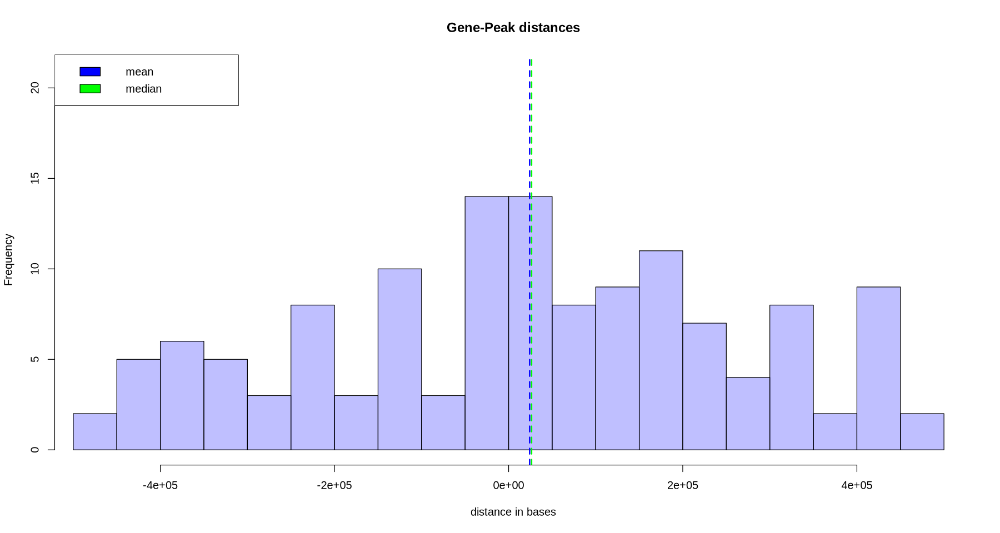

In [82]:
res_links <- linking_peaks_for_module_cluster(global_analysis_out, 
                                seed_genes, 
                                priorGRN, 
                                cluster="0",
                                gene_name_2_gene_id,
                                frag_path = "~/swarm/backend/data/multiome_data/GSM7821196_KTBpool6_Ashkenazi_jew_atac_fragments.tsv.gz")

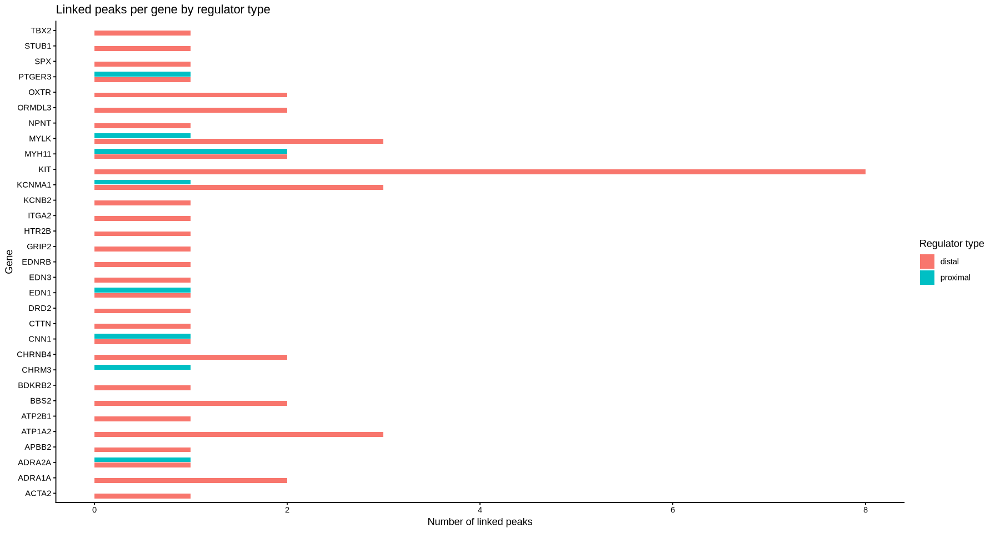

In [83]:
res_links$plot_links

In [84]:
coverage_plot_for_gene <- function(object, gene_name) {
    links <- Links(object[["peaks"]])
    links_gene <- links[links$gene == gene_name]
    print(links_gene)

    # the strand of the gene
    strand <- as.character(unique(strand(Annotation(res_links$object)[Annotation(res_links$object)$gene_name == "FOXA1"])))

    if ("+" %in% strand) {
        # if gene is on the + strand, upstream is left and downstream is right
        left_extend = abs(min(min(links_gene$distancePeakStartTSS),0))
        right_extend = abs(max(0,max(links_gene$distancePeakStartTSS)))
    } else {
        # if gene is on the - strand, upstream is right and downstream is left
        left_extend = abs(max(0,max(links_gene$distancePeakStartTSS)))
        right_extend = abs(min(0,min(links_gene$distancePeakStartTSS)))
    }
    
    p <- CoveragePlot(
        object = object,
        region = gene_name,
        features = gene_name,
        expression.assay = "RNA",
        #idents = idents.plot,
        extend.upstream = left_extend, # left
        extend.downstream = right_extend, # right
        annotation = TRUE,
        peaks = TRUE,
        tile = TRUE,
        links = TRUE
        )
    return(p)
}

GRanges object with 4 ranges and 8 metadata columns:
      seqnames              ranges strand |     score        gene
         <Rle>           <IRanges>  <Rle> | <numeric> <character>
  [1]     chr3 123766777-123884331      * | 0.0922169        MYLK
  [2]     chr3 123807888-123884331      * | 0.1832910        MYLK
  [3]     chr3 123816580-123884331      * | 0.1175521        MYLK
  [4]     chr3 123884105-123884331      * | 0.1150069        MYLK
                        peak    zscore      pvalue distancePeakStartTSS
                 <character> <numeric>   <numeric>            <numeric>
  [1] chr3-123766211-12376..   1.76614 0.038685808               116864
  [2] chr3-123807543-12380..   3.84924 0.000059242                75973
  [3] chr3-123815972-12381..   2.08803 0.018397549                67018
  [4] chr3-123883475-12388..   2.28316 0.011210447                 -528
      distancePeakEndTSS regulatorType
               <numeric>   <character>
  [1]             117995        distal
  

Warning message in asMethod(object):
"sparse->dense coercion: allocating vector of size 2.8 GiB"
Warning message:
"Removed 2 rows containing missing values or values outside the scale range
(`geom_segment()`)."


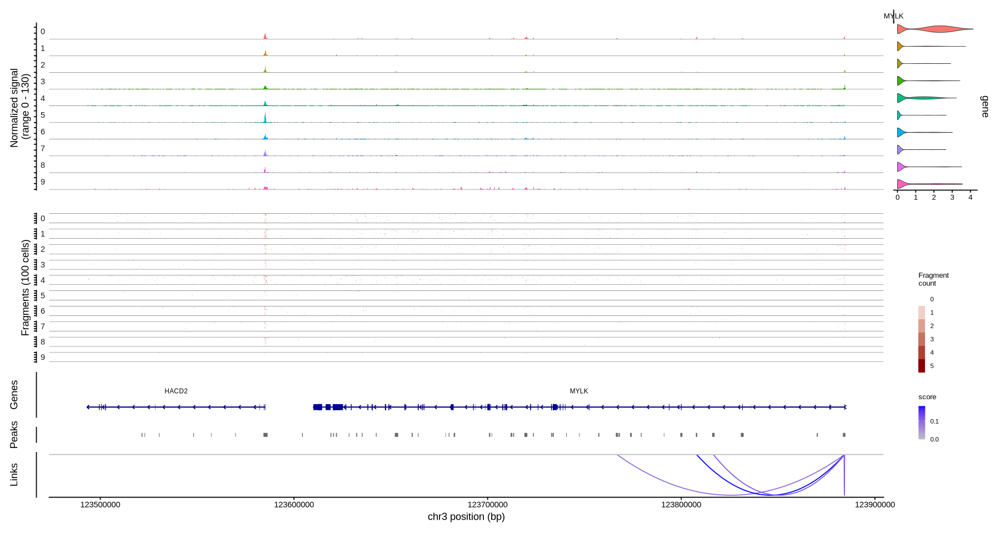

In [85]:
coverage_plot_for_gene(res_links$object, "MYLK")

# 2. identify cluster specific peaks

In [ ]:
#understand what peak stants does 
# adds object@misc$peak_stats
# adds filtered version: object@misc$df.stats.filtered

In [95]:
marker_df <- data.frame(
  cluster = res_links$marker_genes_cluster[["cluster"]],
  gene = res_links$marker_genes_cluster[["gene"]],
  annotation = res_links$marker_genes_cluster[["annotation"]],
  stringsAsFactors = FALSE
)

module_df <- data.frame(
  cluster ="0",
  gene = unique(res_links$priorGRN[["gene"]]),
  annotation = "module_genes",
  stringsAsFactors = FALSE
)

seeds_df <- data.frame(
  cluster = "0",
  gene = seed_genes,
  annotation = "seed_genes",
  stringsAsFactors = FALSE
)

seeds_for_peaks_stats <- rbind(marker_df, module_df, seeds_df)
seeds_for_peaks_stats <- seeds_for_peaks_stats[seeds_for_peaks_stats$gene %in% Links(res_links$object)$gene,]

In [152]:
length(intersect(unique(Links(object_w_net)$gene), seed_genes))

[1] 31

In [96]:

# seeds here needs: gene, cluster, annotation
res_peak_stats <-do_peak_stats(object=res_links$object, seeds=seeds_for_peaks_stats)

[1] "Writing peak stats table..."
[1] "Conducting cluster specific statistical tests..."
[1] "Calculating zero expression stats..."
[1] "Clustering peaks for bg distributions..."
[1] "Counting peaks per seed..."
[1] "Filtering peak stats..."
[1] "Number of linked peaks after filtering: 17"

cluster_specific 
              17 


In [101]:
unique(res_peak_stats@misc$peak_stats.filtered$gene)

[1] "MYLK"   "KCNMA1" "MYH11"

In [102]:
options(repr.plot.width=15, repr.plot.height=8)

In [103]:
View(head(peak_stats))

,cluster,peak,gene,annotation,regulatorType,signac.scores,signac.zscores,signac.pvalues,t-stat_highly.acc,p.value-t.test_highly.acc,⋯,promotersLinkedToSeed,distalPeaksLinkedToSeed,acc_cells_cluster,delta_expr_given_acc.same_peak_bg,delta_expr_given_acc.other_peaks.same_cluster,delta_expr_given_acc.other_peaks.all,pass_cluster_specific,pass_global,pass_any,pass_type
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<chr>,<chr>,<table[1d]>,<dbl>,<dbl>,<dbl>,<lgl[1d]>,<lgl>,<lgl[1d]>,<chr[1d]>
1,6,chr12-75208970-75209804,KCNC2,marker.pos.6,proximal,0.09850731,2.904337,1.840160e-03,4.367902,1.002159e-05,⋯,1,0,32,0.7095757,NA,NA,TRUE,FALSE,TRUE,cluster_specific
2,6,chr6-135180380-135183763,MYB,marker.pos.6,proximal,0.05600614,2.291502,1.096720e-02,4.640813,3.058988e-06,⋯,1,0,95,0.5045884,NA,NA,TRUE,FALSE,TRUE,cluster_specific
8,6,chr14-37594269-37596269,TTC6,marker.pos.6,proximal,0.05664315,2.133436,1.644447e-02,7.560189,6.626128e-13,⋯,1,2,96,0.8915914,-0.006410256,-0.039972654,TRUE,FALSE,TRUE,cluster_specific
12,6,chr14-37622140-37622969,TTC6,marker.pos.6,distal,0.05049869,2.333866,9.801360e-03,3.205396,7.834133e-04,⋯,1,2,21,0.9679487,0.118589744,0.025288562,TRUE,FALSE,TRUE,cluster_specific
16,6,chr6-24402481-24403631,DCDC2,marker.pos.6,distal,0.07582180,4.289125,8.968911e-06,3.058728,1.257088e-03,⋯,1,1,51,0.4038491,0.101419878,-0.002903066,TRUE,FALSE,TRUE,cluster_specific
18,6,chr2-149037786-149039241,LYPD6B,marker.pos.6,proximal,0.05160138,2.407705,8.026568e-03,5.581221,3.758744e-08,⋯,1,0,63,0.4046078,NA,NA,TRUE,FALSE,TRUE,cluster_specific


# 3. do local motif stats

- adds to:
    - object@misc$motifs.inProximalPeaks
    - object@misc$motifs.inDistalPeaks

In [104]:
res_local_motif_stats <- do_local_motif_stats(object=res_peak_stats, 
                               seeds=seeds_for_peaks_stats,
                               fragpath=NULL,
                               peaks_assay='peaks',
                               background_size=20, parallel=TRUE,
                               min_count=1, min_log2FC=1, max_t_stat=0, min_p_adjust=0.05)

Calculating motif enrichment

counting motifs in linked peaks



[1] 3
[1] 1
[1] "2026-04-08 21:33:23 CEST"


computing which motif ranges in proximal peaks associated to gene

computing motifs to gene



computing which motif ranges in distal peaks associated to gene

computing motifs to gene

No peak of this type linked to gene

computed motif count



[1] "chr10-77636810-77638795" "chr10-77636810-77638795"
[3] "chr10-77636810-77638795" "chr10-77636810-77638795"
[1] 2
[1] "2026-04-08 21:38:06 CEST"


computing which motif ranges in proximal peaks associated to gene

computing motifs to gene

computing which motif ranges in distal peaks associated to gene

computing motifs to gene

No peak of this type linked to gene

computed motif count



 [1] "chr16-15857870-15858601" "chr16-15857870-15858601"
 [3] "chr16-15857870-15858601" "chr16-15856768-15857482"
 [5] "chr16-15856768-15857482" "chr16-15856768-15857482"
 [7] "chr16-15856768-15857482" "chr16-15856768-15857482"
 [9] "chr16-15856768-15857482" "chr16-15857870-15858601"
[11] "chr16-15857870-15858601" "chr16-15857870-15858601"
[13] "chr16-15856768-15857482" "chr16-15856768-15857482"
[15] "chr16-15856768-15857482" "chr16-15857870-15858601"
[17] "chr16-15857870-15858601" "chr16-15857870-15858601"
[1] 3
[1] "2026-04-08 21:47:54 CEST"


computing which motif ranges in proximal peaks associated to gene

computing motifs to gene

computing which motif ranges in distal peaks associated to gene

computing motifs to gene

computed motif count



[1] "chr3-123883475-123884734" "chr3-123883475-123884734"
[3] "chr3-123883475-123884734" "chr3-123883475-123884734"
[5] "chr3-123883475-123884734" "chr3-123883475-123884734"
[7] "chr3-123883475-123884734" "chr3-123883475-123884734"
[9] "chr3-123883475-123884734"


counting motifs in promoter region

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chosen.

Multiple ranges found. First range chose

In [105]:
saveRDS(res_local_motif_stats, "res_local_motif_stats_smooth_muscle_contruction.rds")

In [122]:
res_local_motif_stats <- readRDS("res_local_motif_stats_smooth_muscle_contruction.rds")

In [123]:
head(res_local_motif_stats@misc$motif_stats)

,gene,cluster,proximal.motif_count,proximal.background_count,log2FC.proximal,t_stat.proximal,p_value.proximal,p_adjust.proximal,distal.motif_count,distal.background_count,⋯,footprint_score,bg_size,bg_footprint_mean,footprint.t_stat,footprint.p_value,footprint.p_value_adj,sd.flanks,bg_sd_mean,left_flank_nonzero_positions,right_flank_nonzero_positions
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>
7,KCNMA1,0,1,0.84,0.25,-1.1,0.13,1,0,0,⋯,-0.34150,20,0.04059,1.6120,0.061780,1.00,1.939,3.354,3,3
8,KCNMA1,0,1,0.84,0.25,-1.1,0.13,1,0,0,⋯,-0.34150,20,-0.49050,-0.5137,0.693300,1.00,1.939,3.927,3,3
9,KCNMA1,0,1,1,0,0.23,0.59,1,0,0,⋯,-0.34150,20,-0.40420,-0.2723,0.605900,1.00,1.939,3.314,3,3
10,KCNMA1,0,1,1,0,0.23,0.59,1,0,0,⋯,-0.34150,20,-0.31480,0.1105,0.456600,1.00,1.939,3.670,3,3
17,KCNMA1,0,10,6.5,0.62,-5.4,8.6e-07,0.00062,0,0,⋯,0.02615,20,0.07307,0.7680,0.226000,1.00,1.019,1.194,17,20
18,KCNMA1,0,10,6.5,0.62,-5.4,8.6e-07,0.00062,0,0,⋯,0.02615,20,0.29410,3.2520,0.002097,0.53,1.019,1.023,17,20


# 4. Map motifs to TFs

In [125]:

res_motifs_mapped<-add_motif_TF_mapping(res_local_motif_stats)

# 5. draw network

In [44]:
colnames(priorGRN)[colnames(priorGRN) == "gene_name"] <- "gene"
priorGRN

TF,Gene,Prior,Breast_netTS,Breast_net,gene
<chr>,<chr>,<int>,<int>,<dbl>,<chr>
ARID3A,ENSG00000000003,1,0,4.8115,TSPAN6
ARID3A,ENSG00000000003,1,0,4.8115,TE
CDC5L,ENSG00000000003,1,0,4.5396,TSPAN6
CDC5L,ENSG00000000003,1,0,4.5396,TE
CEBPA,ENSG00000000003,1,0,4.4718,TSPAN6
CEBPA,ENSG00000000003,1,0,4.4718,TE
CPEB1,ENSG00000000003,1,0,4.1023,TSPAN6
CPEB1,ENSG00000000003,1,0,4.1023,TE
CTCF,ENSG00000000003,1,0,4.1788,TSPAN6


In [127]:
saveRDS(res_motifs_mapped, "res_motifs_mapped_smooth_muscle_contraction.rds")

In [25]:
res_motifs_mapped<-readRDS("res_motifs_mapped_smooth_muscle_contraction.rds")

In [29]:
dim(priorGRN_full[priorGRN_full$gene %in% c("MYH11", "MYLK", "KCNMA1"),])

[1] 519   6

In [32]:
priorGRN_small <- read.csv("/nfs/data3/mopitas/mapra/TFnets/breast_tbl_priorGRN_smooth_muscle_contraction.csv")

In [34]:
unique(priorGRN_small$gene)

[1] "MYLK"    "CTTN"    "ACTA2"   "EDN3"    "BBS2"    "EDN2"    "CNN1"   
 [8] "SULF1"   "DOCK5"   "DRD2"    "KIT"     "CHRNB2"  "APBB2"   "ITGA2"  
[15] "ADORA2B" "OXTR"    "MIR143"

In [101]:
colnames(priorGRN_full)[colnames(priorGRN_full) == "gene_name"] <- "gene"
prior_to_vis <-priorGRN_full[priorGRN_full$gene %in% c(unique(priorGRN_small$gene), "MYH11", "KCNMA1") & priorGRN_full$Breast_net>4,]

In [75]:
unique(prior_to_vis$gene)

[1] "MYLK"    "CTTN"    "ACTA2"   "EDN3"    "BBS2"    "EDN2"    "CNN1"   
 [8] "MYH11"   "SULF1"   "DOCK5"   "DRD2"    "KCNMA1"  "KIT"     "CHRNB2" 
[15] "APBB2"   "ITGA2"   "ADORA2B" "OXTR"    "MIR143"

In [73]:
source("../multiome_methods/TF_activity.r")
source("../multiome_methods/binding_site_identification.r")

In [76]:
options(repr.plot.width=40, repr.plot.height=40)

In [109]:
str(object_w_net@misc$context_subNetwork$smc_larger_prior_net_larger,max.level=1)

'data.frame':	626 obs. of  6 variables:
 $ from    : chr  "ARX" "ASCL1" "ATF5" "BARHL2" ...
 $ to      : chr  "MYLK" "MYLK" "MYLK" "MYLK" ...
 $ color   : chr  "gray" "blue" "gray" "blue" ...
 $ priorTF : logi  TRUE TRUE TRUE TRUE TRUE TRUE ...
 $ reg_type: int  2 2 2 2 2 2 2 2 2 2 ...
 $ in.prom : int  1 3 1 3 3 1 1 3 1 3 ...


In [112]:
priorGRN_full[priorGRN_full$TF %in% c("ETV7", "FEV", "FOXB1", "NR2C2", "SOX14", "SOX9", "SOX4", "SP1","PRDM1","ZNF263") &
               priorGRN_full$gene %in%  c("MYLK", "MYH11"),]

,TF,Gene,Prior,Breast_netTS,Breast_net,gene
,<chr>,<chr>,<int>,<int>,<dbl>,<chr>
105034,ETV7,ENSG00000065534,1,0,3.4747,MYLK
105035,FEV,ENSG00000065534,1,0,3.9686,MYLK
105038,FOXB1,ENSG00000065534,1,0,3.0422,MYLK
105130,NR2C2,ENSG00000065534,1,0,3.4063,MYLK
105183,SOX14,ENSG00000065534,1,0,4.1862,MYLK
105189,SOX4,ENSG00000065534,1,0,3.7950,MYLK
105193,SOX9,ENSG00000065534,1,0,4.1996,MYLK
105194,SP1,ENSG00000065534,1,0,2.3744,MYLK
105239,ZNF263,ENSG00000065534,1,0,2.5955,MYLK


TF provided, plotting all motifs for TF



[1] "2026-04-09 10:30:01 CEST"
GRanges object with 1 range and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123883638-123883646      + |   11.0784
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-09 10:30:01 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


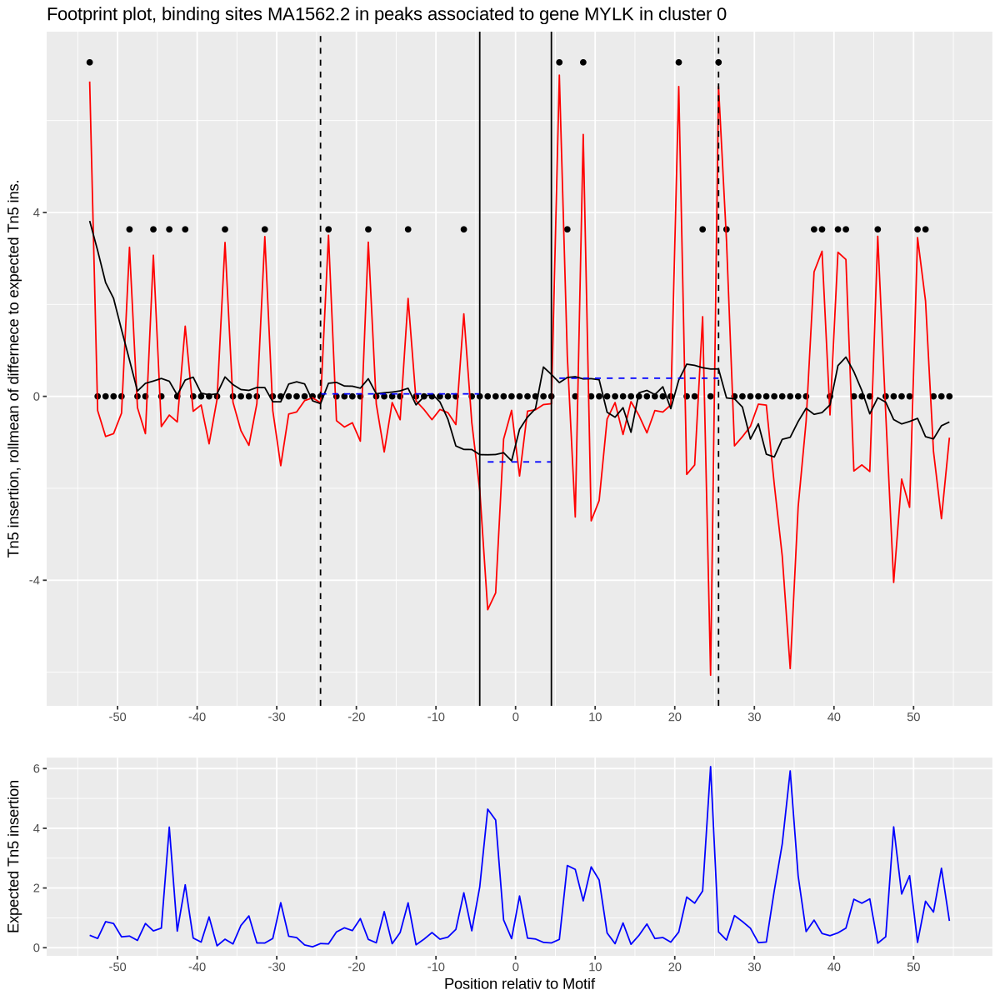

In [118]:

footprint_plots_by_TF(object=res_motifs_mapped, gene='MYLK', cluster=0, TF="SOX14", path=NULL)

TF provided, plotting all motifs for TF



[1] "2026-04-09 10:30:37 CEST"
GRanges object with 1 range and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123883653-123883660      - |   12.6565
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-09 10:30:37 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


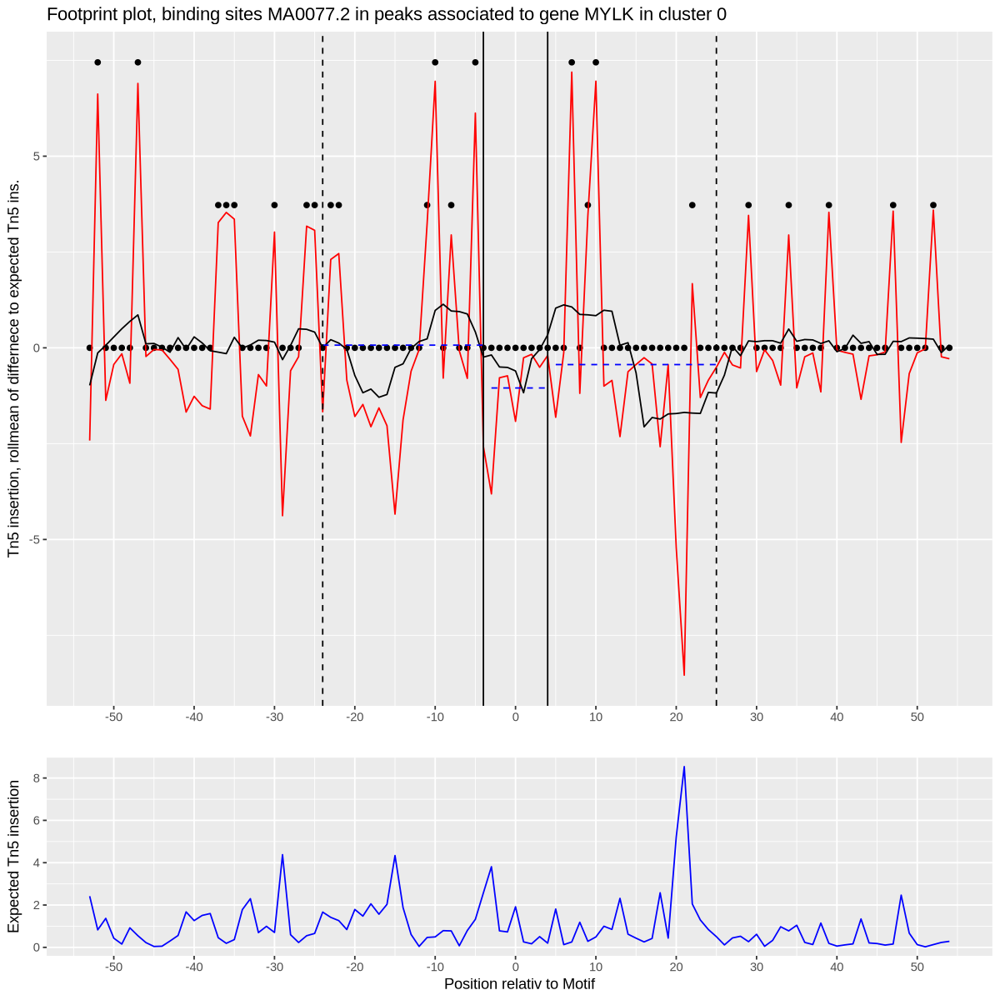

In [119]:

footprint_plots_by_TF(object=res_motifs_mapped, gene='MYLK', cluster=0, TF="SOX9", path=NULL)

TF provided, plotting all motifs for TF

computing motifs to gene



[1] "2026-04-09 10:49:12 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15858254-15858270      + |   16.6643
  [2]    chr16 15858254-15858270      - |   16.7563
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-09 10:49:13 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


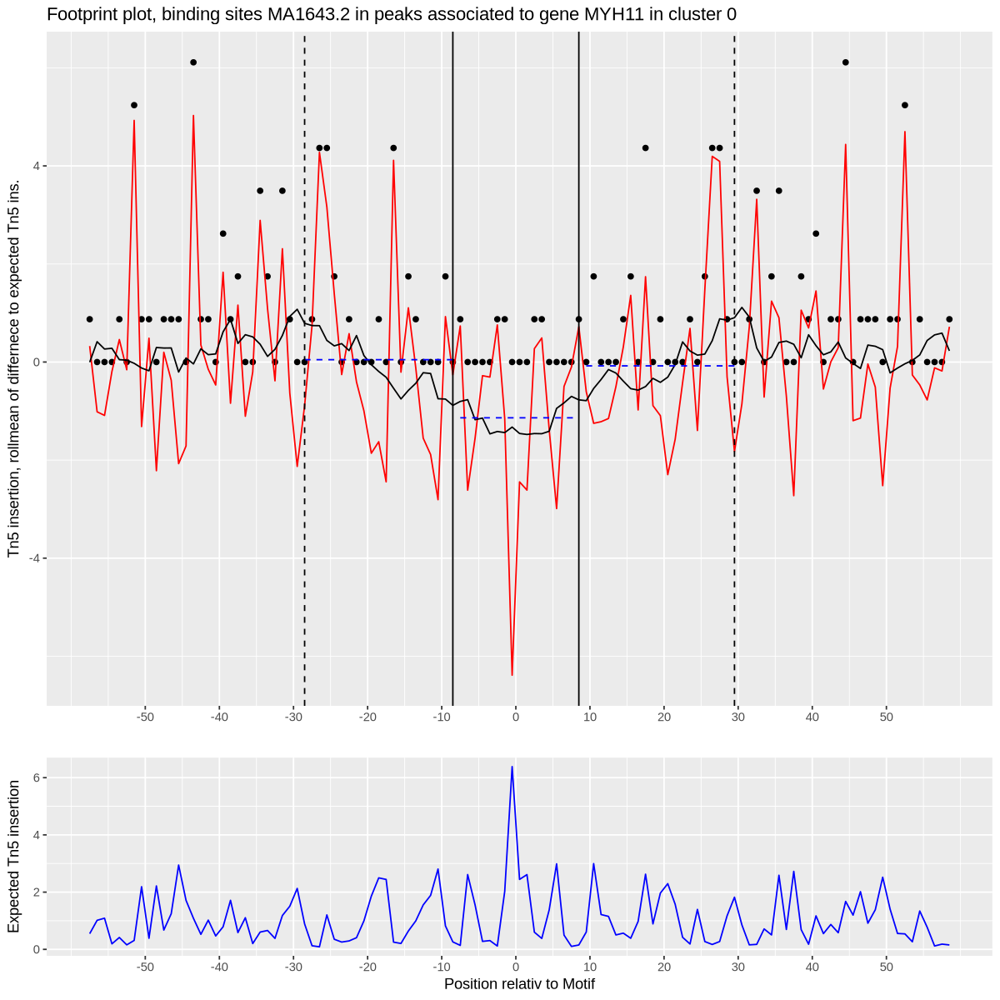

In [139]:


footprint_plots_by_TF(object=res_motifs_mapped, gene='MYH11', cluster=0, TF="NFIB", path=NULL)

TF provided, plotting all motifs for TF

computing motifs to gene



[1] "2026-04-09 10:47:31 CEST"
GRanges object with 6 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15857274-15857282      + |   14.1511
  [2]    chr16 15857274-15857282      - |   14.0468
  [3]    chr16 15807660-15807668      + |   14.0468
  [4]    chr16 15807781-15807789      + |   14.1511
  [5]    chr16 15807660-15807668      - |   14.1511
  [6]    chr16 15807781-15807789      - |   14.0468
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-09 10:47:31 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


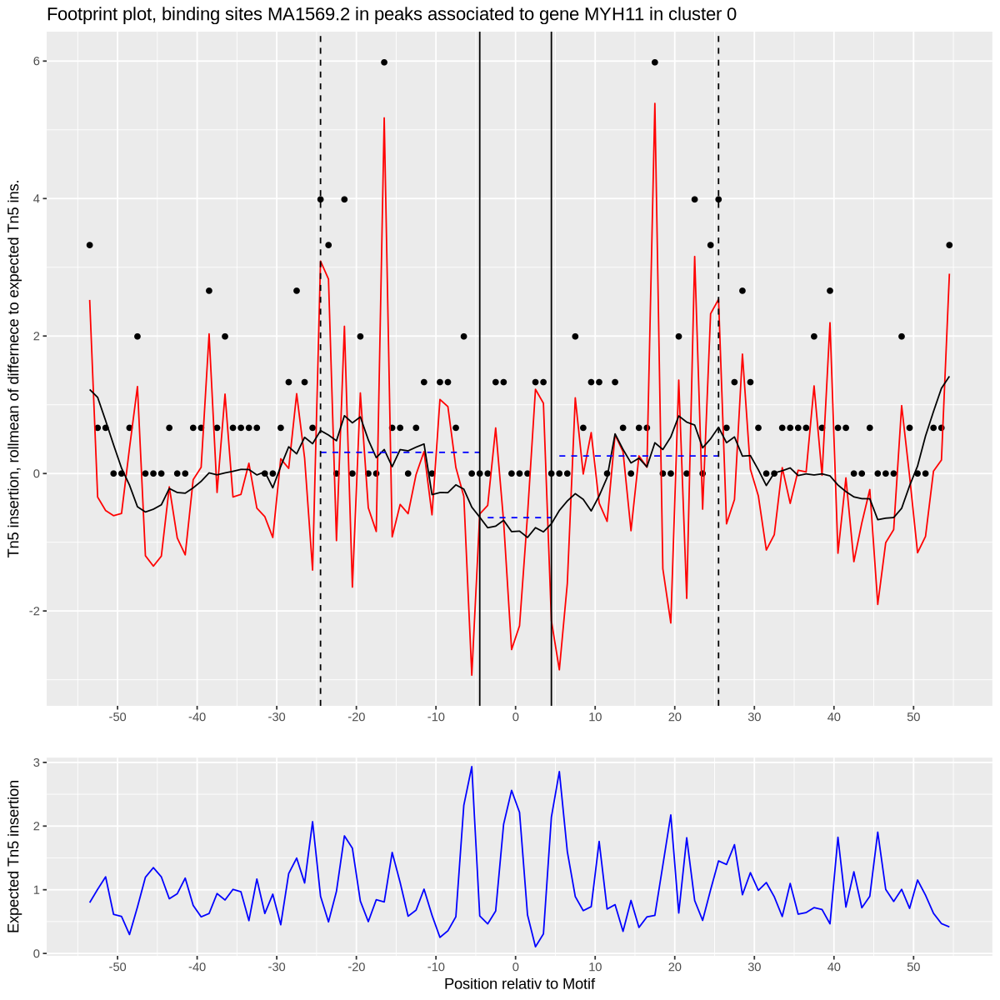

In [138]:

footprint_plots_by_TF(object=res_motifs_mapped, gene='MYH11', cluster=0, TF="TFAP2E", path=NULL)

TF provided, plotting all motifs for TF

computing motifs to gene



[1] "2026-04-09 10:53:06 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15857207-15857216      + |   11.4003
  [2]    chr16 15857237-15857246      + |   11.4003
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-09 10:53:06 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


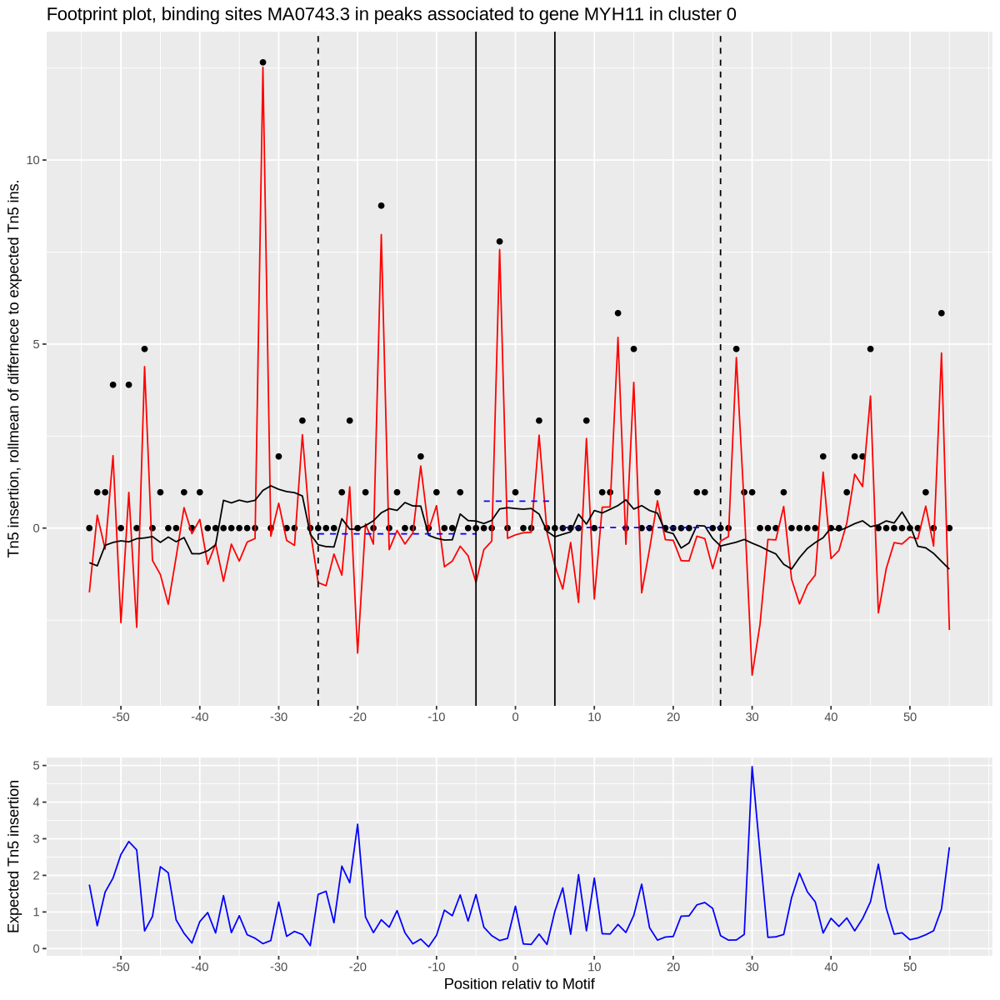

In [143]:
# red

footprint_plots_by_TF(object=res_motifs_mapped, gene='MYH11', cluster=0, TF="SCRT1", path=NULL)

In [117]:
object_w_net@misc$context_subNetwork$smc_larger_prior_net_larger[object_w_net@misc$context_subNetwork$smc_larger_prior_net_larger$color=="green" & 
                object_w_net@misc$context_subNetwork$smc_larger_prior_net_larger$priorTF==TRUE ,]$from

,from,to,color,priorTF,reg_type,in.prom
,<chr>,<chr>,<chr>,<lgl>,<int>,<int>
MYLK.25,ETV7,MYLK,green,TRUE,2,3
MYLK.26,FEV,MYLK,green,TRUE,2,1
MYLK.29,FOXB1,MYLK,green,TRUE,2,3
MYLK.106,NR2C2,MYLK,green,TRUE,1,3
MYLK.154,SOX14,MYLK,green,TRUE,1,1
MYLK.160,SOX4,MYLK,green,TRUE,1,3
MYLK.164,SOX9,MYLK,green,TRUE,1,3
MYLK.165,SP1,MYLK,green,TRUE,1,3
MYH11.93,PRDM1,MYH11,green,TRUE,1,3


In [141]:
object_w_net@misc$seedNetwork$smc_larger_prior_net_larger$MYH11[object_w_net@misc$seedNetwork$smc_larger_prior_net_larger$MYH11$result=="red",c('motif','p_value.proximal','p_adjust.proximal','distal.motif_count','log2FC.distal','t_stat.distal','p_value.distal','p_adjust.distal','promoter.motif_count','footprint_score', 'footprint.t_stat','footprint.p_value', 'left_flank_nonzero_positions','right_flank_nonzero_positions','promoter.or.enriched','TF', 'priorTF')]

,motif,p_value.proximal,p_adjust.proximal,distal.motif_count,log2FC.distal,t_stat.distal,p_value.distal,p_adjust.distal,promoter.motif_count,footprint_score,footprint.t_stat,footprint.p_value,left_flank_nonzero_positions,right_flank_nonzero_positions,promoter.or.enriched,TF,priorTF
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>,<lgl>,<chr>,<lgl>
MYH11.SCRT1.3175,MA0743.3,0.057,1,0,NA,NA,0,0,0,0.5595,-1.755000,0.9523000,8,8,TRUE,SCRT1,TRUE
MYH11.SCRT1.3176,MA0743.3,0.057,1,0,NA,NA,0,0,0,0.5595,-1.846000,0.9597000,8,8,TRUE,SCRT1,TRUE
MYH11.SCRT1.3177,MA0743.3,0.057,1,0,NA,NA,0,0,0,0.5595,-1.296000,0.8948000,8,8,TRUE,SCRT1,TRUE
MYH11.SCRT2.3178,MA0744.3,0.2,1,0,NA,NA,0,0,2,0.5595,0.555500,0.2925000,8,8,TRUE,SCRT2,TRUE
MYH11.SCRT2.3179,MA0744.3,0.2,1,0,NA,NA,0,0,2,0.5595,-2.944000,0.9958000,8,8,TRUE,SCRT2,TRUE
MYH11.SCRT2.3180,MA0744.3,0.2,1,0,NA,NA,0,0,2,0.5595,-1.810000,0.9570000,8,8,TRUE,SCRT2,TRUE
MYH11.SMAD2.3190,MA1964.2,1,1,0,NA,NA,0,0,7,-0.1569,4.287000,0.0001992,8,13,TRUE,SMAD2,TRUE
MYH11.SMAD2.3191,MA1964.2,1,1,0,NA,NA,0,0,7,-0.1569,3.274000,0.0019980,8,13,TRUE,SMAD2,TRUE
MYH11.SMAD2.3192,MA1964.2,1,1,0,NA,NA,0,0,7,-0.1569,2.956000,0.0040530,8,13,TRUE,SMAD2,TRUE


In [137]:
object_w_net@misc$seedNetwork$smc_larger_prior_net_larger$MYH11[object_w_net@misc$seedNetwork$smc_larger_prior_net_larger$MYH11$result=="green",c('motif','p_value.proximal','p_adjust.proximal','distal.motif_count','log2FC.distal','t_stat.distal','p_value.distal','p_adjust.distal','promoter.motif_count','footprint_score', 'footprint.t_stat','footprint.p_value', 'left_flank_nonzero_positions','right_flank_nonzero_positions','promoter.or.enriched','TF')]

,motif,p_value.proximal,p_adjust.proximal,distal.motif_count,log2FC.distal,t_stat.distal,p_value.distal,p_adjust.distal,promoter.motif_count,footprint_score,footprint.t_stat,footprint.p_value,left_flank_nonzero_positions,right_flank_nonzero_positions,promoter.or.enriched,TF
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>,<lgl>,<chr>
MYH11.NFIC.1459,MA0119.1,0.98,1,0,NA,NA,0,0,0,-1.4530,5.027,3.742e-05,10,10,TRUE,NFIC
MYH11.NFIC.1460,MA0119.1,0.98,1,0,NA,NA,0,0,0,-1.4530,5.561,1.154e-05,10,10,TRUE,NFIC
MYH11.NFIC.1461,MA0119.1,0.98,1,0,NA,NA,0,0,0,-1.4530,5.720,8.178e-06,10,10,TRUE,NFIC
MYH11.TLX1.1459,MA0119.1,0.98,1,0,NA,NA,0,0,0,-1.4530,5.027,3.742e-05,10,10,TRUE,TLX1
MYH11.TLX1.1460,MA0119.1,0.98,1,0,NA,NA,0,0,0,-1.4530,5.561,1.154e-05,10,10,TRUE,TLX1
MYH11.TLX1.1461,MA0119.1,0.98,1,0,NA,NA,0,0,0,-1.4530,5.720,8.178e-06,10,10,TRUE,TLX1
MYH11.EWSR1-FLI1.1465,MA0149.1,1,1,0,NA,NA,0,0,0,-0.6138,10.390,1.410e-09,14,12,TRUE,EWSR1-FLI1
MYH11.EWSR1-FLI1.1466,MA0149.1,1,1,0,NA,NA,0,0,0,-0.6138,4.385,1.592e-04,14,12,TRUE,EWSR1-FLI1
MYH11.EWSR1-FLI1.1467,MA0149.1,1,1,0,NA,NA,0,0,0,-0.6138,11.270,3.727e-10,14,12,TRUE,EWSR1-FLI1


In [135]:
object_w_net@misc$seedNetwork$smc_larger_prior_net_larger$MYLK[object_w_net@misc$seedNetwork$smc_larger_prior_net_larger$MYLK$result=="green",c('motif','p_value.proximal','p_adjust.proximal','distal.motif_count','log2FC.distal','t_stat.distal','p_value.distal','p_adjust.distal','promoter.motif_count','footprint_score', 'footprint.t_stat','footprint.p_value', 'left_flank_nonzero_positions','right_flank_nonzero_positions','promoter.or.enriched','TF')]

,motif,p_value.proximal,p_adjust.proximal,distal.motif_count,log2FC.distal,t_stat.distal,p_value.distal,p_adjust.distal,promoter.motif_count,footprint_score,footprint.t_stat,footprint.p_value,left_flank_nonzero_positions,right_flank_nonzero_positions,promoter.or.enriched,TF
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>,<lgl>,<chr>
MYLK.SOX14.5375,MA1562.2,1.5e-05,0.011,0,-Inf,8.8,1,1,0,-1.6050,4.643,8.860e-05,4,5,TRUE,SOX14
MYLK.SOX14.5376,MA1562.2,1.5e-05,0.011,0,-Inf,8.8,1,1,0,-1.6050,5.153,2.828e-05,4,5,TRUE,SOX14
MYLK.SOX9.5386,MA0077.2,0.0011,0.79,0,-Inf,7.5,1,1,4,-1.1020,5.426,1.548e-05,6,4,TRUE,SOX9
MYLK.SOX9.5387,MA0077.2,0.0011,0.79,0,-Inf,7.5,1,1,4,-1.1020,5.991,4.580e-06,6,4,TRUE,SOX9
MYLK.BCL6B.3731,MA0731.1,1.5e-10,1.1e-07,0,-Inf,12,1,1,0,-0.5513,5.428,1.541e-05,14,13,TRUE,BCL6B
MYLK.SP1.4040,MA0079.5,1,1,0,-Inf,13,1,1,7,-0.8394,5.058,3.490e-05,16,18,TRUE,SP1
MYLK.NR2C2.5129,MA0504.2,1,1,1,-1.5,8.1,1,1,3,-0.5763,4.572,1.042e-04,9,10,TRUE,NR2C2
MYLK.PRDM9.5270,MA1723.2,1,1,2,-2.6,10,1,1,2,-0.4543,5.165,2.752e-05,16,16,TRUE,PRDM9
MYLK.SOX13.5372,MA1120.2,0.13,1,1,-1,5,1,1,0,-0.2652,4.889,5.090e-05,7,10,TRUE,SOX13


In [129]:
colnames(object_w_net@misc$seedNetwork$smc_larger_prior_net_larger$MYLK[object_w_net@misc$seedNetwork$smc_larger_prior_net_larger$MYLK$result=="green",])

[1] "gene"                          "cluster"                      
 [3] "proximal.motif_count"          "proximal.background_count"    
 [5] "log2FC.proximal"               "t_stat.proximal"              
 [7] "p_value.proximal"              "p_adjust.proximal"            
 [9] "distal.motif_count"            "distal.background_count"      
[11] "log2FC.distal"                 "t_stat.distal"                
[13] "p_value.distal"                "p_adjust.distal"              
[15] "motif"                         "promoter.motif_count"         
[17] "footprint_score"               "bg_size"                      
[19] "bg_footprint_mean"             "footprint.t_stat"             
[21] "footprint.p_value"             "footprint.p_value_adj"        
[23] "sd.flanks"                     "bg_sd_mean"                   
[25] "left_flank_nonzero_positions"  "right_flank_nonzero_positions"
[27] "promoter.or.enriched"          "TF"                           
[29] "result"                        "priorTF"

In [ ]:
object_w_net@misc$context_subNetwork$smc_larger_prior_net_larger[object_w_net@misc$context_subNetwork$smc_larger_prior_net_larger$color=="green",]

,from,to,color,priorTF,reg_type,in.prom
,<chr>,<chr>,<chr>,<lgl>,<int>,<int>
MYLK.44,SOX14,MYLK,green,TRUE,1,1
MYLK.48,SOX9,MYLK,green,TRUE,1,3
MYLK.75,BCL6B,MYLK,green,FALSE,1,1
MYLK.83,SP1,MYLK,green,FALSE,1,3
MYLK.101,NR2C2,MYLK,green,FALSE,1,3
MYLK.109,PRDM9,MYLK,green,FALSE,1,3
MYLK.111,SOX13,MYLK,green,FALSE,1,1
MYLK.112,SOX15,MYLK,green,FALSE,1,3
MYLK.113,SOX4,MYLK,green,FALSE,1,3


In [155]:
write.csv(priorGRN_full[priorGRN_full$gene %in% c('MYLK', 'MYH11','KCNMA1') & priorGRN_full$Breast_net>4,], "prior_net_breast_smc_final.csv")

[1] "include_motifs_for_seed: MYLK 0"
[1] "motif stats for seed:MYLK0"
[1] 336  26
[1] "motif stats for seed:MYLK0"
[1] 162  26


found and passed 124 Transcription factors that bind in regulatory regions for seed MYLK 0



[1] "ASCL1"
[1] "CIC"
[1] "CREB3L2"
[1] "CREM"
[1] "ETV5"
[1] "GATA3"
[1] "GATA4"
[1] "GLI2"
[1] "GSC2"
[1] "HBP1"
[1] "HES7"


Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

computing 10 background footprints

Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cu

[1] "HLTF"
[1] "HNF4A"
[1] "HOXA13"
[1] "HOXA5"
[1] "HOXB1"


Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

computing 10 background footprints

Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cu

... (157 outputs left out)

colors are numbers at the end: is this going wrong here already?



  [1] gray   gray   gray   gray   blue   blue   blue   blue   red    blue  
 [11] blue   blue   blue   gray   blue   blue   blue   blue   blue   blue  
 [21] gray   blue   blue   blue   blue   blue   blue   blue   blue   blue  
 [31] gray   gray   blue   blue   blue   blue   gray   blue   blue   gray  
 [41] blue   blue   gray   gray   blue   blue   blue   blue   gray   gray  
 [51] red    red    red    yellow yellow yellow red    red    red    red   
 [61] green  red    red    red    yellow red    red    red    red    red   
 [71] red    red    yellow yellow yellow red    red    red    red    red   
 [81] red    green  red    red    red    green  green  red    red    red   
 [91] red    yellow green  green  red    red    red    red    red    green 
[101] green 
Levels: green yellow red blue black gray


edge_color at the end of get_subnetwork



  [1] gray   gray   gray   gray   blue   blue   blue   blue   red    blue  
 [11] blue   blue   blue   gray   blue   blue   blue   blue   blue   blue  
 [21] gray   blue   blue   blue   blue   blue   blue   blue   blue   blue  
 [31] gray   gray   blue   blue   blue   blue   gray   blue   blue   gray  
 [41] blue   blue   gray   gray   blue   blue   blue   blue   gray   gray  
 [51] red    red    red    yellow yellow yellow red    red    red    red   
 [61] green  red    red    red    yellow red    red    red    red    red   
 [71] red    red    yellow yellow yellow red    red    red    red    red   
 [81] red    green  red    red    red    green  green  red    red    red   
 [91] red    yellow green  green  red    red    red    red    red    green 
[101] green 
Levels: green yellow red blue black gray
                 from     to  color priorTF reg_type in.prom
MYLK.1          ASCL1   MYLK   blue    TRUE        2       3
MYLK.2            CIC   MYLK   gray    TRUE        2       1
MYL

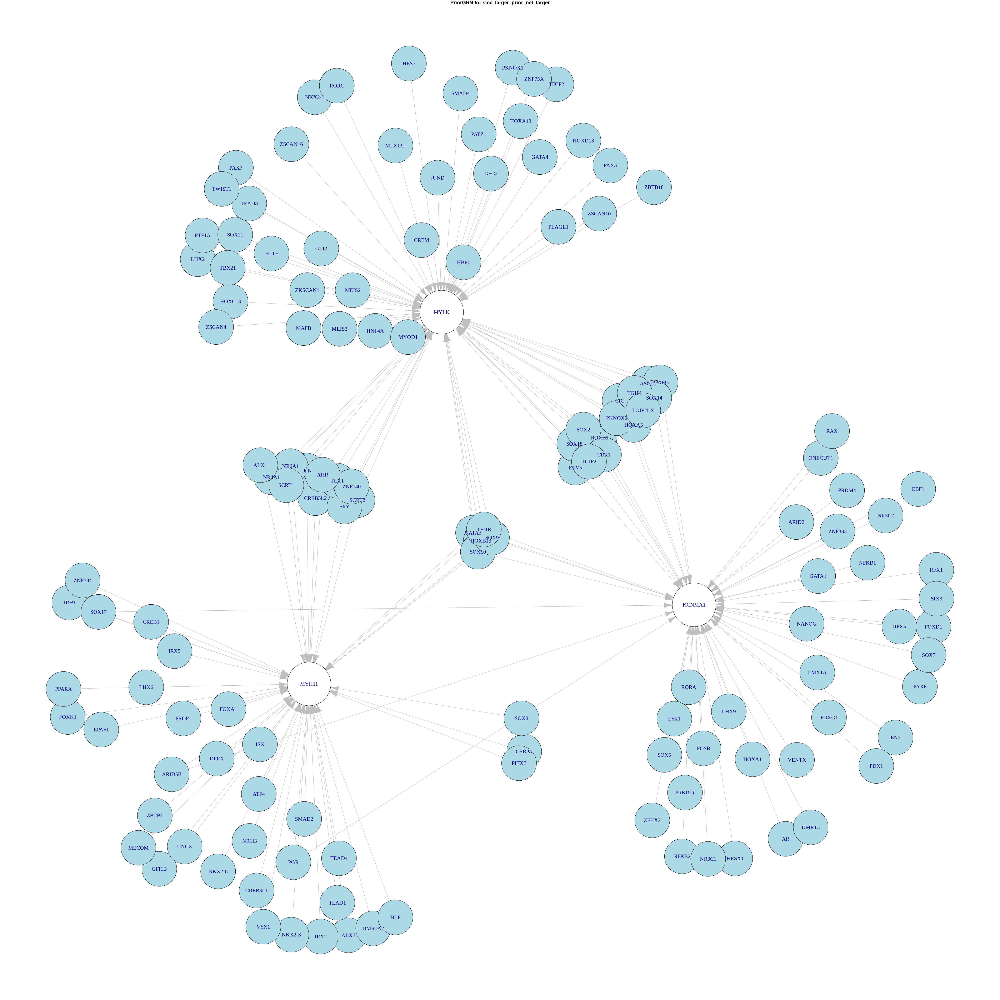

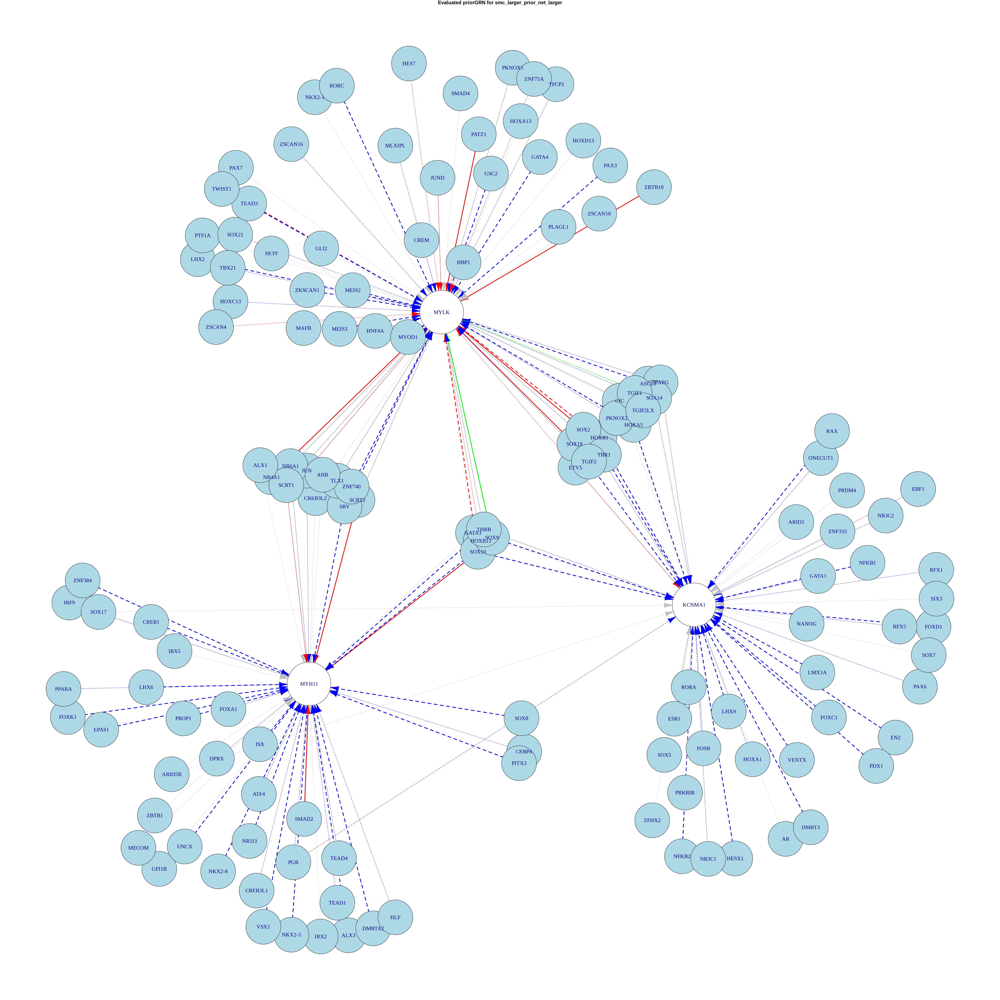

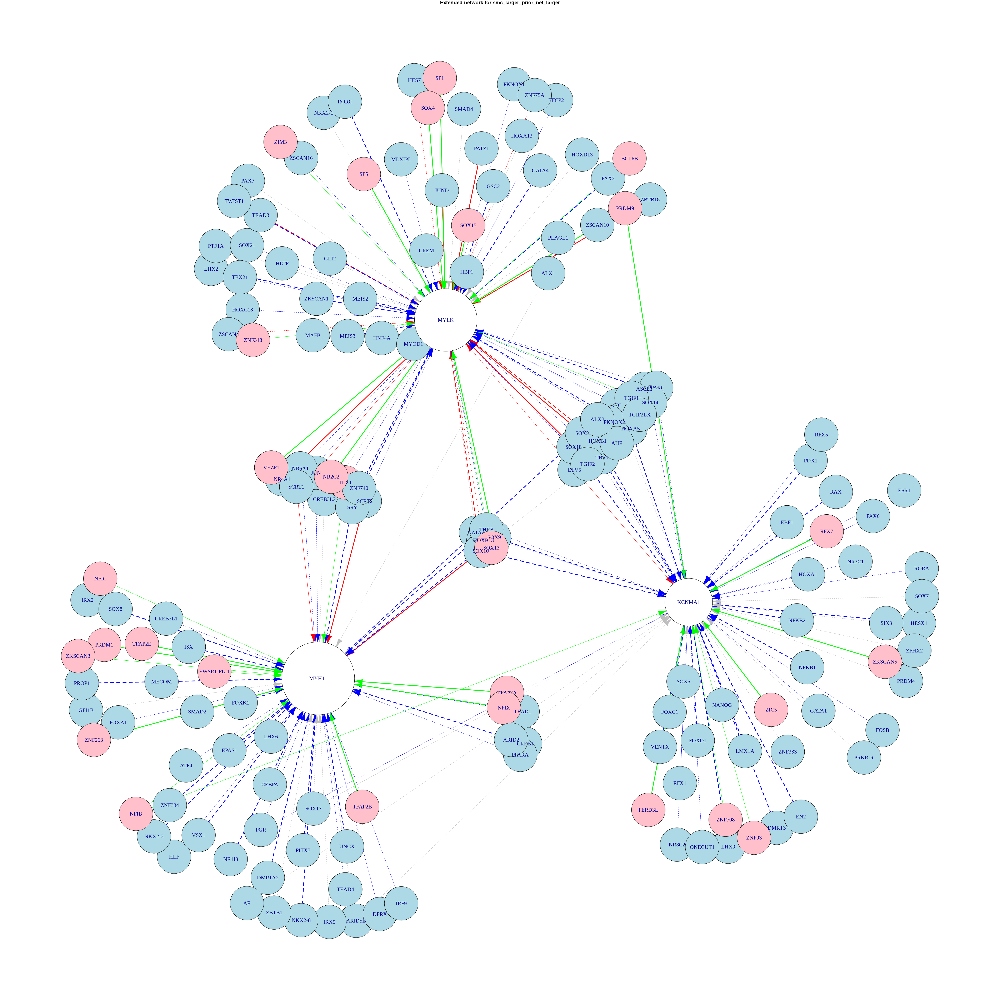

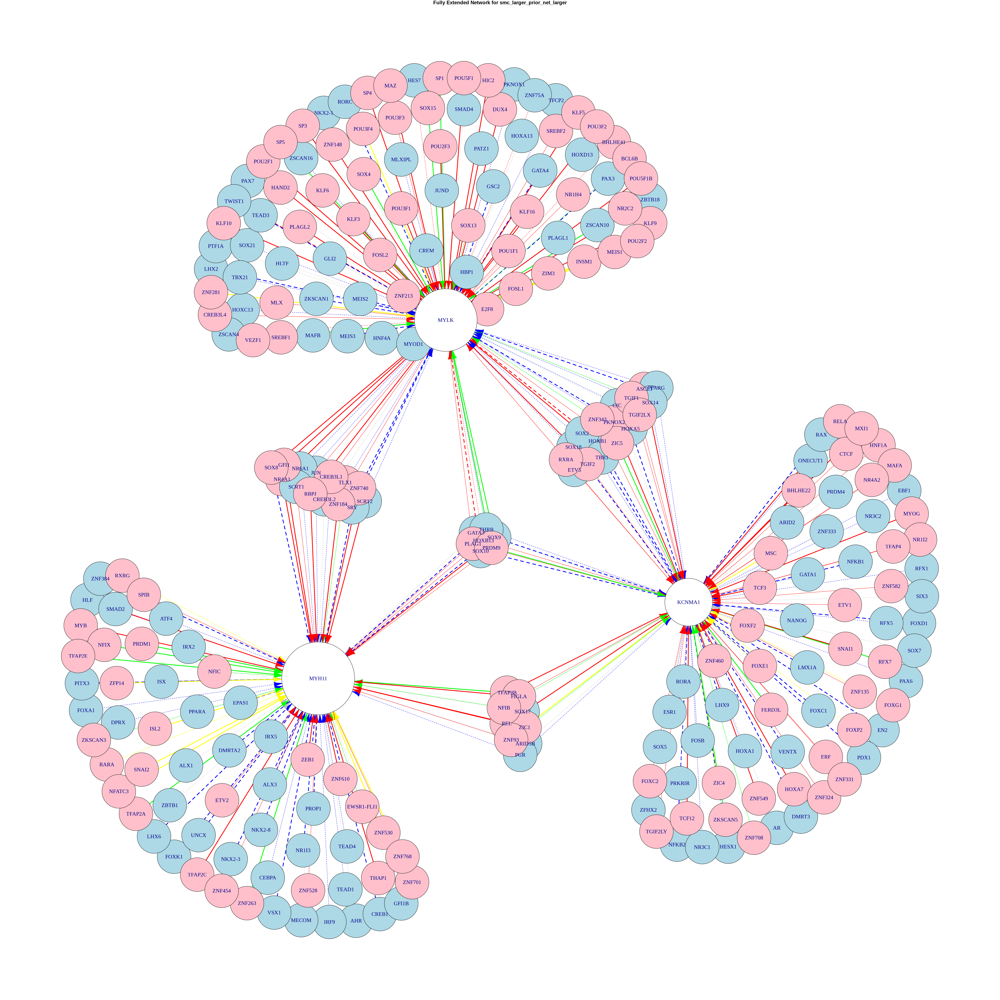

In [115]:

object_w_net<-draw_subNetwork_for_context(object=res_motifs_mapped, 
        gene_list= c('MYLK', 'MYH11','KCNMA1'),
        cluster="0", 
        priorGRN=priorGRN_full[priorGRN_full$gene %in% c('MYLK', 'MYH11','KCNMA1') & priorGRN_full$Breast_net>4,],
        context_name='smc_larger_prior_net_larger',resolution=20,pointsize=50, sd=5,score=0
        )

In [106]:
priorGRN_full[priorGRN_full$TF=="NR2C2",]

,TF,Gene,Prior,Breast_netTS,Breast_net,gene
,<chr>,<chr>,<int>,<int>,<dbl>,<chr>
42925,NR2C2,ENSG00000018625,1,0,3.3625,ATP1A2
105130,NR2C2,ENSG00000065534,1,0,3.4063,MYLK
114498,NR2C2,ENSG00000067560,1,0,4.1799,RHOA
128544,NR2C2,ENSG00000070961,1,0,3.2242,ATP2B1
326136,NR2C2,ENSG00000105664,1,0,4.2648,COMP
481123,NR2C2,ENSG00000117971,1,0,3.3315,CHRNB4
644866,NR2C2,ENSG00000133019,1,0,3.3438,CHRM3
1090273,NR2C2,ENSG00000164850,1,0,3.1550,GPER1
1383233,NR2C2,ENSG00000183963,1,0,3.8128,SMTN


[1] "include_motifs_for_seed: MYLK 0"
[1] "motif stats for seed:MYLK0"
[1] 336  26
[1] "motif stats for seed:MYLK0"
[1] 162  26


found and passed 72 Transcription factors that bind in regulatory regions for seed MYLK 0



[1] "CREB3L2"
[1] "GSC2"
[1] "HES7"


Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

computing 10 background footprints

Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cu

[1] "MEIS2"
[1] "PAX3"
[1] "PPARG"
[1] "SCRT2"
[1] "TBX21"
[1] "TFCP2"
[1] "INSM1"
[1] "PLAG1"
[1] "DUX4"
[1] "SREBF1"
[1] "SREBF2"
[1] "KLF5"
[1] "BHLHE41"
[1] "MLX"
[1] "BCL6B"
[1] "KLF16"
[1] "POU3F2"
[1] "POU3F3"
[1] "POU3F4"
[1] "POU5F1B"
[1] "ZNF184"
[1] "ZNF213"
[1] "SP1"
[1] "SP4"
[1] "KLF10"
[1] "SOX18"
[1] "CREB3L1"
[1] "CREB3L4.1"
[1] "E2F8"
[1] "FOSL1"
[1] "JUND.1"
[1] "FOSL2"
[1] "JUN.1"
[1] "SOX2"
[1] "GFI1"
[1] "HAND2"
[1] "HIC2"
[1] "KLF3"
[1] "KLF6"
[1] "KLF9"
[1] "MAZ"
[1] "MEIS1"
[1] "NR1H4"
[1] "RXRA"


Warning message in filtered.enrichment$footprint.p_value_adj[filtered.enrichment$gene == :
"number of items to replace is not a multiple of replacement length"


... (69 outputs left out)

colors are numbers at the end: is this going wrong here already?



 [1] black black black black black black black black black black black black
[13] black black black black black black
Levels: green yellow red blue black gray


edge_color at the end of get_subnetwork



 [1] black black black black black black black black black black black black
[13] black black black black black black
Levels: green yellow red blue black gray
                from     to  color priorTF reg_type in.prom
MYLK.1       CREB3L2   MYLK   gray    TRUE        2       1
MYLK.2          GSC2   MYLK   blue    TRUE        2       3
MYLK.3          HES7   MYLK  green    TRUE        2       1
MYLK.4         MEIS2   MYLK   blue    TRUE        2       3
MYLK.5          PAX3   MYLK   blue    TRUE        2       3
MYLK.6         PPARG   MYLK   blue    TRUE        2       1
MYLK.7         SCRT2   MYLK   blue    TRUE        2       1
MYLK.8         TBX21   MYLK   blue    TRUE        2       1
MYLK.9         TFCP2   MYLK   blue    TRUE        2       1
MYLK.10        INSM1   MYLK yellow   FALSE        1       3
MYLK.11        PLAG1   MYLK    red   FALSE        1       1
MYLK.12         DUX4   MYLK    red   FALSE        1       3
MYLK.13       SREBF1   MYLK    red   FALSE        1       1
M

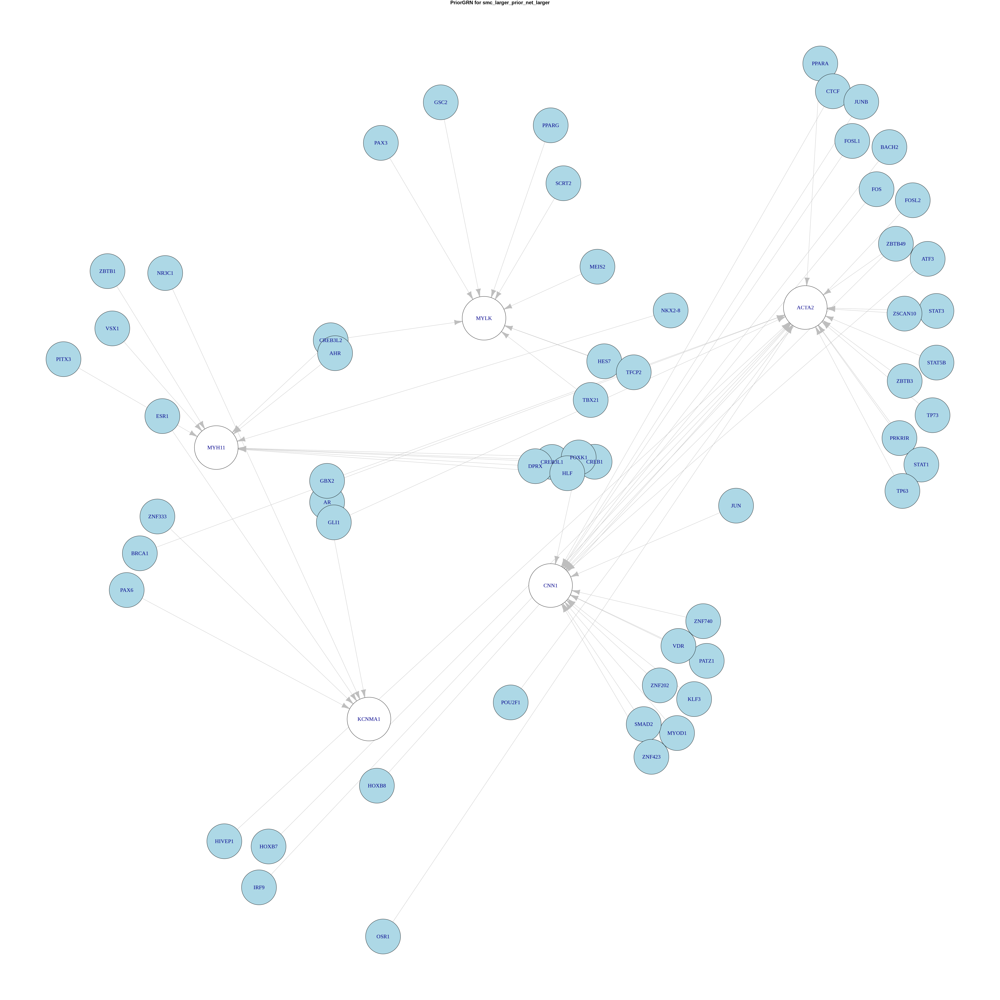

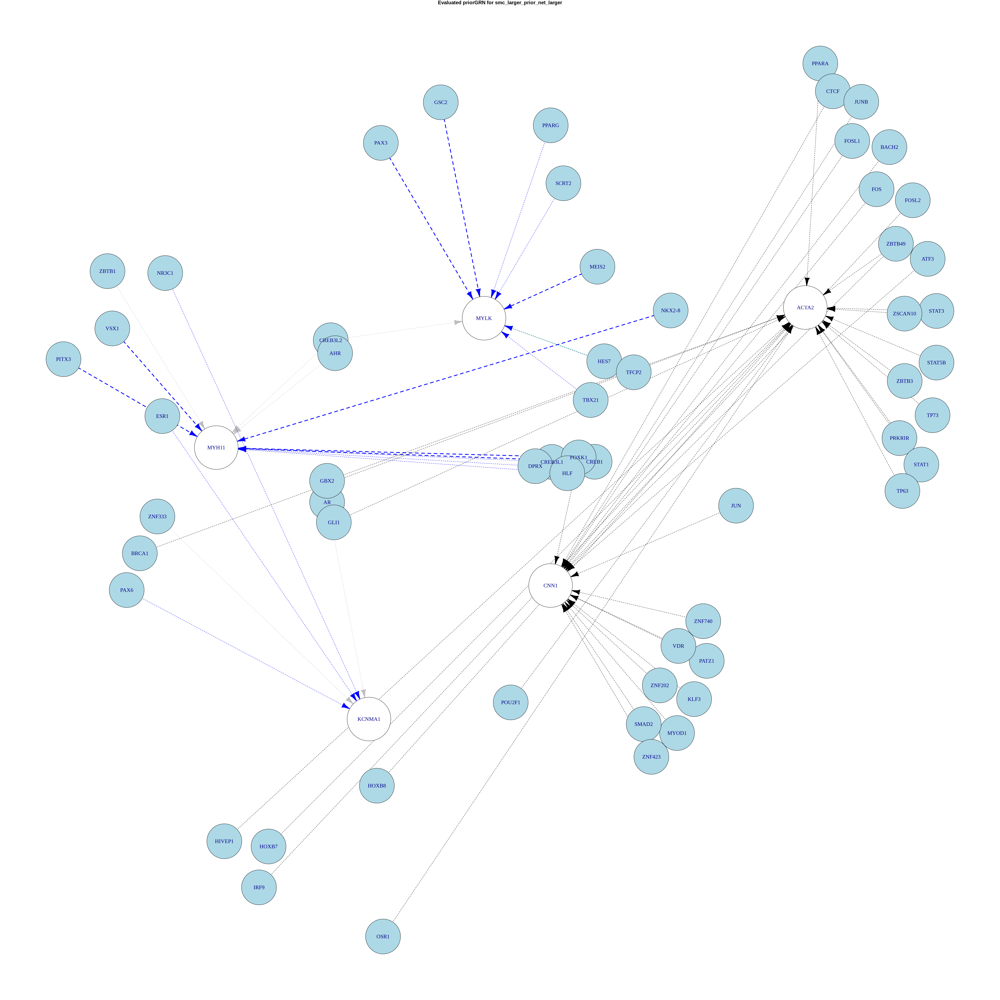

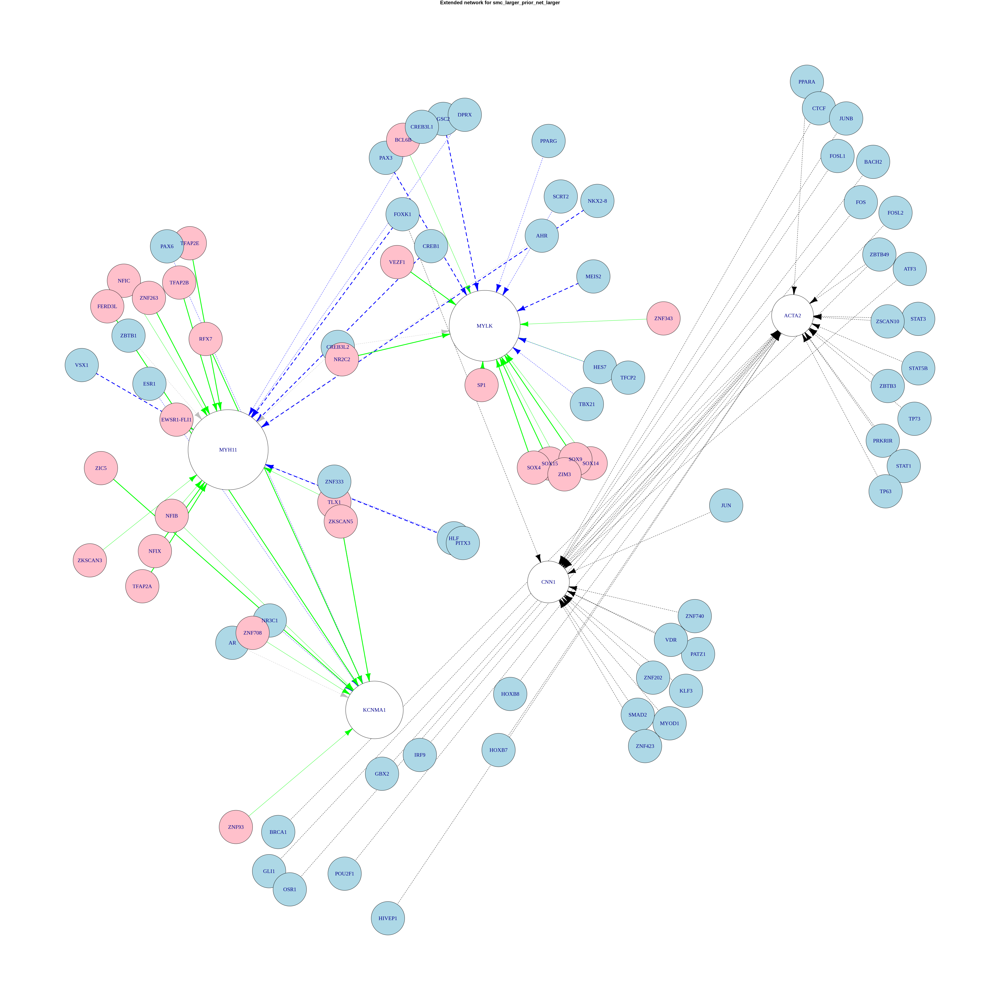

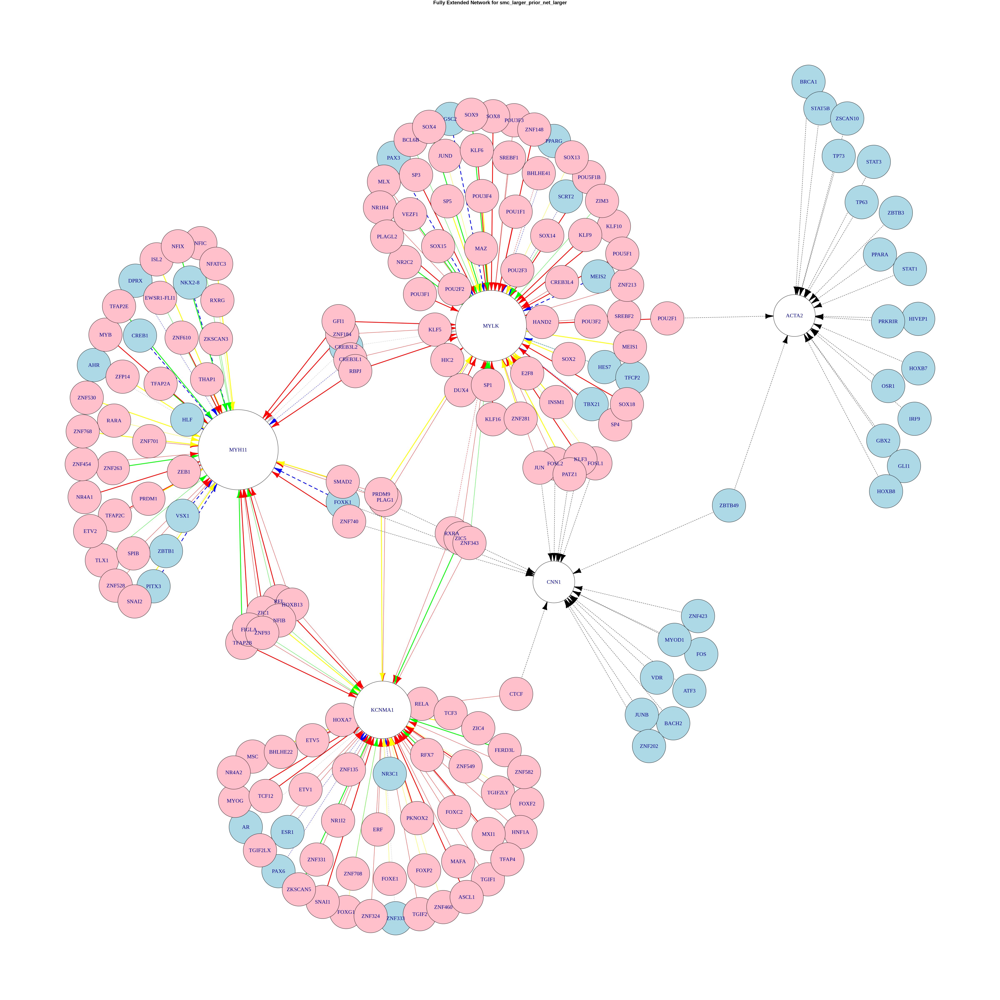

In [77]:
object_w_net<-draw_subNetwork_for_context(object=res_motifs_mapped, 
        gene_list= c('MYLK', 'MYH11','KCNMA1','ACTG2','ACTA2','CNN1'),
        cluster="0", 
        priorGRN=priorGRN_full[priorGRN_full$gene %in% c('MYLK', 'MYH11','KCNMA1','ACTG2','ACTA2','CNN1'),],
        context_name='smc_larger_prior_net_larger',resolution=20,pointsize=50, sd=5,score=-0.5
        )

[1] "include_motifs_for_seed: KCNMA1 0"
[1] "motif stats for seed:KCNMA10"
[1] 252  26
[1] "motif stats for seed:KCNMA10"
[1] 86 26


found and passed 53 Transcription factors that bind in regulatory regions for seed KCNMA1 0



[1] "REL"
[1] "RELA"
[1] "PLAG1"
[1] "FOXG1"
[1] "MSC"
[1] "ZIC1"
[1] "PKNOX2"
[1] "TGIF1"
[1] "TGIF2"
[1] "TFAP2B"
[1] "FERD3L"
[1] "TGIF2LX"
[1] "TGIF2LY"
[1] "ZNF135"
[1] "ZNF460"
[1] "ASCL1"
[1] "ASCL1.1"
[1] "BHLHE22.1"
[1] "CTCF.1"
[1] "ERF"


adding distal and not enriched motif_stats for:



[1] "KCNMA1 0"


Detected 160 cores. Using 20 cores for parallel processing.

Attempting parallelized processing for 5 Seed-motif pairs. Using 20 cores.



... (125 outputs left out)

colors are numbers at the end: is this going wrong here already?



 [1] gray   blue   green  blue   blue   blue   blue   blue   blue   yellow
[11] red    red    red    red    red    red    red    green  red    red   
[21] red    yellow red    red    red    green  red    red    red    red   
[31] red    red    yellow yellow red    red    yellow red    red    red   
[41] red    red    red    red    yellow red    red    green  yellow red   
[51] red    red    yellow red    red    red    yellow red    yellow green 
[61] green  green  red    green  red    yellow green  red    green  red   
[71] yellow green 
Levels: green yellow red blue black gray


edge_color at the end of get_subnetwork



 [1] gray   blue   green  blue   blue   blue   blue   blue   blue   yellow
[11] red    red    red    red    red    red    red    green  red    red   
[21] red    yellow red    red    red    green  red    red    red    red   
[31] red    red    yellow yellow red    red    yellow red    red    red   
[41] red    red    red    red    yellow red    red    green  yellow red   
[51] red    red    yellow red    red    red    yellow red    yellow green 
[61] green  green  red    green  red    yellow green  red    green  red   
[71] yellow green 
Levels: green yellow red blue black gray
                from     to  color priorTF reg_type in.prom
KCNMA1.1         REL KCNMA1    red   FALSE        1       3
KCNMA1.2        RELA KCNMA1    red   FALSE        1       3
KCNMA1.3       PLAG1 KCNMA1    red   FALSE        1       1
KCNMA1.4       FOXG1 KCNMA1 yellow   FALSE        1       1
KCNMA1.5         MSC KCNMA1 yellow   FALSE        1       3
KCNMA1.6        ZIC1 KCNMA1 yellow   FALSE        1    

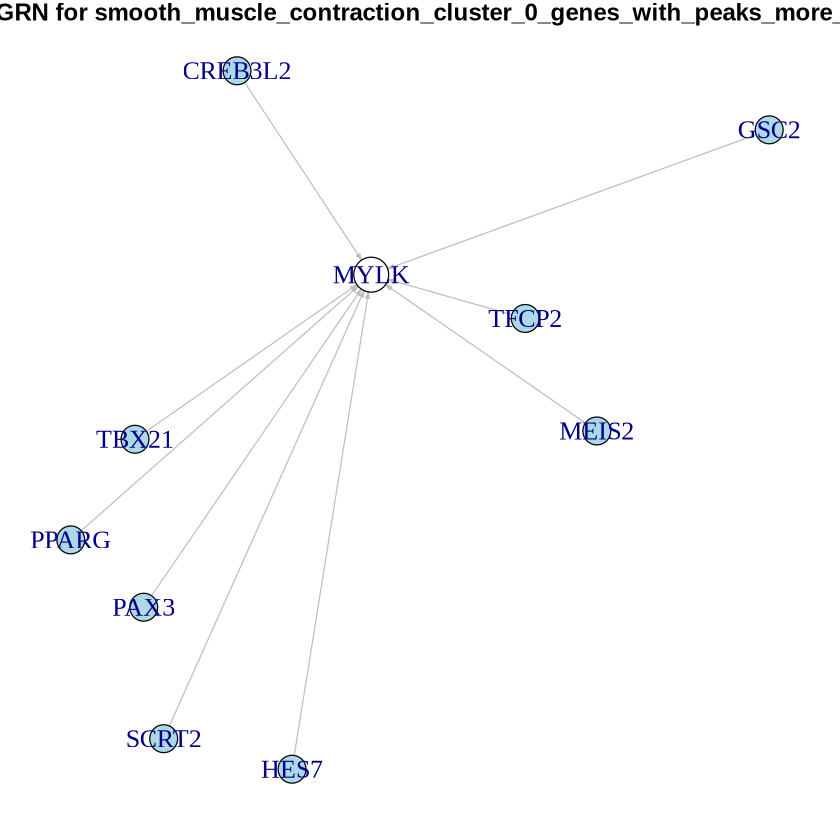

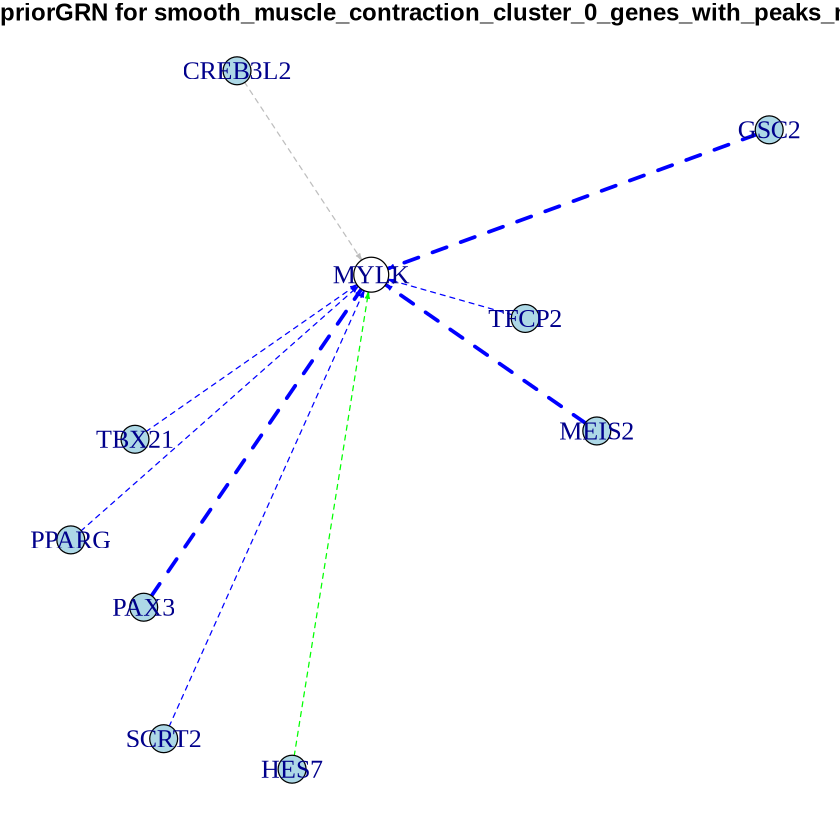

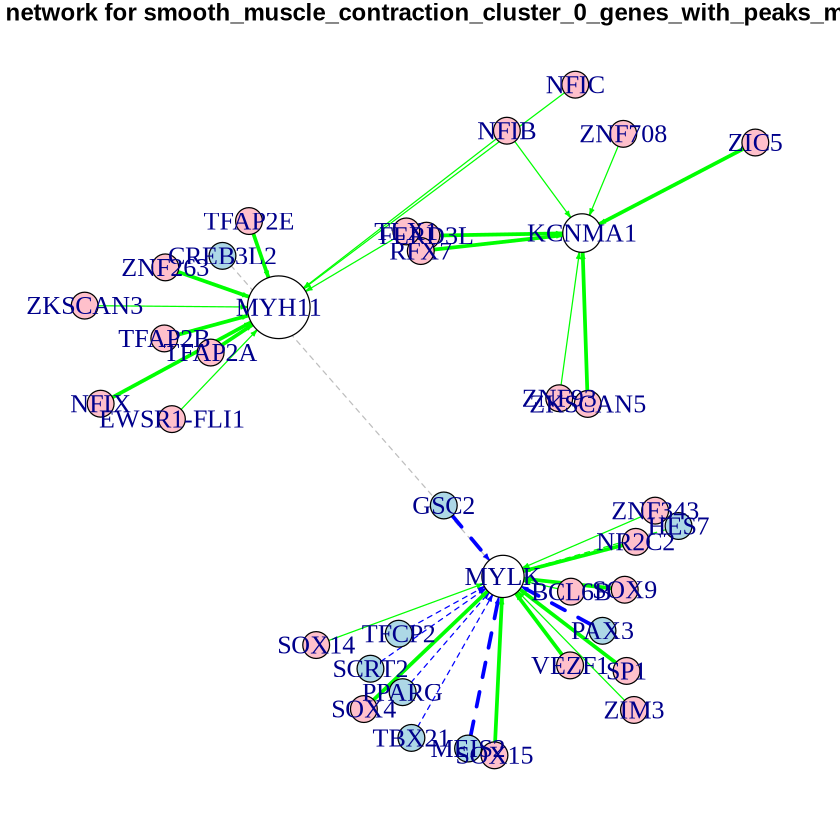

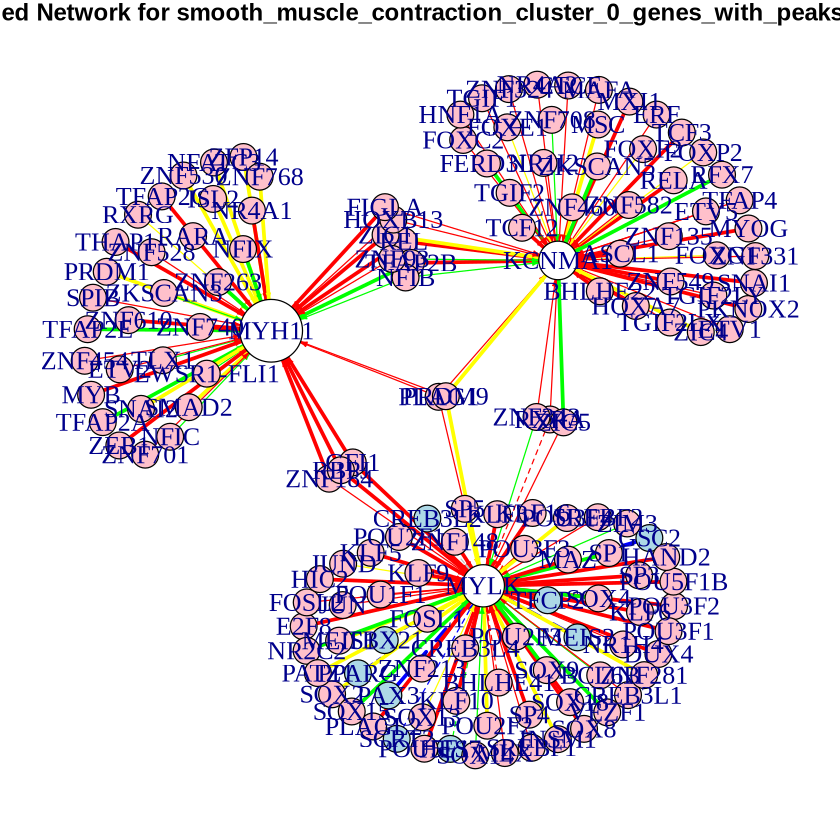

In [54]:
object_w_net<-draw_subNetwork_for_context(object=res_motifs_mapped, 
        gene_list= unique(res_motifs_mapped@misc$motif_stats$gene),
        cluster="0", 
        priorGRN=priorGRN_full[priorGRN_full$gene %in% unique(priorGRN_small$gene),],
        context_name='smooth_muscle_contraction_cluster_0_genes_with_peaks_more_prior',resolution=20,pointsize=50, sd=5,score=-0.5
        )

[1] "include_motifs_for_seed: KCNMA1 0"
[1] "motif stats for seed:KCNMA10"
[1] 252  26
[1] "motif stats for seed:KCNMA10"
[1] 86 26


found and passed 53 Transcription factors that bind in regulatory regions for seed KCNMA1 0



[1] "REL"
[1] "RELA"
[1] "PLAG1"
[1] "FOXG1"
[1] "MSC"
[1] "ZIC1"
[1] "PKNOX2"
[1] "TGIF1"
[1] "TGIF2"
[1] "TFAP2B"
[1] "FERD3L"
[1] "TGIF2LX"
[1] "TGIF2LY"
[1] "ZNF135"
[1] "ZNF460"
[1] "ASCL1"
[1] "ASCL1.1"
[1] "BHLHE22.1"
[1] "CTCF.1"
[1] "ERF"


adding distal and not enriched motif_stats for:



[1] "KCNMA1 0"


Detected 160 cores. Using 20 cores for parallel processing.

Attempting parallelized processing for 5 Seed-motif pairs. Using 20 cores.



... (105 outputs left out)

colors are numbers at the end: is this going wrong here already?



 [1] blue   blue   blue   yellow red    red    red    yellow red    red   
[11] red    green  red    red    red    yellow red    red    red    green 
[21] red    red    red    red    red    red    yellow yellow red    red   
[31] yellow red    red    red    red    red    red    red    yellow red   
[41] red    green  yellow red    red    red    yellow red    red    red   
[51] yellow red    yellow green  green  green  red    green  red    yellow
[61] green  red    green  red    yellow green 
Levels: green yellow red blue black gray


edge_color at the end of get_subnetwork



 [1] blue   blue   blue   yellow red    red    red    yellow red    red   
[11] red    green  red    red    red    yellow red    red    red    green 
[21] red    red    red    red    red    red    yellow yellow red    red   
[31] yellow red    red    red    red    red    red    red    yellow red   
[41] red    green  yellow red    red    red    yellow red    red    red   
[51] yellow red    yellow green  green  green  red    green  red    yellow
[61] green  red    green  red    yellow green 
Levels: green yellow red blue black gray
                from     to  color priorTF reg_type in.prom
KCNMA1.1         REL KCNMA1    red   FALSE        1       3
KCNMA1.2        RELA KCNMA1    red   FALSE        1       3
KCNMA1.3       PLAG1 KCNMA1    red   FALSE        1       1
KCNMA1.4       FOXG1 KCNMA1 yellow   FALSE        1       1
KCNMA1.5         MSC KCNMA1 yellow   FALSE        1       3
KCNMA1.6        ZIC1 KCNMA1 yellow   FALSE        1       3
KCNMA1.7      PKNOX2 KCNMA1    red   FALSE

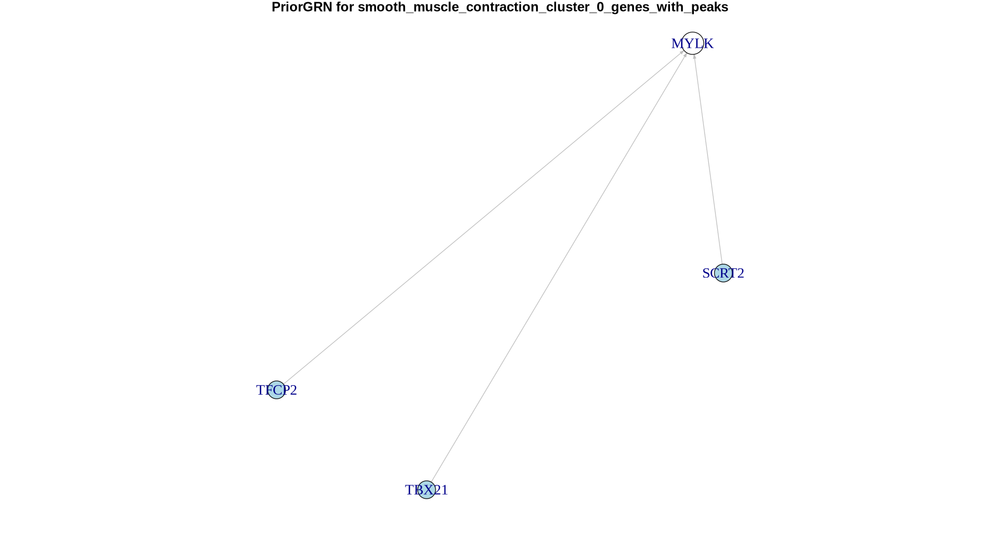

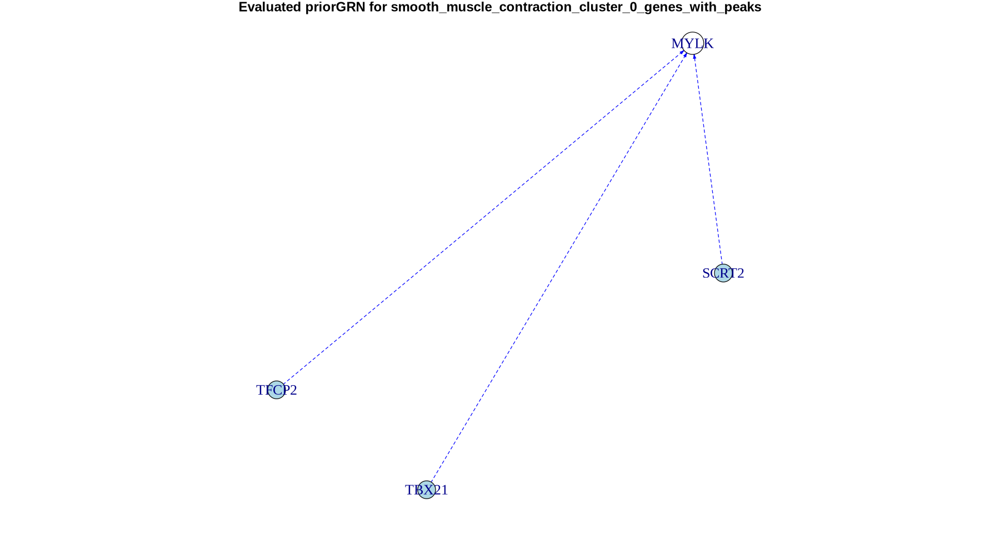

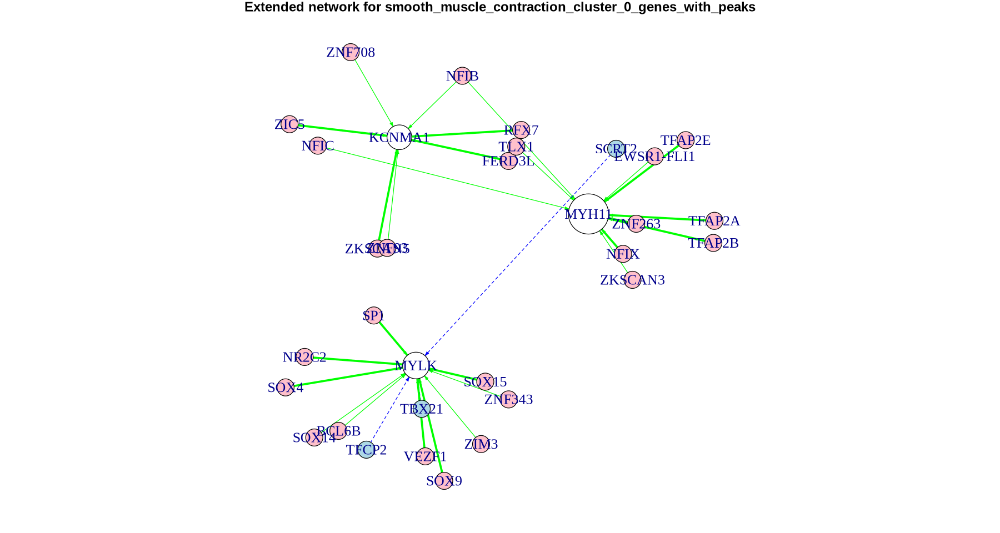

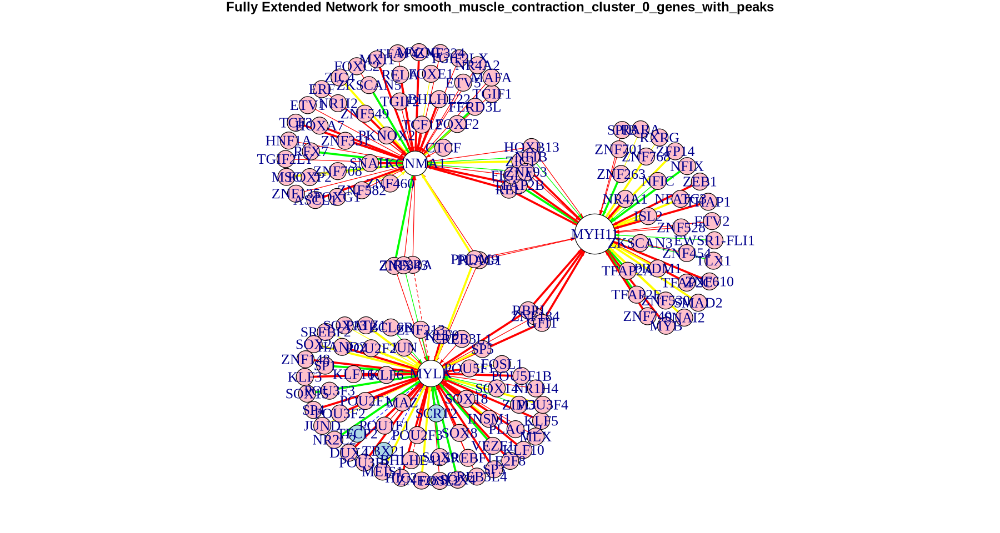

In [140]:
object_w_net<-draw_subNetwork_for_context(object=res_motifs_mapped, 
        gene_list= unique(res_motifs_mapped@misc$motif_stats$gene),
        cluster="0", 
        priorGRN=priorGRN,
        context_name='smooth_muscle_contraction_cluster_0_genes_with_peaks',resolution=20,pointsize=50, sd=5,score=-0.5
        )

[1] "include_motifs_for_seed: MYLK 0"
[1] "motif stats for seed:MYLK0"
[1] 336  26
[1] "motif stats for seed:MYLK0"
[1] 162  26


found and passed 66 Transcription factors that bind in regulatory regions for seed MYLK 0



[1] "SCRT2"


adding distal and not enriched motif_stats for:



[1] "MYLK 0"


Detected 160 cores. Using 20 cores for parallel processing.

Attempting parallelized processing for 1 Seed-motif pairs. Using 20 cores.

No footprint data



... (419 outputs left out)

colors are numbers at the end: is this going wrong here already?



NULL


edge_color at the end of get_subnetwork



character(0)
                from     to  color priorTF reg_type in.prom
MYLK.1         SCRT2   MYLK   blue    TRUE        2       1
MYLK.2         TBX21   MYLK   blue    TRUE        2       1
MYLK.3         TFCP2   MYLK   blue    TRUE        2       1
MYLK.4         INSM1   MYLK yellow   FALSE        1       3
MYLK.5         PLAG1   MYLK    red   FALSE        1       1
MYLK.6          DUX4   MYLK    red   FALSE        1       3
MYLK.7        SREBF1   MYLK    red   FALSE        1       1
MYLK.8        SREBF2   MYLK    red   FALSE        1       1
MYLK.9          KLF5   MYLK    red   FALSE        1       3
MYLK.10      BHLHE41   MYLK    red   FALSE        2       1
MYLK.11          MLX   MYLK    red   FALSE        1       1
MYLK.12        BCL6B   MYLK  green   FALSE        1       1
MYLK.13        KLF16   MYLK    red   FALSE        1       3
MYLK.14       POU3F2   MYLK    red   FALSE        1       3
MYLK.15       POU3F3   MYLK    red   FALSE        1       1
MYLK.16       POU3F4   MYLK

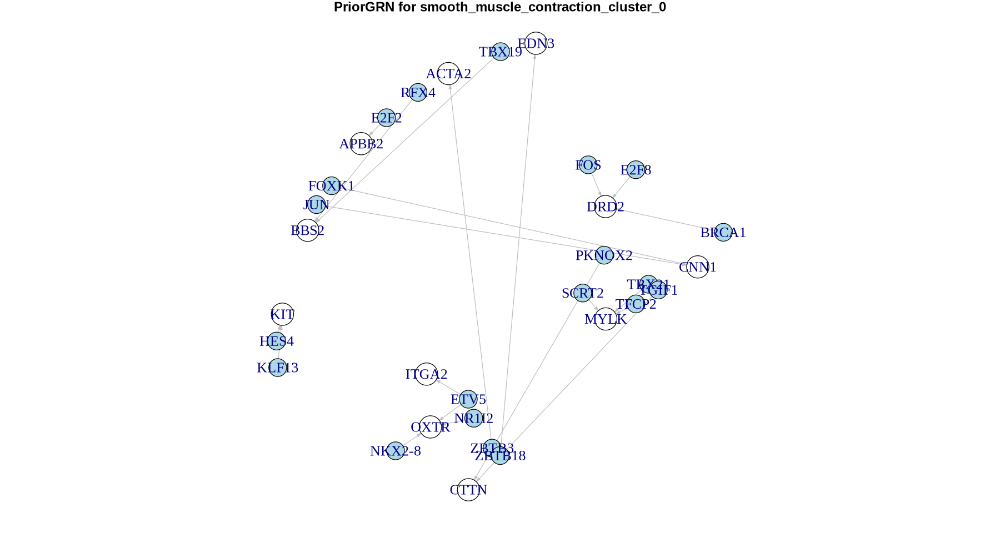

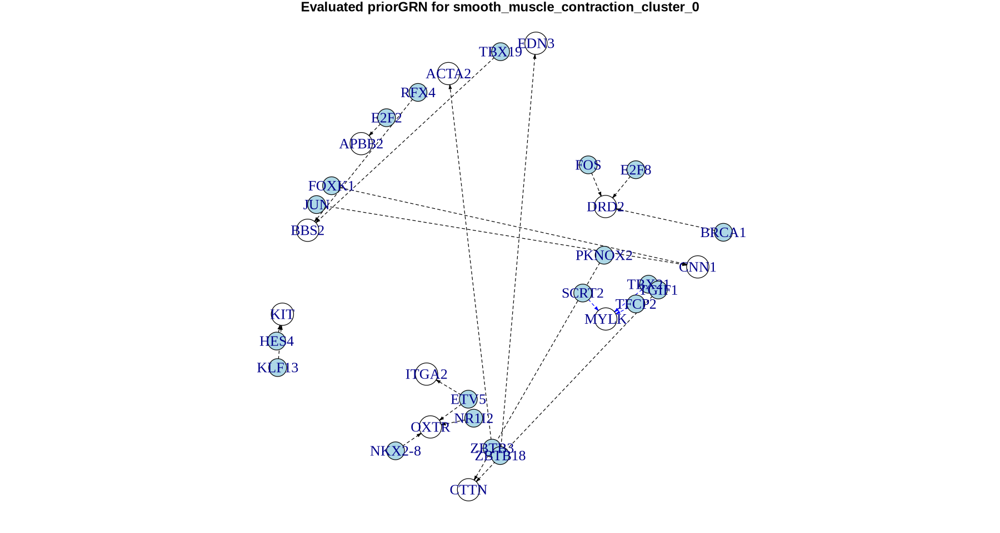

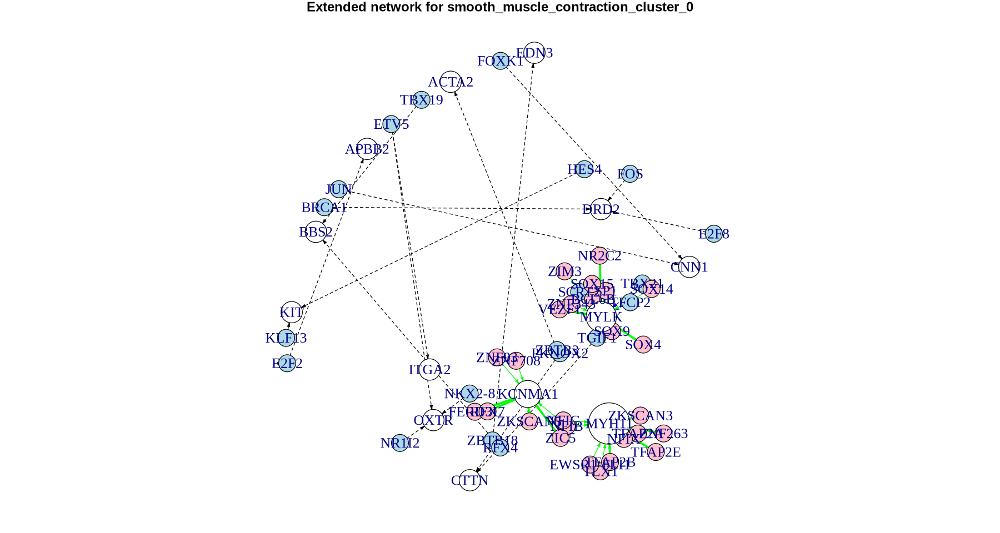

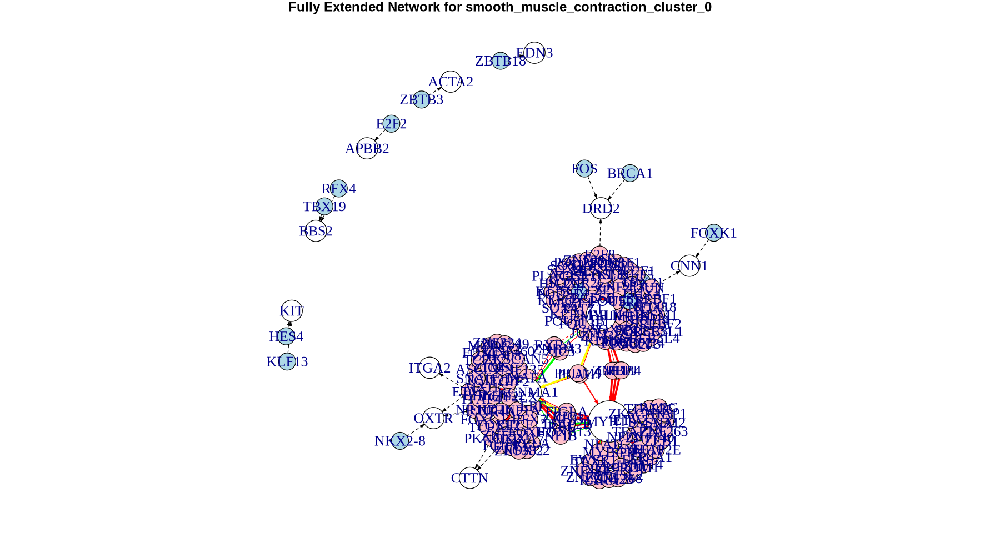

In [134]:
object_w_net<-draw_subNetwork_for_context(object=res_motifs_mapped, 
        gene_list= unique(seeds_for_peaks_stats$gene),
        cluster="0", 
        priorGRN=priorGRN,
        context_name='smooth_muscle_contraction_cluster_0',resolution=20,pointsize=50, sd=5,score=-0.5
        )

In [141]:
saveRDS(object_w_net, "object_w_net_smooth_muscle_contraction.rds")

In [146]:
str(object_w_net@misc, max.level=1)

List of 12
 $ markers.annotated        :'data.frame':	4000 obs. of  8 variables:
 $ peak_stats               :'data.frame':	134 obs. of  43 variables:
 $ peak_stats.filtered      :'data.frame':	17 obs. of  51 variables:
 $ motifs.inProximalPeaks   :List of 3
 $ motif_enrichment         :'data.frame':	2160 obs. of  16 variables:
 $ motifs.inDistalPeaks     :List of 1
 $ filtered.motif_enrichment:'data.frame':	888 obs. of  16 variables:
 $ motif_stats              :'data.frame':	888 obs. of  26 variables:
 $ motif2TF                 :List of 720
 $ TF2motif                 :List of 668
 $ seedNetwork              :List of 1
 $ context_subNetwork       :List of 1


In [156]:
green_edges <- object_w_net@misc$context_subNetwork$smooth_muscle_contraction_cluster_0_genes_with_peaks[object_w_net@misc$context_subNetwork$smooth_muscle_contraction_cluster_0_genes_with_peaks$color=="green",]

In [142]:
str(object_w_net@misc$seedNetwork$smooth_muscle_contraction_cluster_0_genes_with_peaks, max.level=1)

List of 3
 $ KCNMA1:'data.frame':	135 obs. of  30 variables:
 $ MYH11 :'data.frame':	154 obs. of  30 variables:
 $ MYLK  :'data.frame':	220 obs. of  30 variables:


In [161]:
object_w_net@misc$seedNetwork$smooth_muscle_contraction_cluster_0_genes_with_peaks$MYLK[object_w_net@misc$seedNetwork$smooth_muscle_contraction_cluster_0_genes_with_peaks$MYLK$result=="green",]

,gene,cluster,proximal.motif_count,proximal.background_count,log2FC.proximal,t_stat.proximal,p_value.proximal,p_adjust.proximal,distal.motif_count,distal.background_count,⋯,footprint.p_value,footprint.p_value_adj,sd.flanks,bg_sd_mean,left_flank_nonzero_positions,right_flank_nonzero_positions,promoter.or.enriched,TF,result,priorTF
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<lgl>,<chr>,<chr>,<lgl>
MYLK.BCL6B.3731,MYLK,0,3,1.4,1.1,-7.9,1.5e-10,1.1e-07,0,3,⋯,1.541e-05,5.2e-03,1.707,2.094,14,13,TRUE,BCL6B,green,FALSE
MYLK.SP1.4040,MYLK,0,6,25,-2.1,19,1,1,0,3.7,⋯,3.490e-05,1.2e-02,2.325,1.217,16,18,TRUE,SP1,green,FALSE
MYLK.NR2C2.5129,MYLK,0,1,6.6,-2.7,12,1,1,1,2.9,⋯,1.042e-04,3.5e-02,2.316,2.379,9,10,TRUE,NR2C2,green,FALSE
MYLK.SOX14.5375,MYLK,0,1,0.54,0.89,-4.6,1.5e-05,0.011,0,1.4,⋯,8.860e-05,3.0e-02,2.426,4.924,4,5,TRUE,SOX14,green,FALSE
MYLK.SOX14.5376,MYLK,0,1,0.54,0.89,-4.6,1.5e-05,0.011,0,1.4,⋯,2.828e-05,9.5e-03,2.426,3.773,4,5,TRUE,SOX14,green,FALSE
MYLK.SOX15.5377,MYLK,0,1,0.84,0.25,-1.1,0.13,1,1,2,⋯,1.548e-06,5.2e-04,3.069,2.377,11,7,TRUE,SOX15,green,FALSE
MYLK.SOX15.5378,MYLK,0,1,0.84,0.25,-1.1,0.13,1,1,2,⋯,8.173e-06,2.7e-03,3.069,2.734,11,7,TRUE,SOX15,green,FALSE
MYLK.SOX15.5379,MYLK,0,1,0.84,0.25,-1.1,0.13,1,1,2,⋯,4.029e-05,1.4e-02,3.069,3.032,11,7,TRUE,SOX15,green,FALSE
MYLK.SOX4.5380,MYLK,0,1,1.7,-0.77,3.7,1,1,1,3.9,⋯,3.572e-05,1.2e-02,2.705,2.918,9,9,TRUE,SOX4,green,FALSE


TF provided, plotting all motifs for TF

computing motifs to gene



[1] "2026-04-08 22:53:35 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr10 77637394-77637407      + |   10.7956
  [2]    chr10 77638464-77638477      + |   10.2537
  [3]    chr10 77637394-77637407      - |   10.8658
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 22:53:36 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


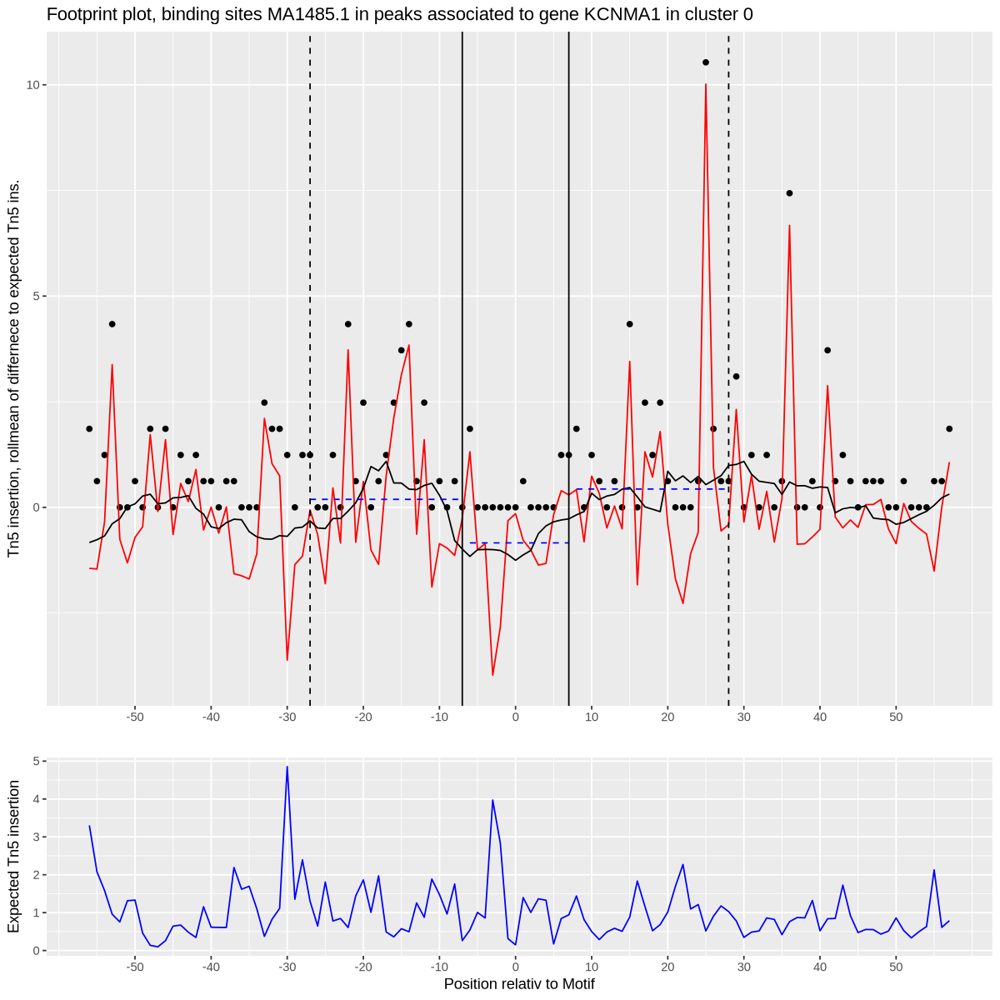

In [145]:

footprint_plots_by_TF(object=object_w_net, gene='KCNMA1', cluster=0, TF="FERD3L", path=NULL)

In [ ]:
object_w_net@misc$seedNetwork$smooth_muscle_contraction_cluster_0_genes_with_peaks$MYLK[object_w_net@misc$seedNetwork$smooth_muscle_contraction_cluster_0_genes_with_peaks$MYLK$result=="green",]

In [163]:
str(object_w_net@misc$seedNetwork$smooth_muscle_contraction_cluster_0_genes_with_peaks, max.level=1)

List of 3
 $ KCNMA1:'data.frame':	135 obs. of  30 variables:
 $ MYH11 :'data.frame':	154 obs. of  30 variables:
 $ MYLK  :'data.frame':	220 obs. of  30 variables:


In [167]:
colnames(object_w_net@misc$seedNetwork$smooth_muscle_contraction_cluster_0_genes_with_peaks[[gene]])

[1] "gene"                          "cluster"                      
 [3] "proximal.motif_count"          "proximal.background_count"    
 [5] "log2FC.proximal"               "t_stat.proximal"              
 [7] "p_value.proximal"              "p_adjust.proximal"            
 [9] "distal.motif_count"            "distal.background_count"      
[11] "log2FC.distal"                 "t_stat.distal"                
[13] "p_value.distal"                "p_adjust.distal"              
[15] "motif"                         "promoter.motif_count"         
[17] "footprint_score"               "bg_size"                      
[19] "bg_footprint_mean"             "footprint.t_stat"             
[21] "footprint.p_value"             "footprint.p_value_adj"        
[23] "sd.flanks"                     "bg_sd_mean"                   
[25] "left_flank_nonzero_positions"  "right_flank_nonzero_positions"
[27] "promoter.or.enriched"          "TF"                           
[29] "result"                        "priorTF"

[1] "Footprint plot for gene: MYLK"
[1] "Plotting footprint for motif: MA0731.1 and gene: MYLK"
[1] "2026-04-08 23:08:48 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123883802-123883818      + |  -3.76072
  [2]     chr3 123883951-123883967      - |  -3.33170
  [3]     chr3 123884667-123884683      - |  -2.08718
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:08:49 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"
[1] "Plotting footprint for motif: MA0079.5 and gene: MYLK"
[1] "2026-04-08 23:08:50 CEST"
GRanges object with 6 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123884361-123884369      + |   17.9327
  [2]     chr3 123884366-123884374      + |   17.9327
  [3]     chr3 123884371-123884379      + |   17.9327
  [4]     chr3 123884376-123884384      + |   17.9327
  [5]     chr3 123883741-123883749      - |   14.5058
  [6]     chr3 123883918-123883926      - |   16.2175
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:08:50 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


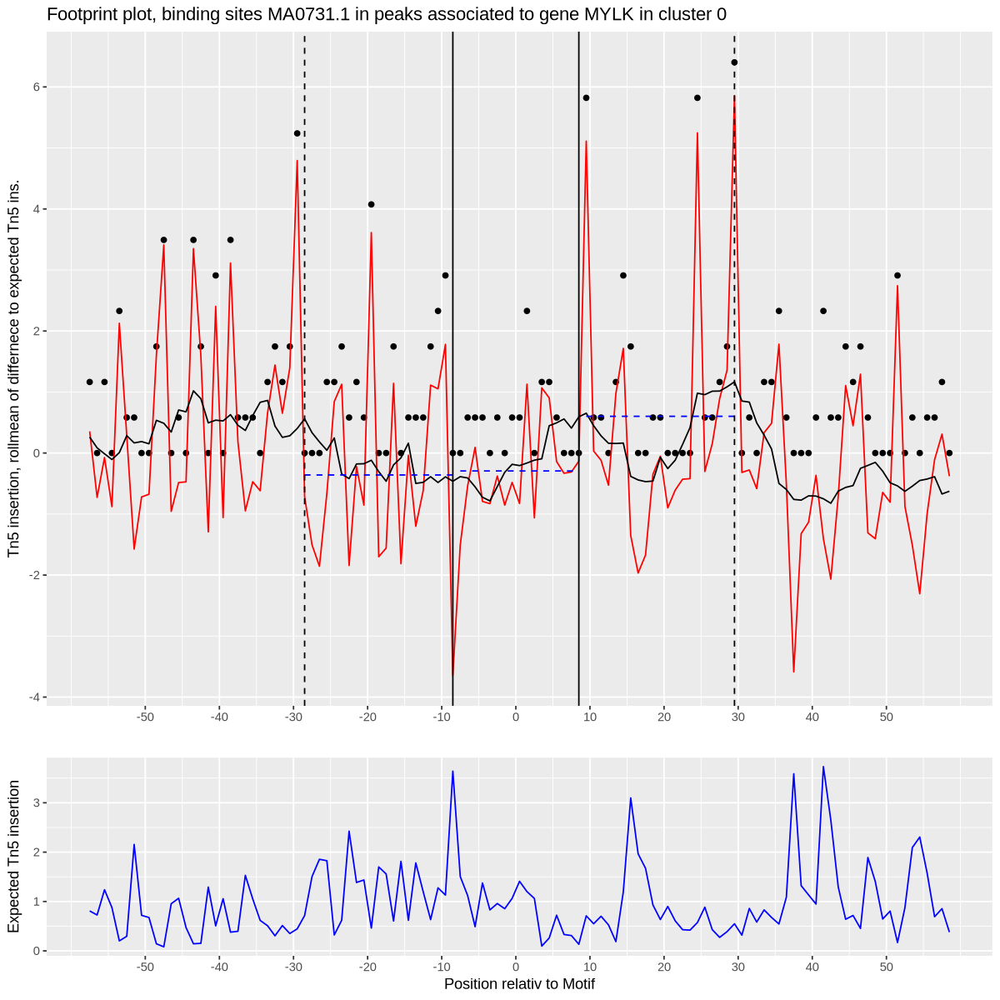

[1] "Plotting footprint for motif: MA0504.2 and gene: MYLK"
[1] "2026-04-08 23:08:51 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123884375-123884388      + |   11.9743
  [2]     chr3 123766954-123766967      + |   12.1307
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:08:52 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


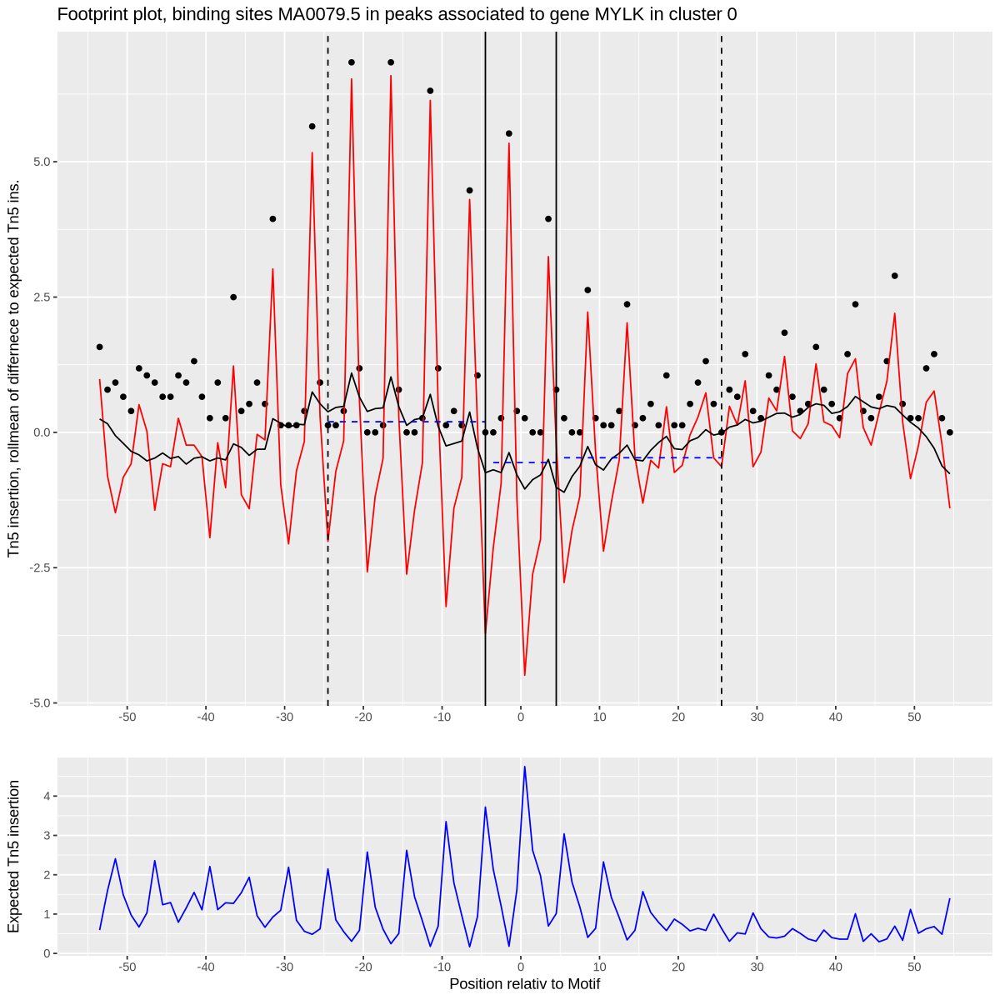

[1] "Plotting footprint for motif: MA1562.2 and gene: MYLK"
[1] "2026-04-08 23:08:53 CEST"
GRanges object with 1 range and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123883638-123883646      + |   11.0784
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:08:53 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


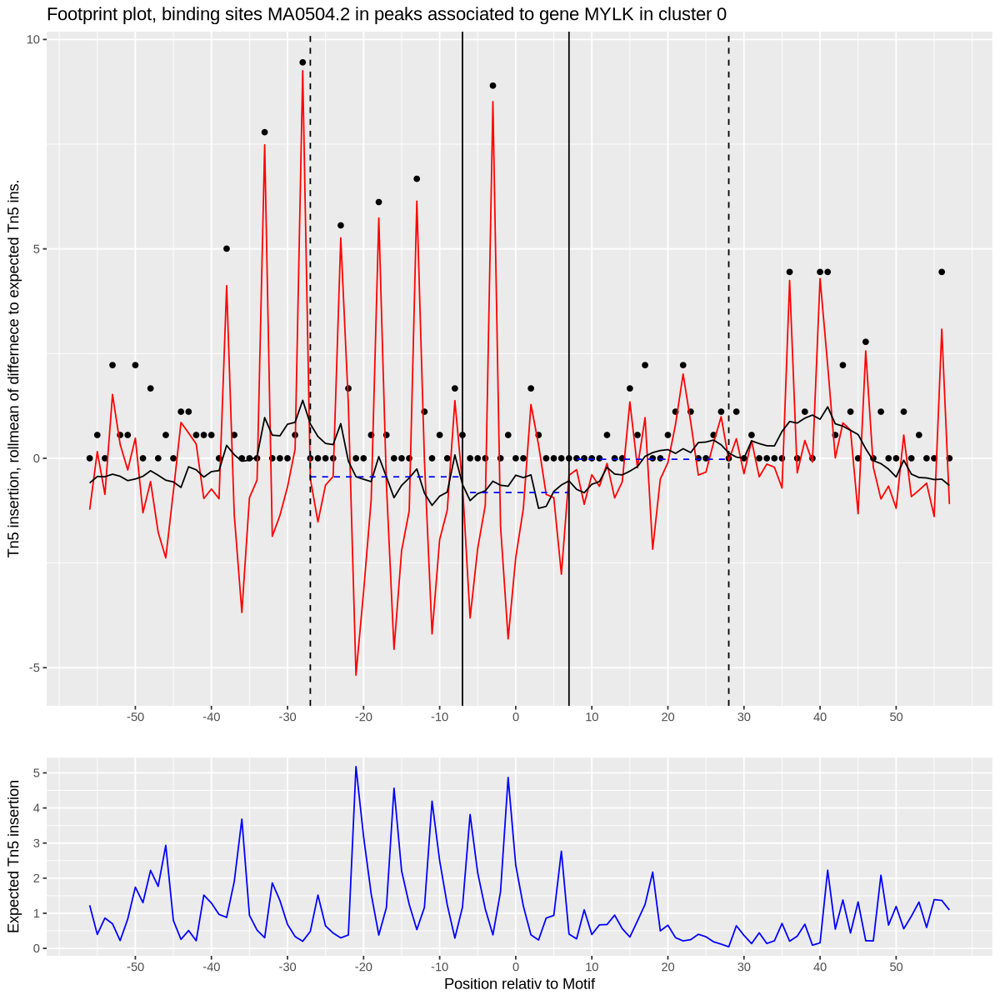

[1] "Plotting footprint for motif: MA1562.2 and gene: MYLK"
[1] "2026-04-08 23:08:54 CEST"
GRanges object with 1 range and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123883638-123883646      + |   11.0784
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:08:54 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


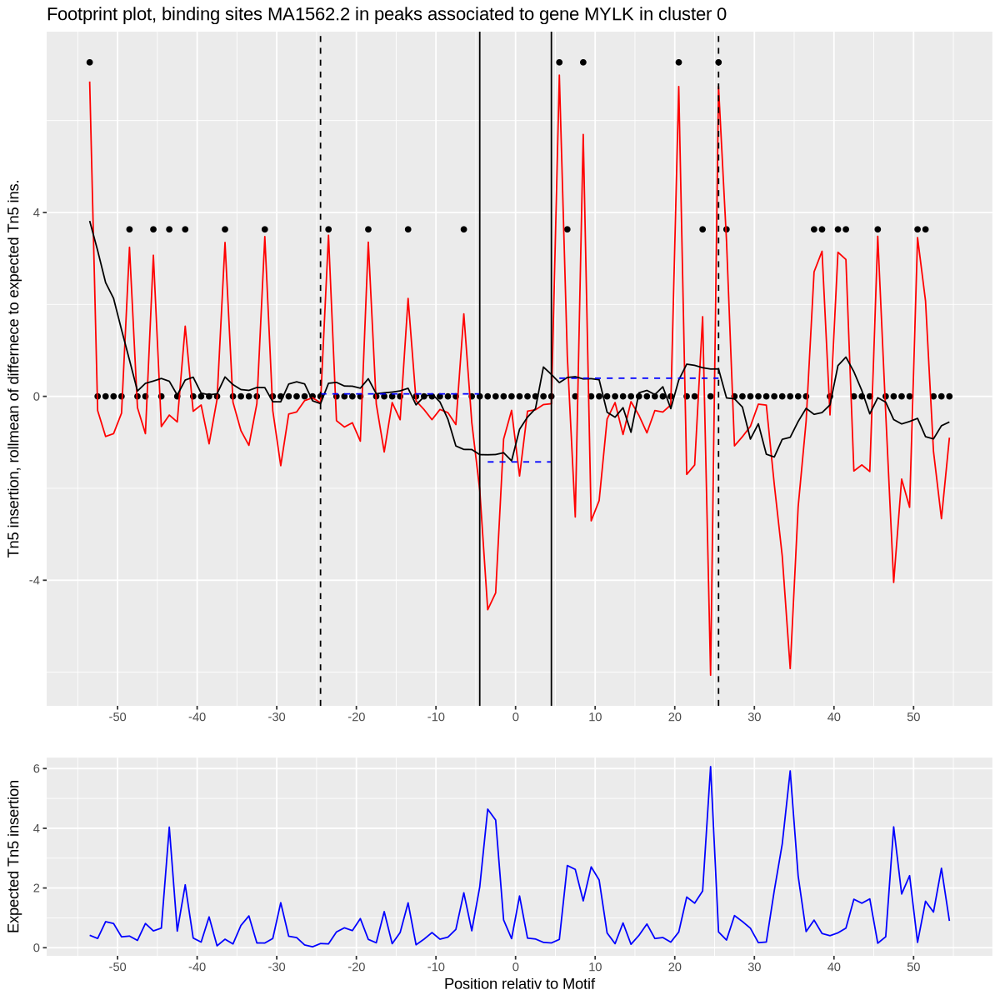

[1] "Plotting footprint for motif: MA1152.2 and gene: MYLK"
[1] "2026-04-08 23:08:55 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123883654-123883660      - |   10.7071
  [2]     chr3 123766876-123766882      + |   10.7071
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:08:55 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


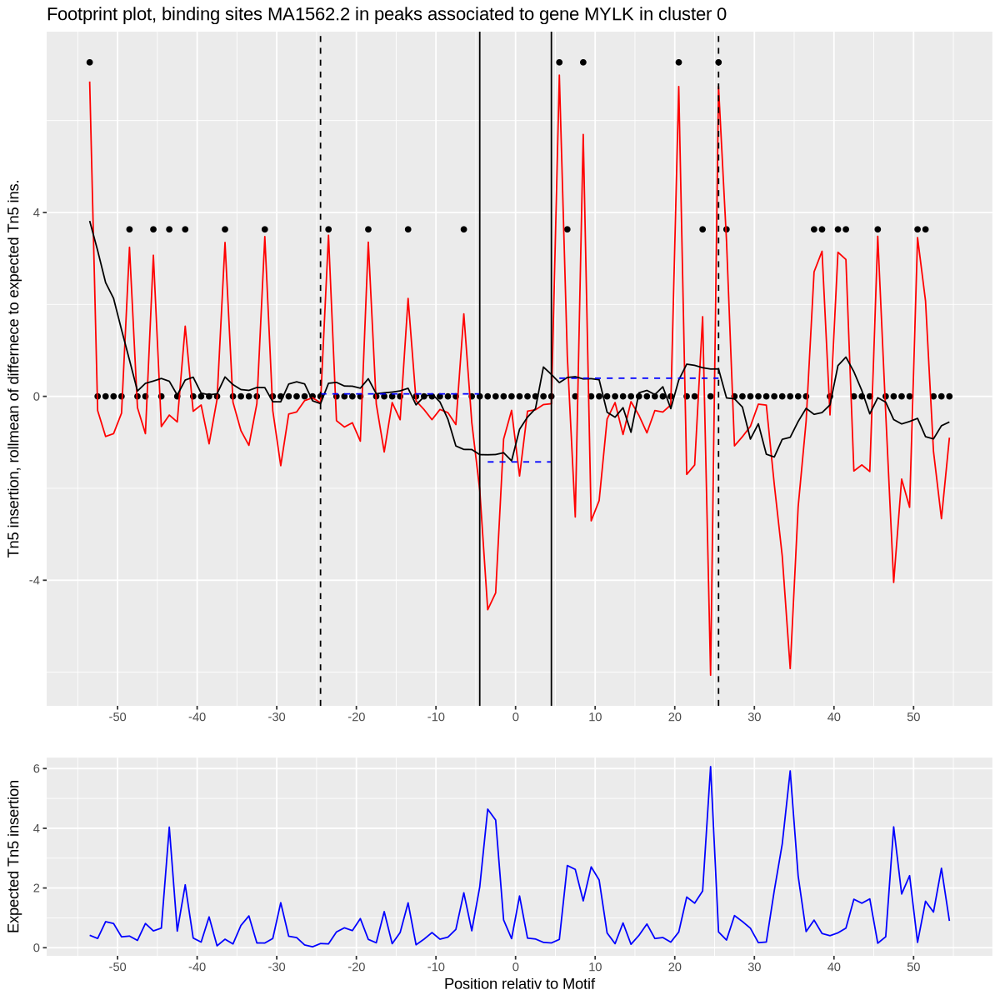

[1] "Plotting footprint for motif: MA1152.2 and gene: MYLK"
[1] "2026-04-08 23:08:56 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123883654-123883660      - |   10.7071
  [2]     chr3 123766876-123766882      + |   10.7071
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:08:56 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


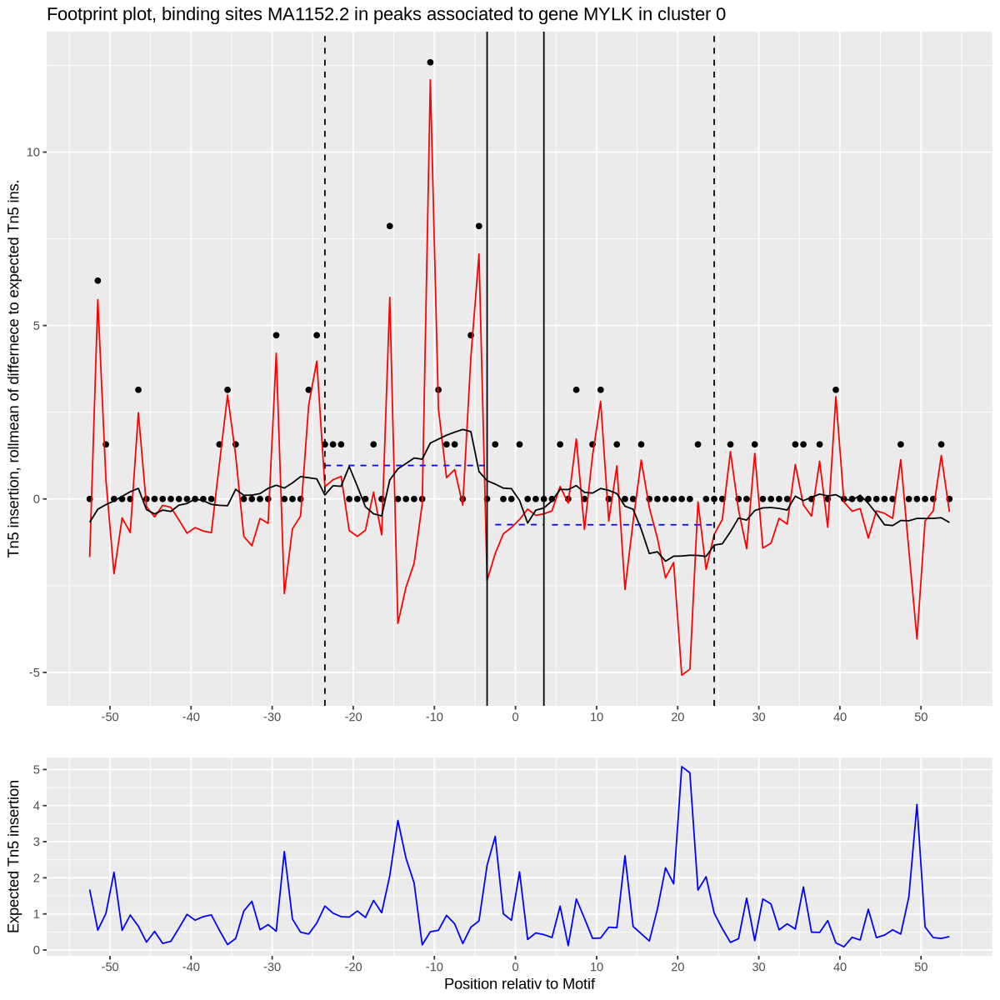

[1] "Plotting footprint for motif: MA1152.2 and gene: MYLK"
[1] "2026-04-08 23:08:57 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123883654-123883660      - |   10.7071
  [2]     chr3 123766876-123766882      + |   10.7071
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:08:57 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


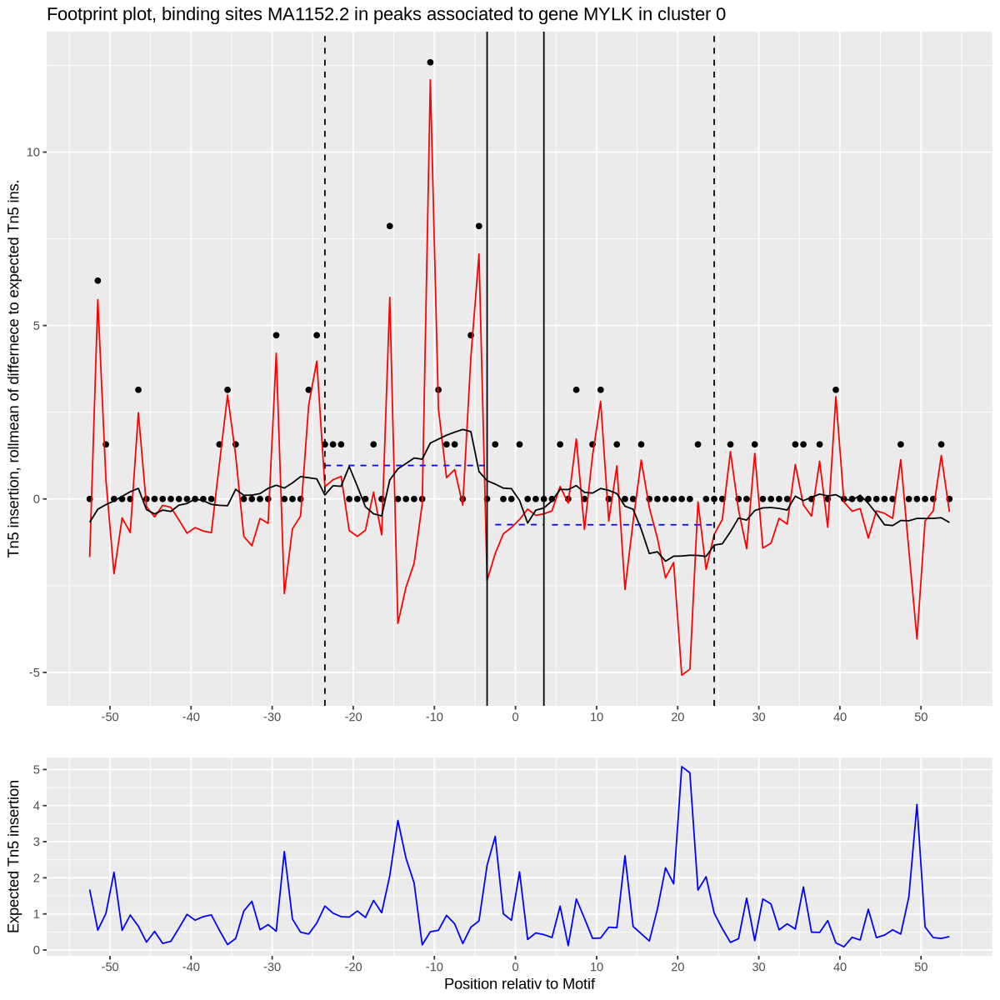

[1] "Plotting footprint for motif: MA0867.3 and gene: MYLK"
[1] "2026-04-08 23:08:58 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123883653-123883660      + |   11.9216
  [2]     chr3 123816939-123816946      + |   11.8607
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:08:58 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


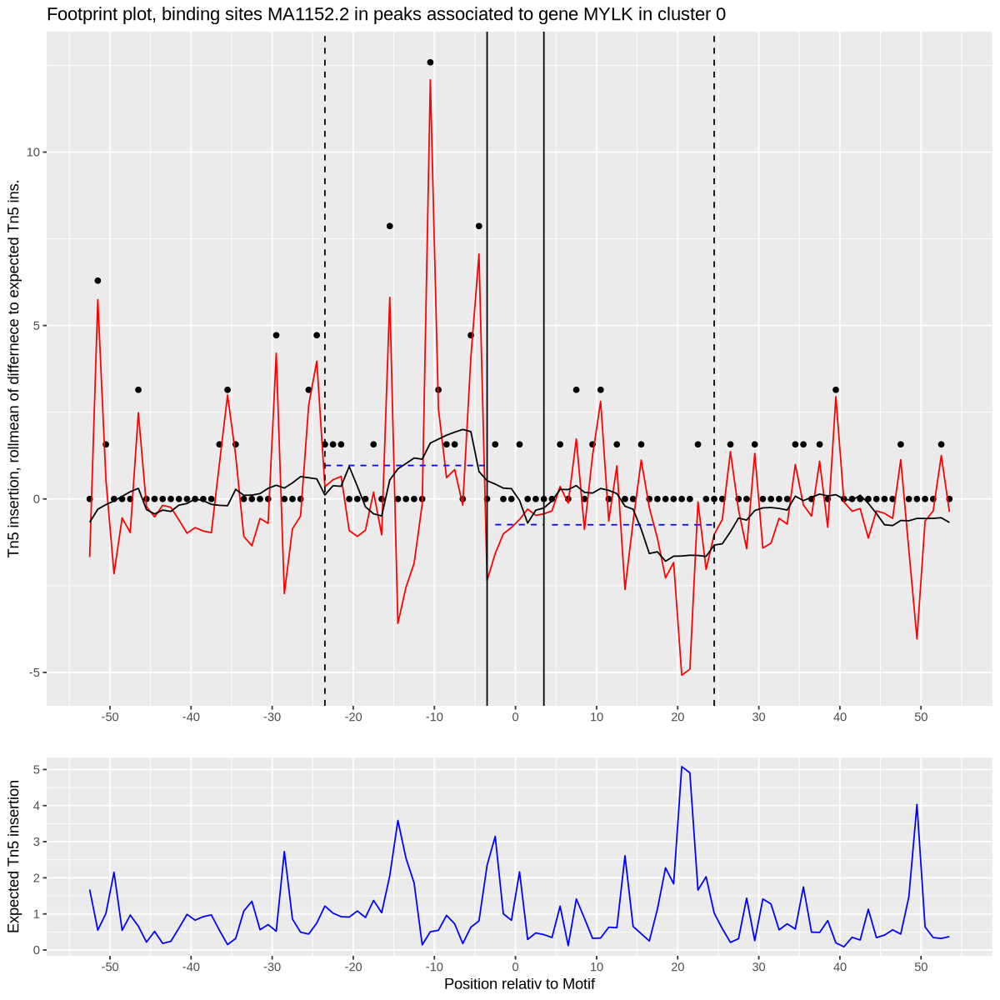

[1] "Plotting footprint for motif: MA0867.3 and gene: MYLK"
[1] "2026-04-08 23:08:59 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123883653-123883660      + |   11.9216
  [2]     chr3 123816939-123816946      + |   11.8607
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:08:59 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


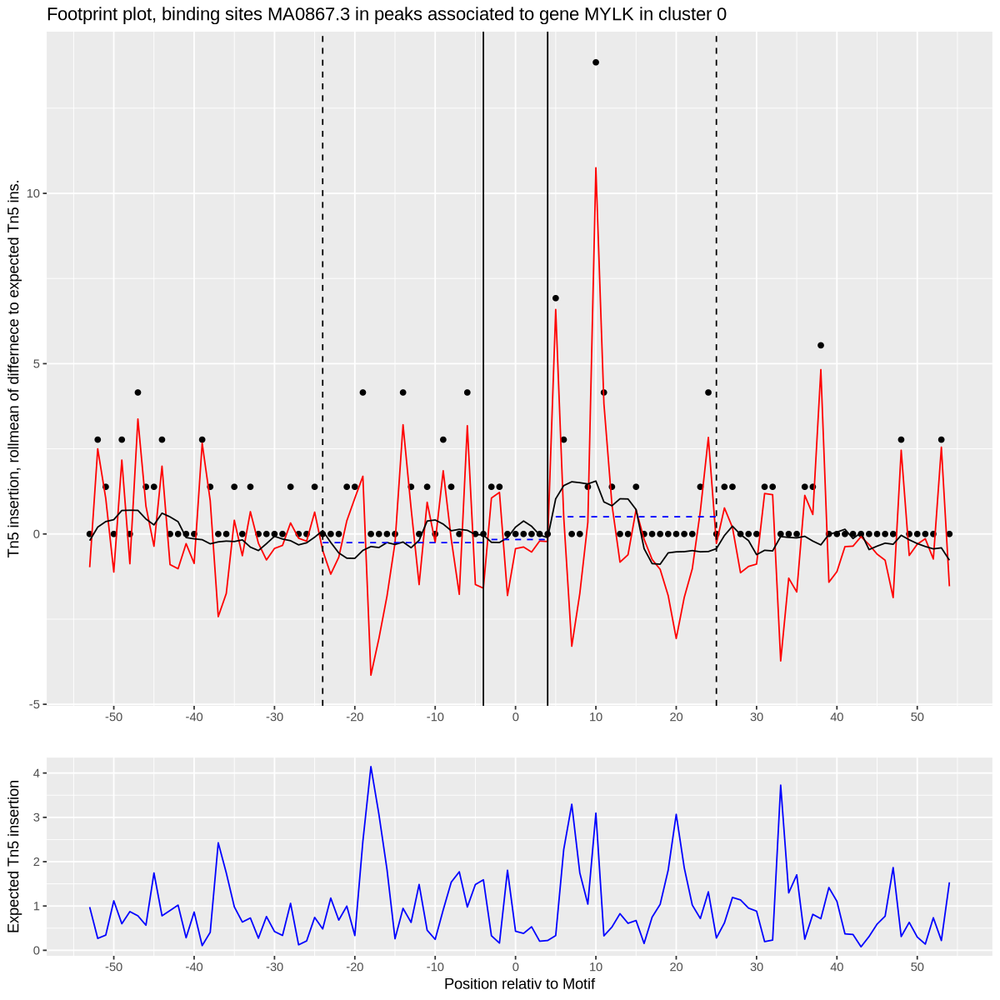

[1] "Plotting footprint for motif: MA0867.3 and gene: MYLK"
[1] "2026-04-08 23:09:00 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123883653-123883660      + |   11.9216
  [2]     chr3 123816939-123816946      + |   11.8607
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:00 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


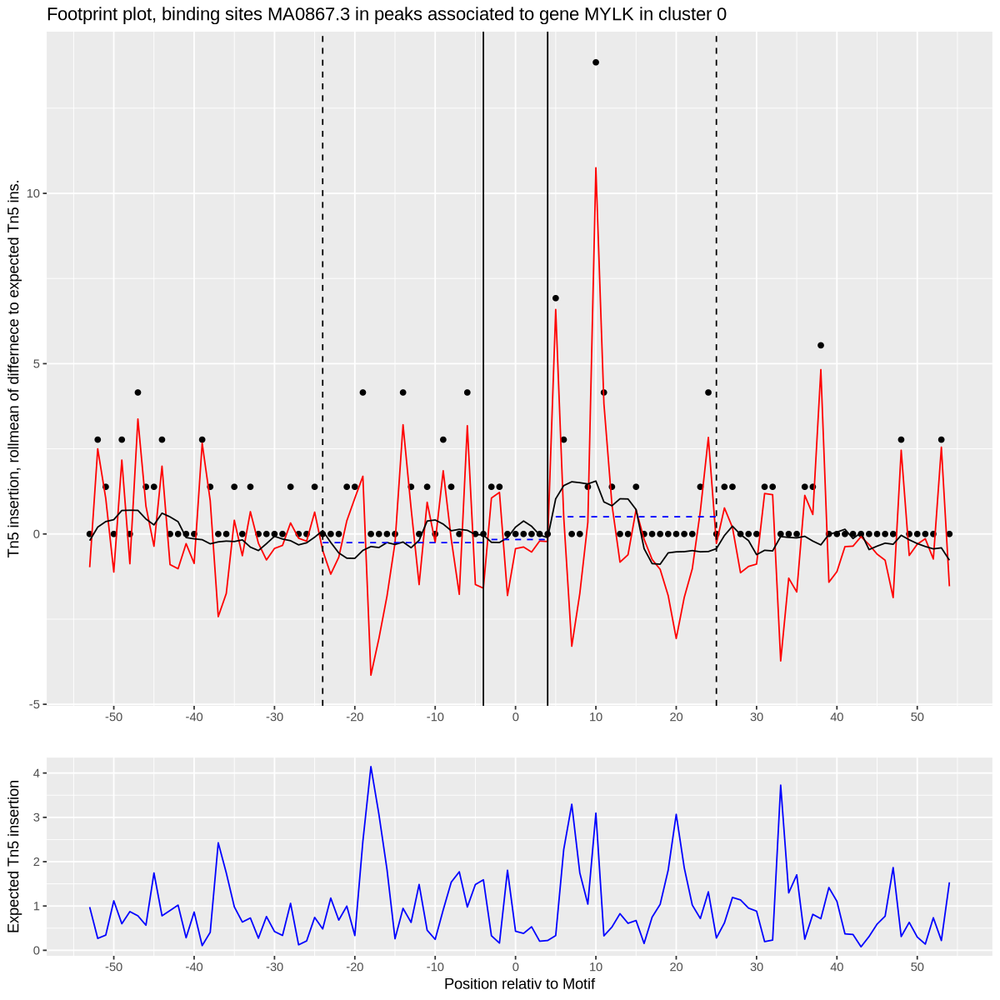

[1] "Plotting footprint for motif: MA0077.2 and gene: MYLK"
[1] "2026-04-08 23:09:01 CEST"
GRanges object with 1 range and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123883653-123883660      - |   12.6565
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:01 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


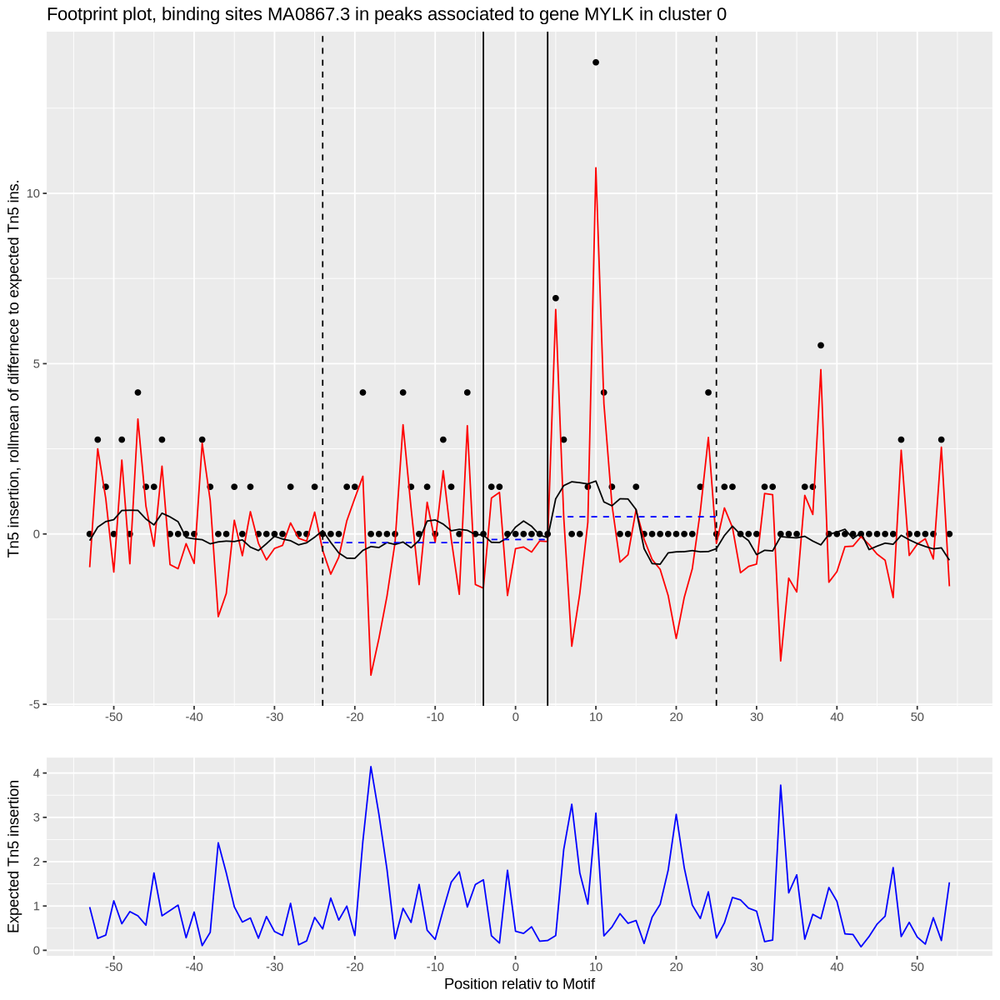

[1] "Plotting footprint for motif: MA0077.2 and gene: MYLK"
[1] "2026-04-08 23:09:02 CEST"
GRanges object with 1 range and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123883653-123883660      - |   12.6565
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:02 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


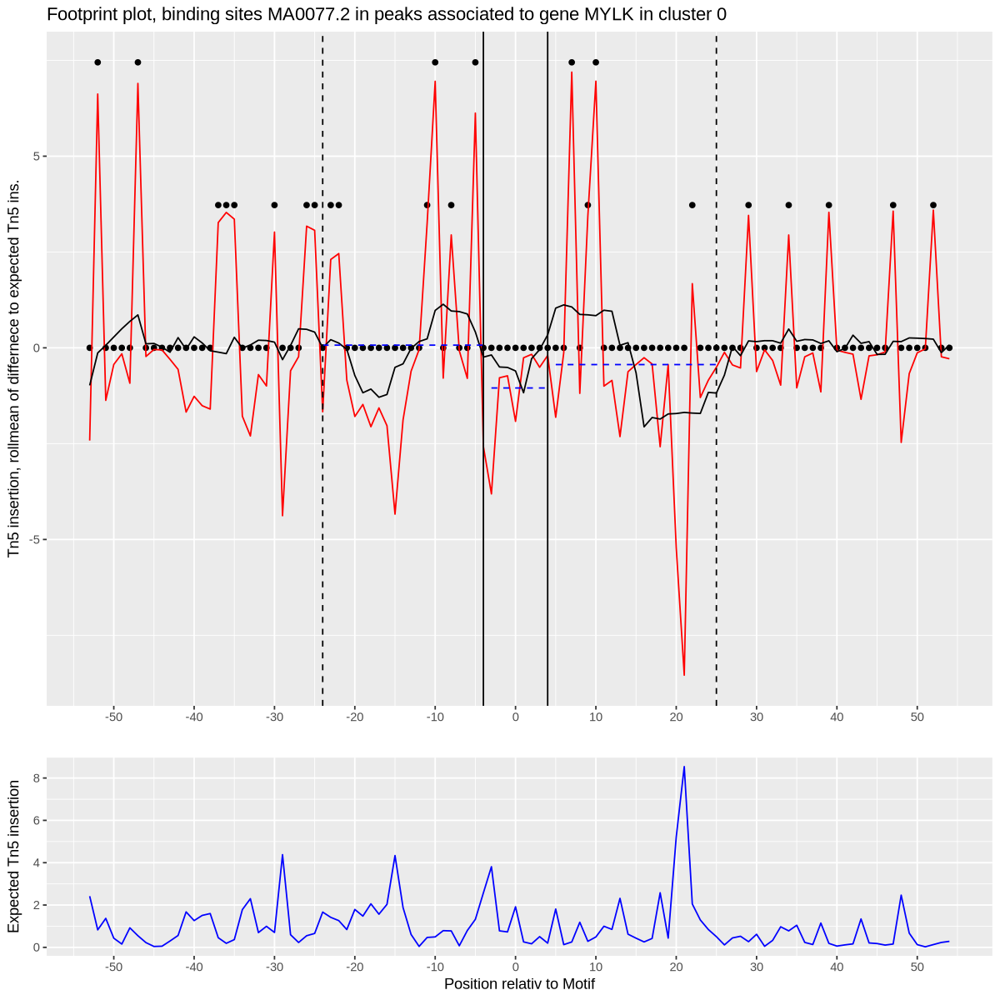

[1] "Plotting footprint for motif: MA1578.2 and gene: MYLK"
[1] "2026-04-08 23:09:03 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123884636-123884641      + |   12.5465
  [2]     chr3 123816344-123816349      - |   12.5465
  [3]     chr3 123816770-123816775      - |   12.5465
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:03 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


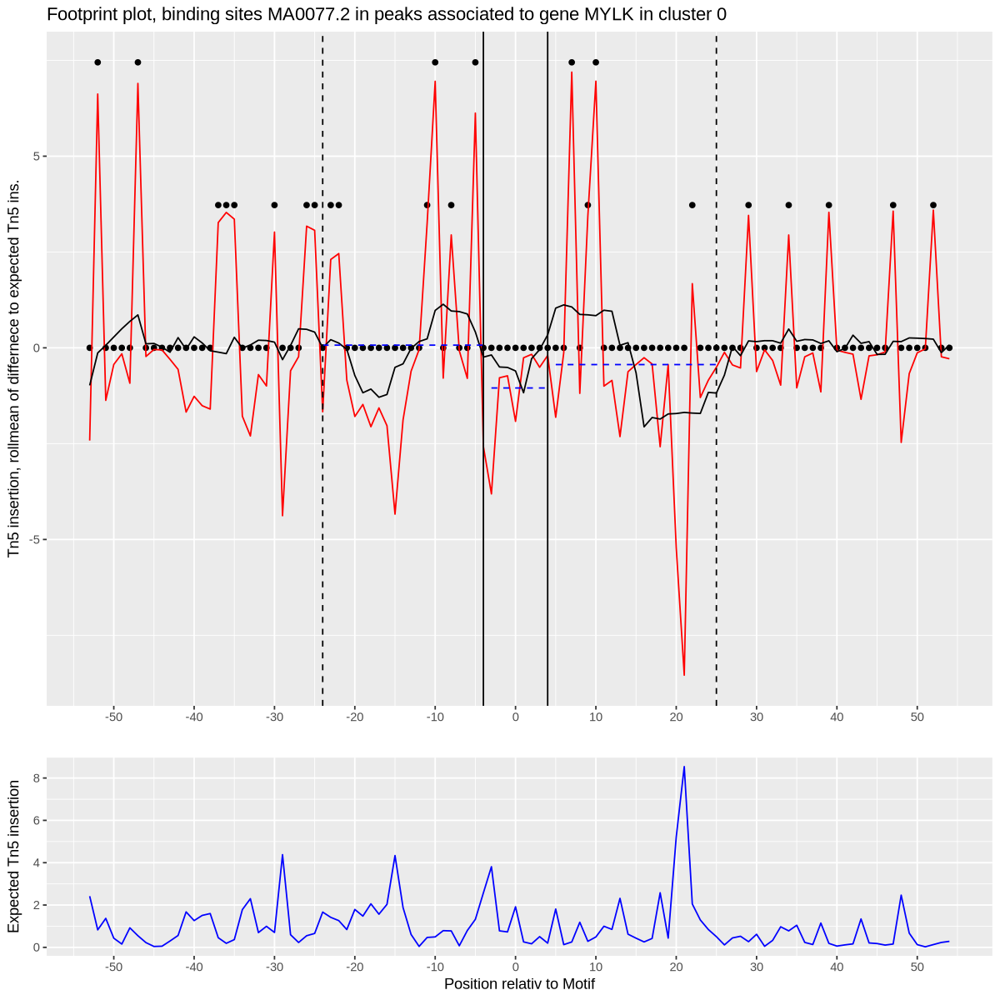

[1] "Plotting footprint for motif: MA1709.2 and gene: MYLK"
[1] "2026-04-08 23:09:04 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123884002-123884012      + |   12.1647
  [2]     chr3 123816514-123816524      + |   11.5340
  [3]     chr3 123816856-123816866      + |   10.7957
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:04 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


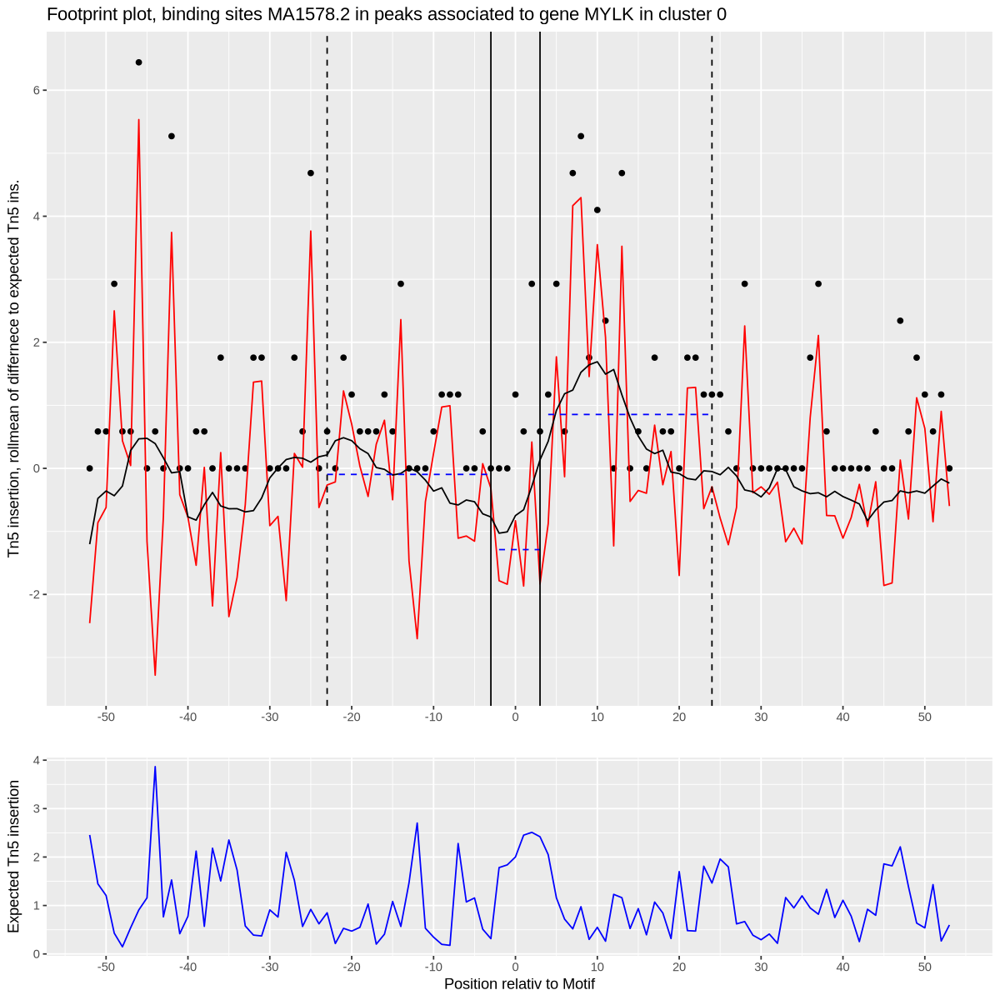

[1] "Plotting footprint for motif: MA1709.2 and gene: MYLK"
[1] "2026-04-08 23:09:05 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123884002-123884012      + |   12.1647
  [2]     chr3 123816514-123816524      + |   11.5340
  [3]     chr3 123816856-123816866      + |   10.7957
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:05 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


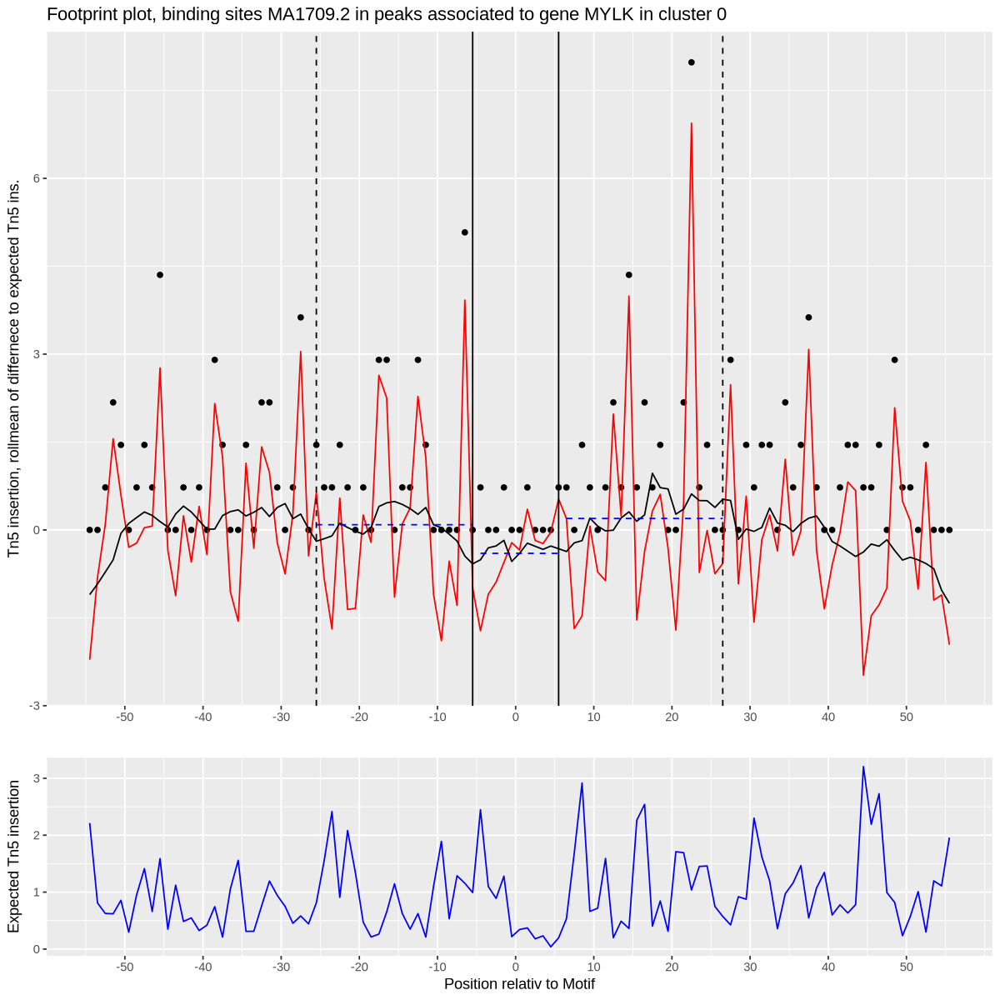

[1] "Plotting footprint for motif: MA1711.2 and gene: MYLK"
[1] "2026-04-08 23:09:06 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123883909-123883924      + |   15.1240
  [2]     chr3 123766339-123766354      - |   12.5539
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:06 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


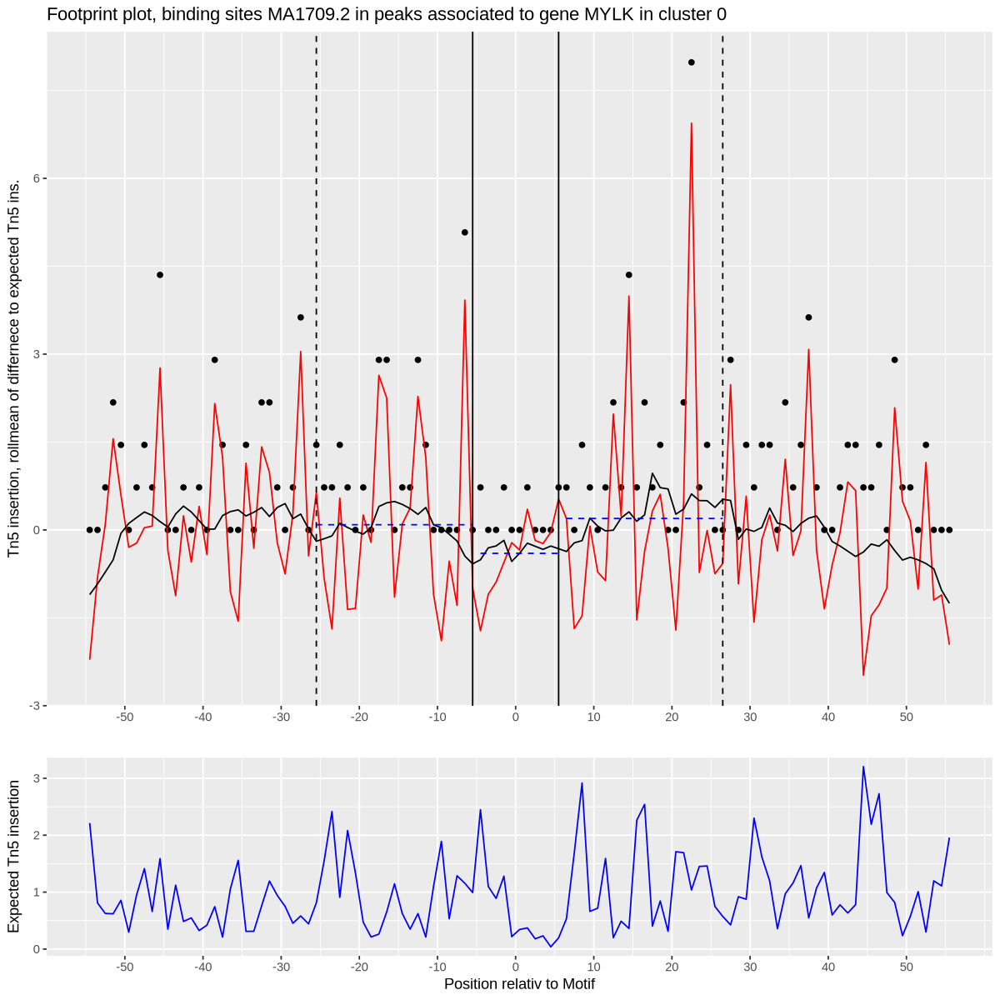

[1] "Plotting footprint for motif: MA1711.2 and gene: MYLK"
[1] "2026-04-08 23:09:07 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123883909-123883924      + |   15.1240
  [2]     chr3 123766339-123766354      - |   12.5539
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:07 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


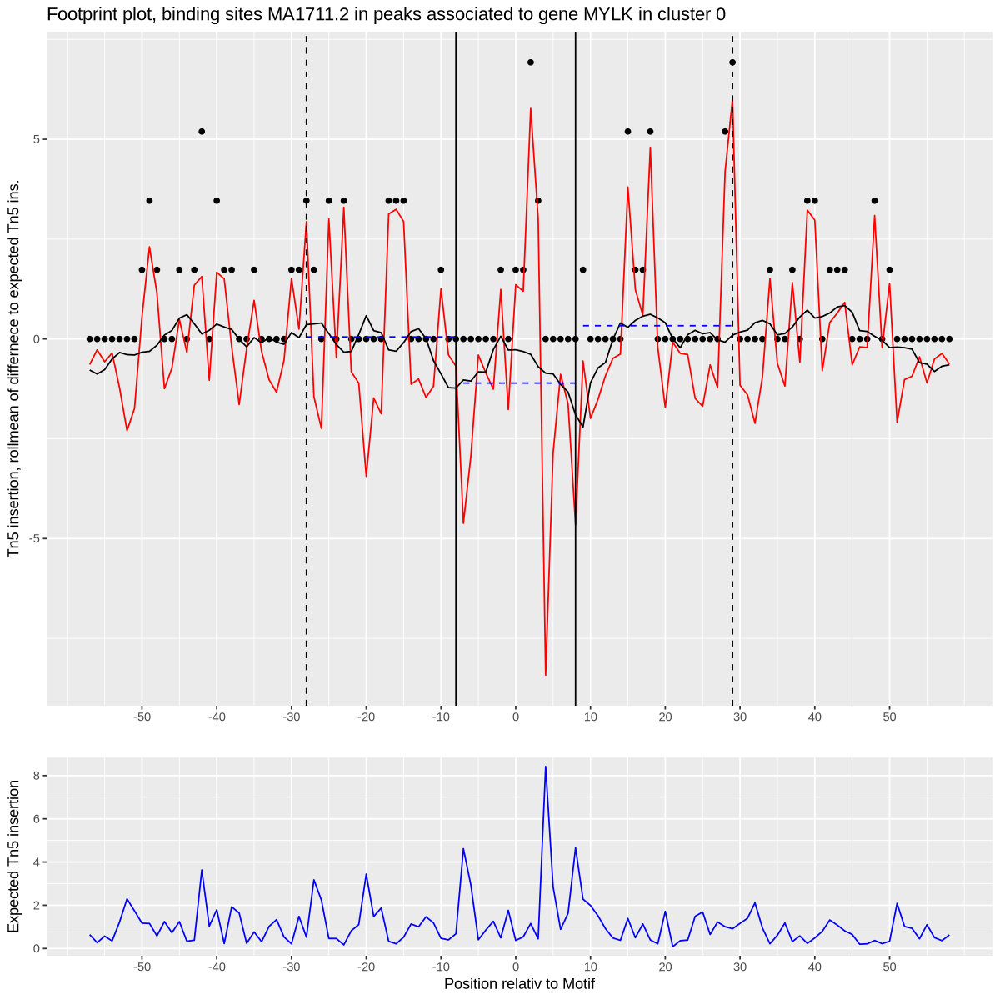

[1] "Plotting footprint for motif: MA1711.2 and gene: MYLK"
[1] "2026-04-08 23:09:08 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr3 123883909-123883924      + |   15.1240
  [2]     chr3 123766339-123766354      - |   12.5539
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:08 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


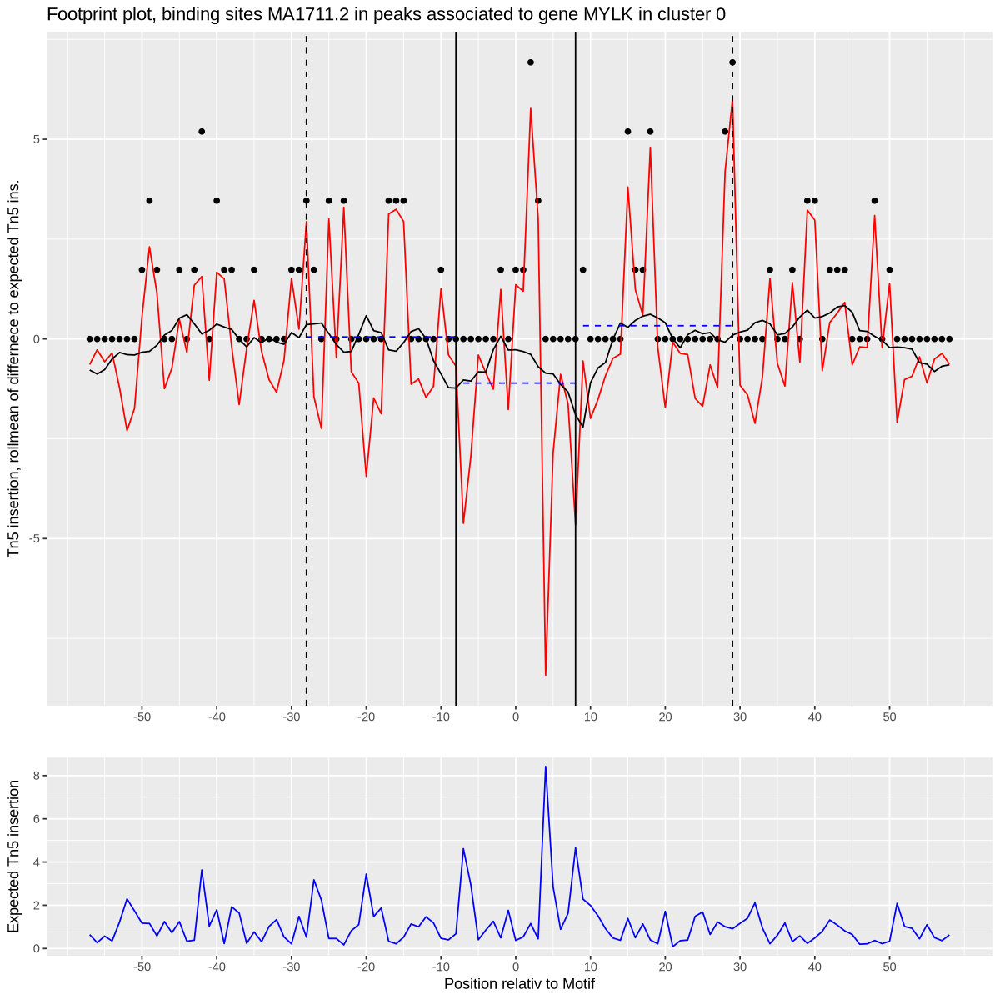

[1] "Footprint plot for gene: KCNMA1"
[1] "Plotting footprint for motif: MA1485.1 and gene: KCNMA1"


computing motifs to gene



[1] "2026-04-08 23:09:11 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr10 77637394-77637407      + |   10.7956
  [2]    chr10 77638464-77638477      + |   10.2537
  [3]    chr10 77637394-77637407      - |   10.8658
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:11 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


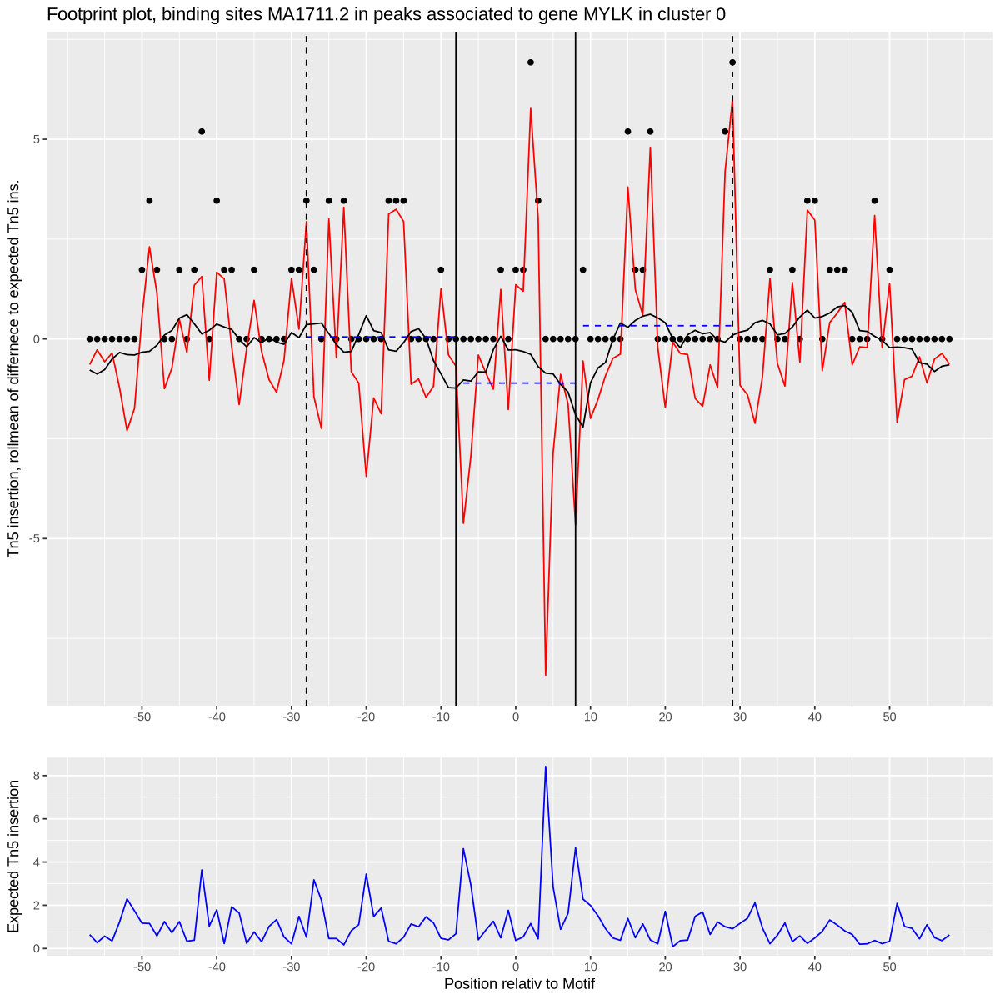

[1] "Plotting footprint for motif: MA1485.1 and gene: KCNMA1"


computing motifs to gene



[1] "2026-04-08 23:09:13 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr10 77637394-77637407      + |   10.7956
  [2]    chr10 77638464-77638477      + |   10.2537
  [3]    chr10 77637394-77637407      - |   10.8658
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:14 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


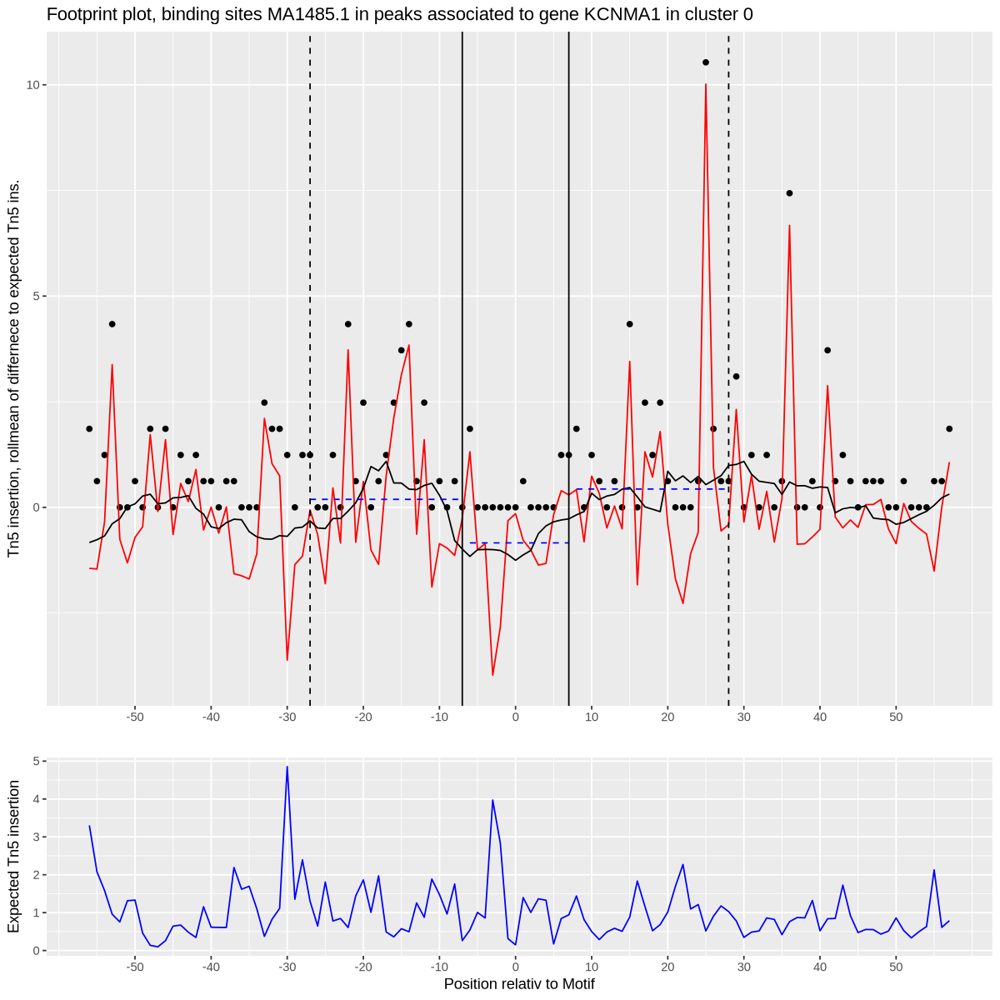

[1] "Plotting footprint for motif: MA1643.2 and gene: KCNMA1"


computing motifs to gene



[1] "2026-04-08 23:09:16 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr10 77638640-77638656      + |   14.4946
  [2]    chr10 77638640-77638656      - |   13.3081
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:16 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


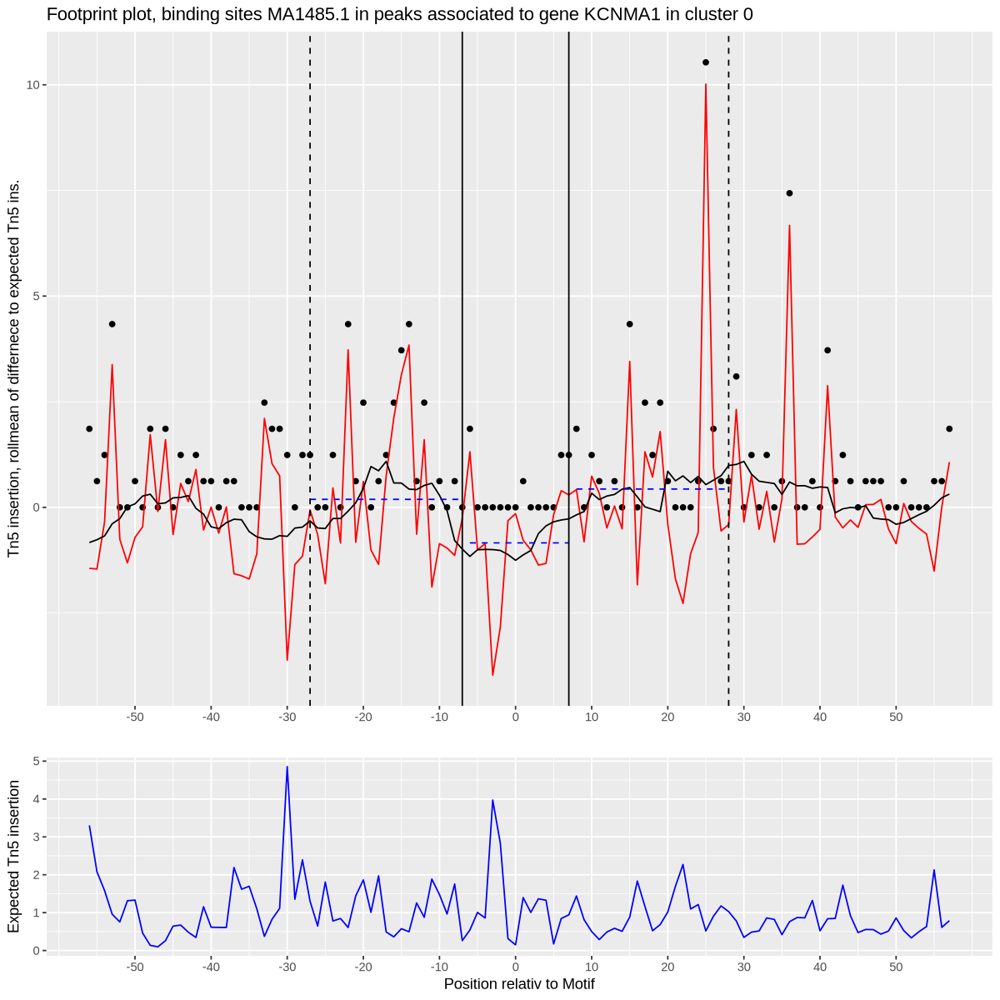

[1] "Plotting footprint for motif: MA1643.2 and gene: KCNMA1"


computing motifs to gene



[1] "2026-04-08 23:09:19 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr10 77638640-77638656      + |   14.4946
  [2]    chr10 77638640-77638656      - |   13.3081
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:19 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


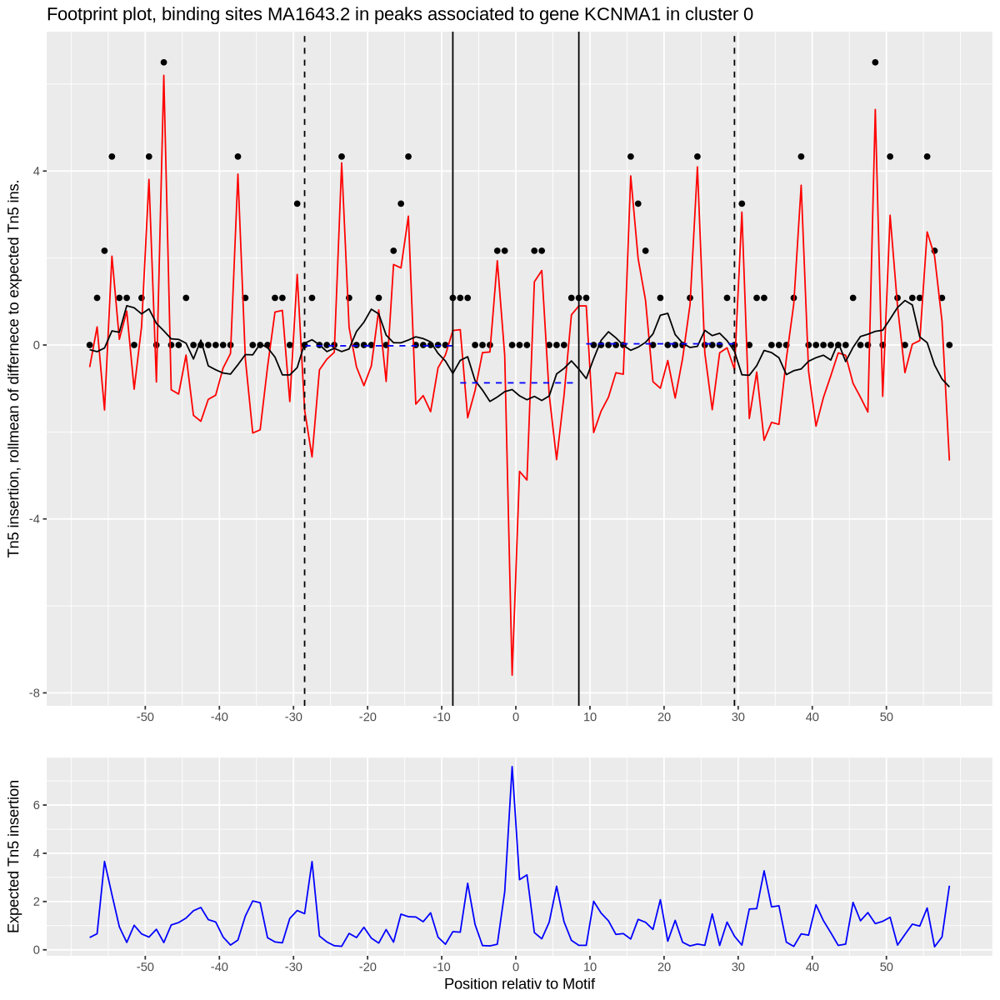

[1] "Plotting footprint for motif: MA1554.2 and gene: KCNMA1"


computing motifs to gene



[1] "2026-04-08 23:09:21 CEST"
GRanges object with 1 range and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr10 77637646-77637653      - |   12.5432
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:21 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


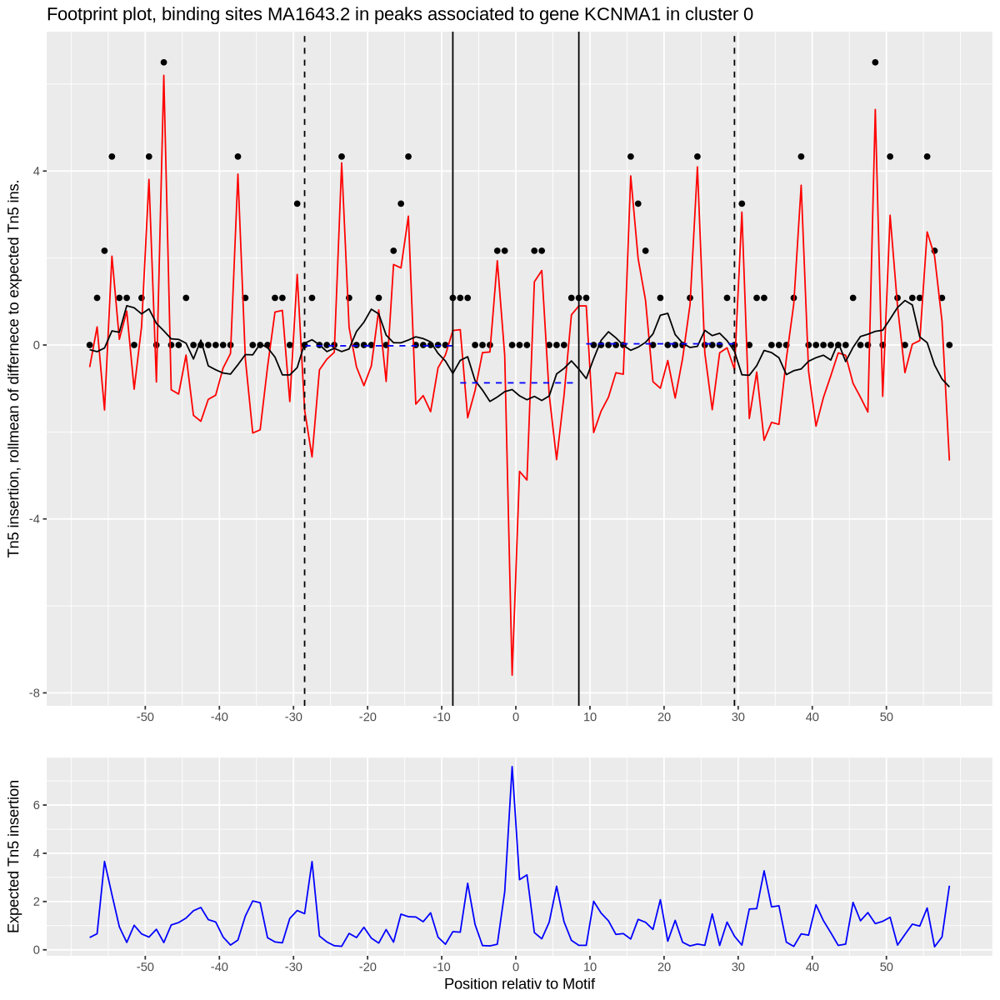

[1] "Plotting footprint for motif: MA1584.2 and gene: KCNMA1"


computing motifs to gene



[1] "2026-04-08 23:09:23 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr10 77637085-77637099      + |   12.3649
  [2]    chr10 77638046-77638060      + |   13.7896
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:24 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


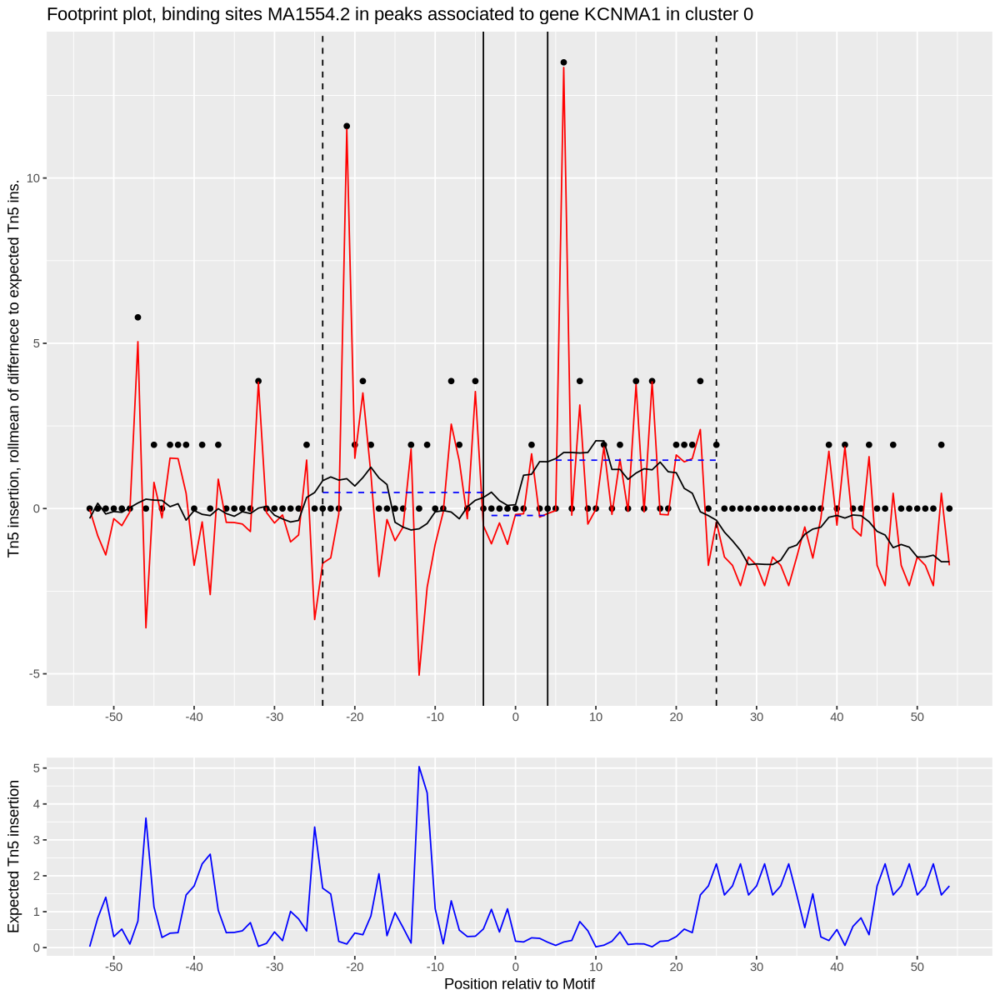

[1] "Plotting footprint for motif: MA1584.2 and gene: KCNMA1"


computing motifs to gene



[1] "2026-04-08 23:09:26 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr10 77637085-77637099      + |   12.3649
  [2]    chr10 77638046-77638060      + |   13.7896
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:26 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


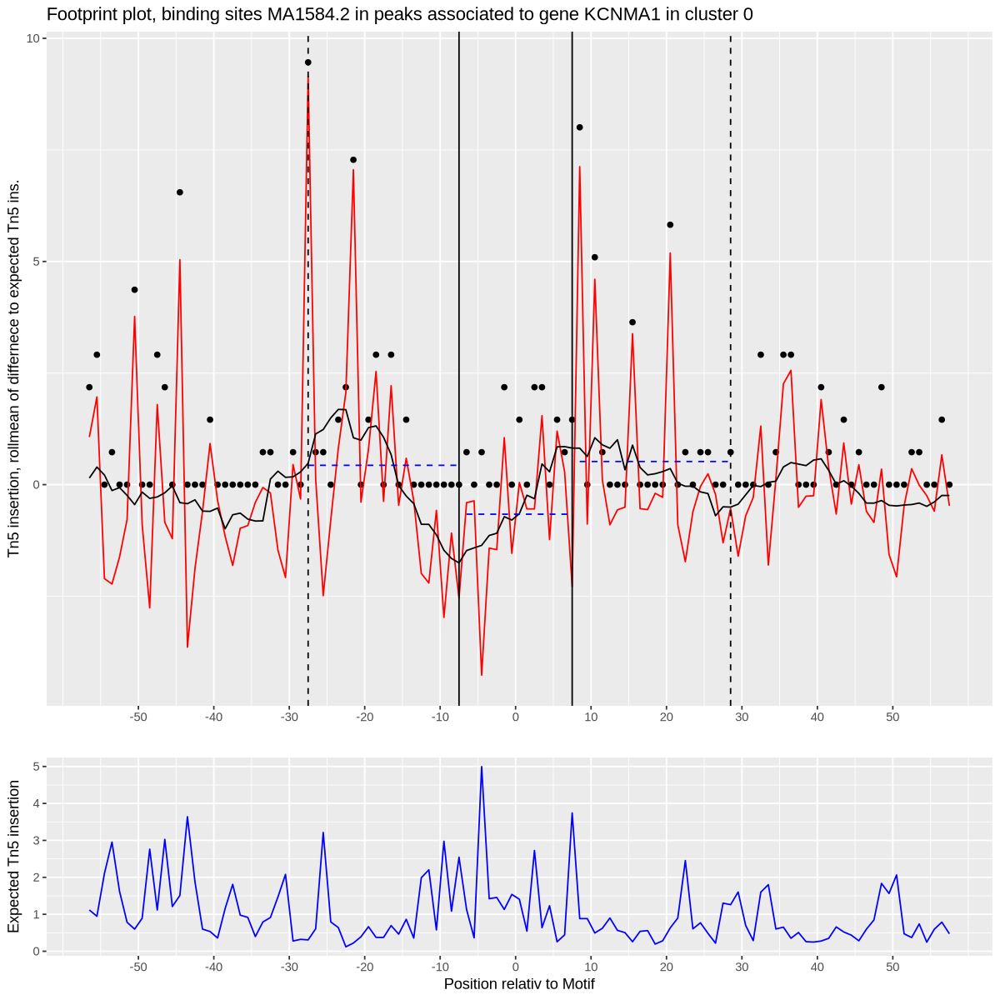

[1] "Plotting footprint for motif: MA1652.2 and gene: KCNMA1"


computing motifs to gene



[1] "2026-04-08 23:09:29 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr10 77638514-77638522      + |   11.4054
  [2]    chr10 77638765-77638773      + |   11.4054
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:29 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


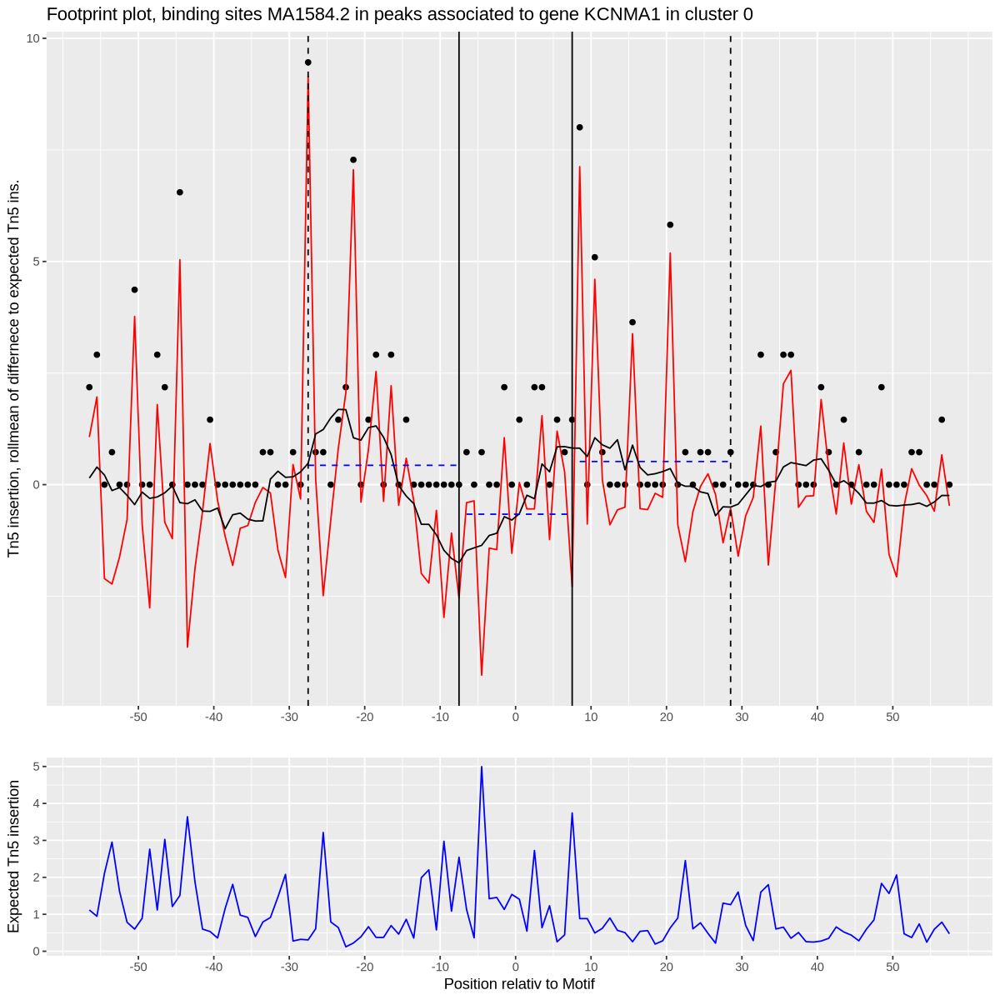

[1] "Plotting footprint for motif: MA1652.2 and gene: KCNMA1"


computing motifs to gene



[1] "2026-04-08 23:09:32 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr10 77638514-77638522      + |   11.4054
  [2]    chr10 77638765-77638773      + |   11.4054
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:32 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


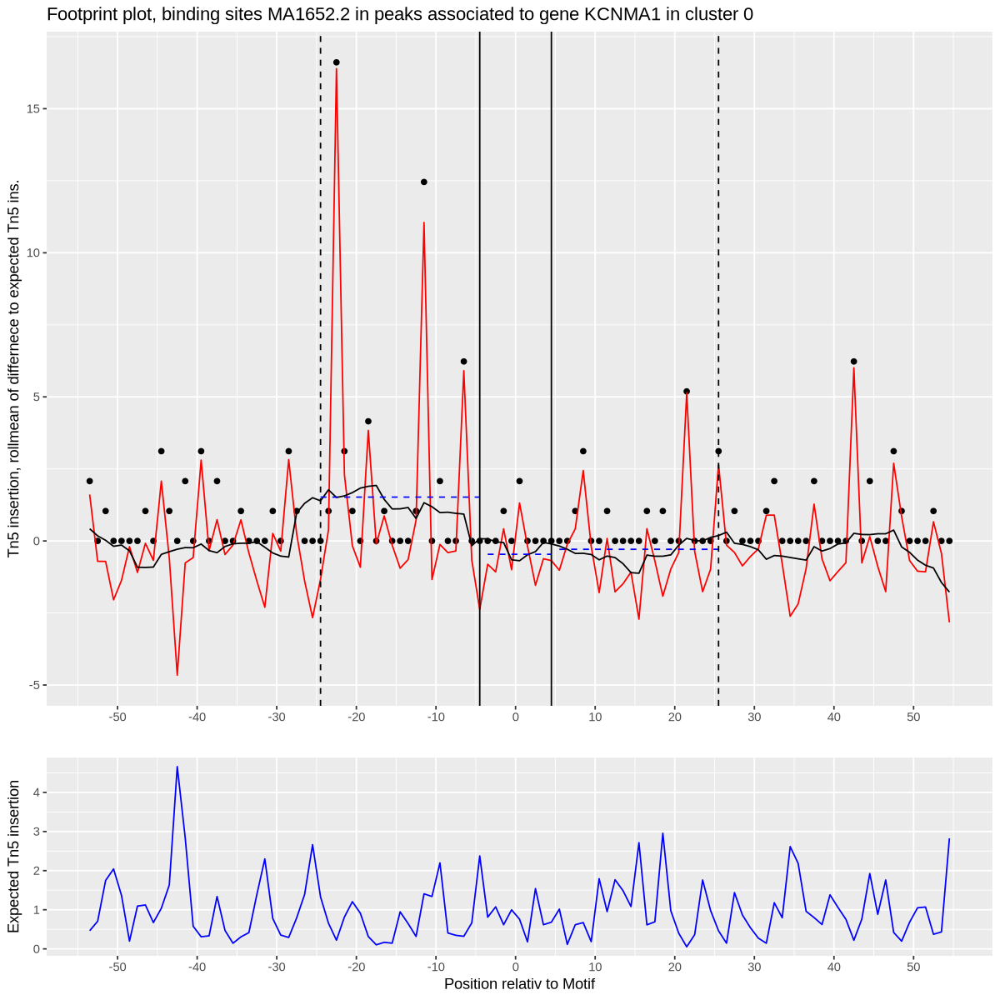

[1] "Plotting footprint for motif: MA1730.2 and gene: KCNMA1"


computing motifs to gene



[1] "2026-04-08 23:09:34 CEST"
GRanges object with 1 range and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr10 77637169-77637177      - |   13.2862
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:34 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


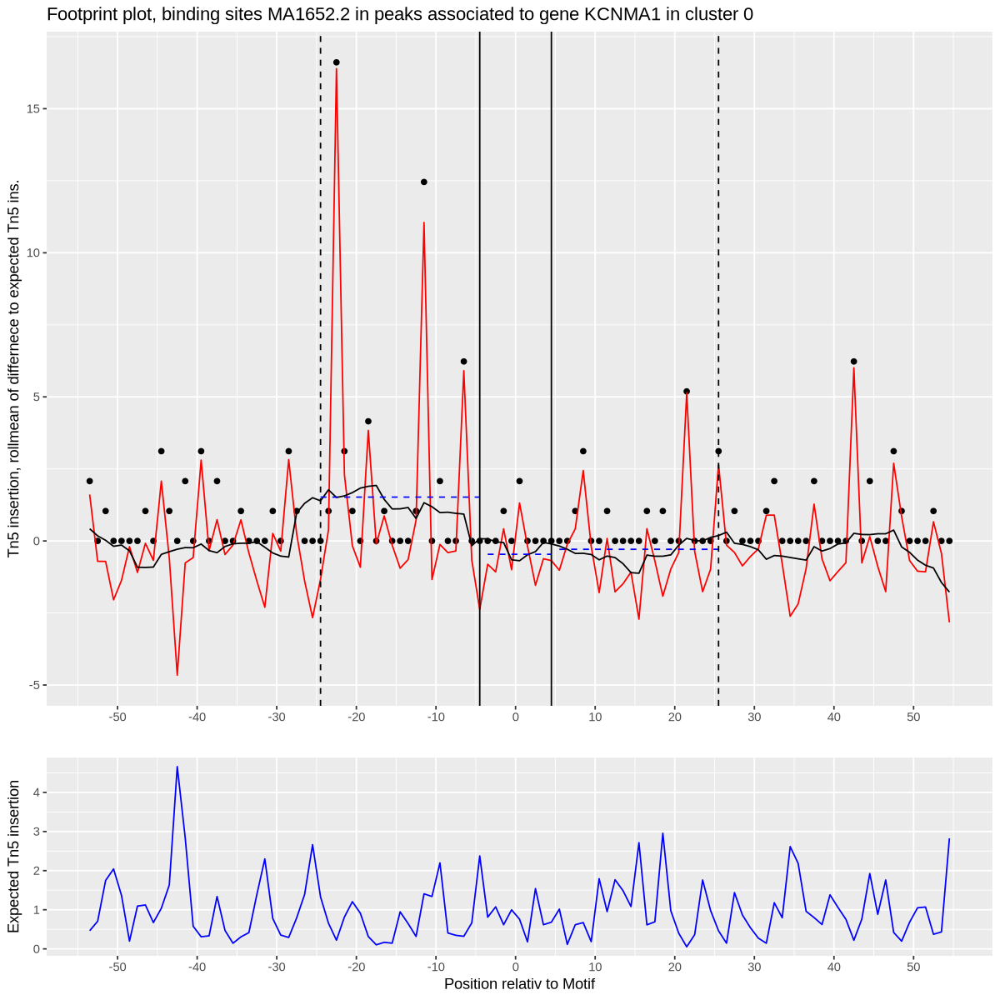

[1] "Plotting footprint for motif: MA1730.2 and gene: KCNMA1"


computing motifs to gene



[1] "2026-04-08 23:09:36 CEST"
GRanges object with 1 range and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr10 77637169-77637177      - |   13.2862
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:37 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


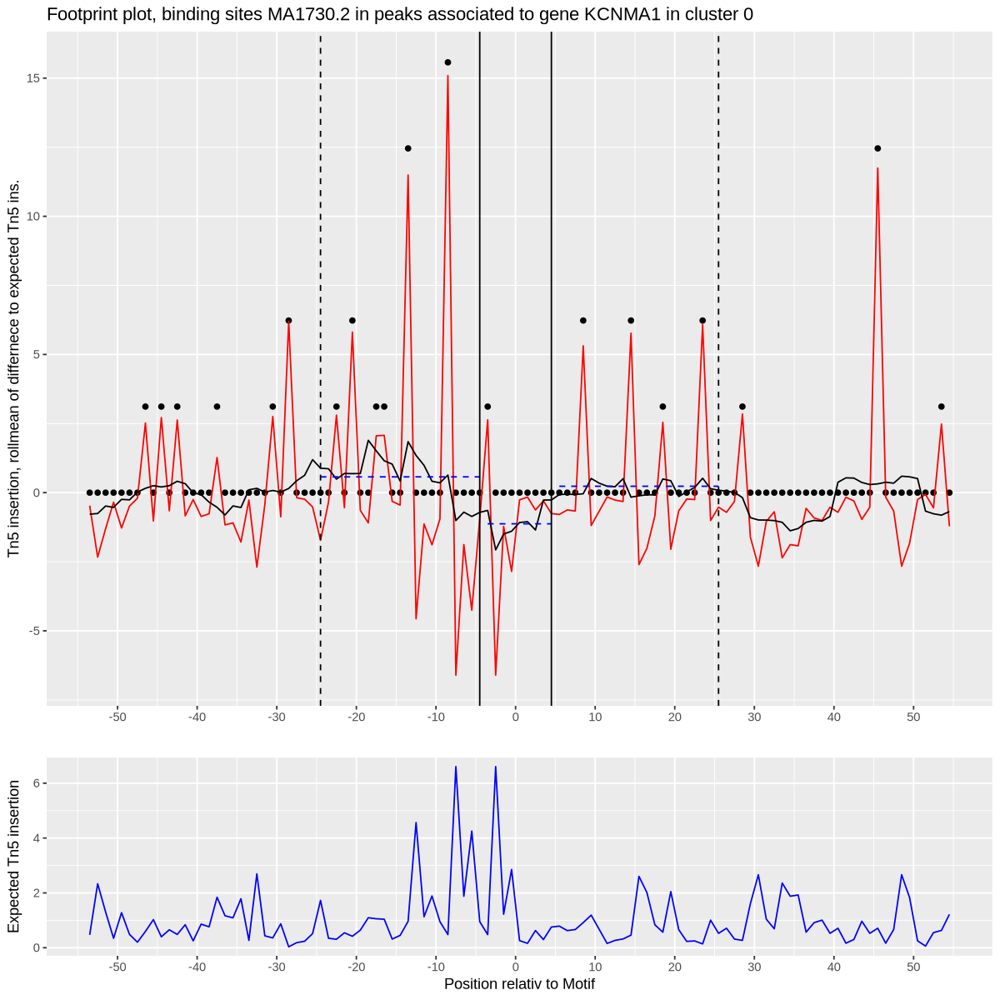

[1] "Plotting footprint for motif: MA1721.2 and gene: KCNMA1"


computing motifs to gene



[1] "2026-04-08 23:09:39 CEST"
GRanges object with 28 ranges and 1 metadata column:
       seqnames            ranges strand |     score
          <Rle>         <IRanges>  <Rle> | <numeric>
   [1]    chr10 77638457-77638470      + |   17.3618
   [2]    chr10 77638460-77638473      + |   16.9004
   [3]    chr10 77638463-77638476      + |   13.4727
   [4]    chr10 77638577-77638590      + |   14.2629
   [5]    chr10 77637578-77637591      - |   14.0122
   ...      ...               ...    ... .       ...
  [24]    chr10 77637745-77637758      - |   21.7902
  [25]    chr10 77637748-77637761      - |   19.3589
  [26]    chr10 77637843-77637856      - |   13.6150
  [27]    chr10 77637846-77637859      - |   16.3897
  [28]    chr10 77638449-77638462      - |   14.5143
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:39 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


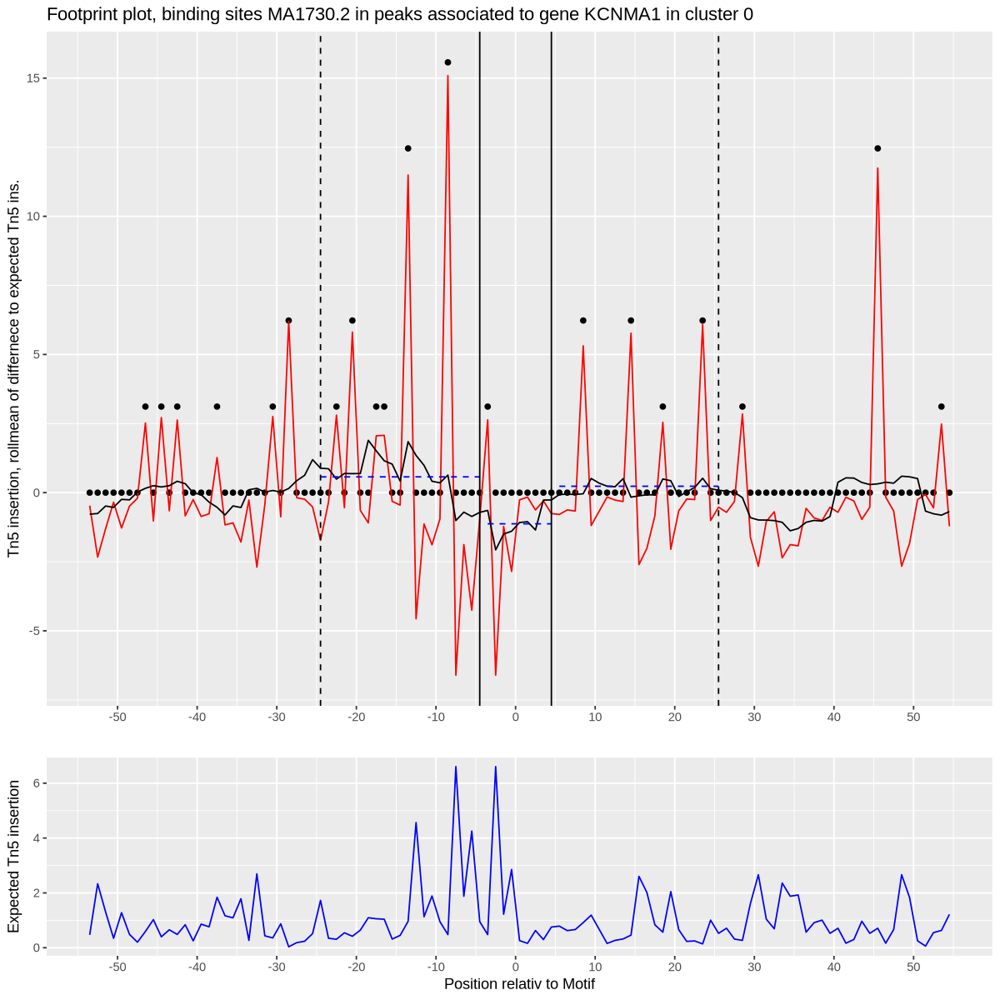

[1] "Plotting footprint for motif: MA1721.2 and gene: KCNMA1"


computing motifs to gene



[1] "2026-04-08 23:09:43 CEST"
GRanges object with 28 ranges and 1 metadata column:
       seqnames            ranges strand |     score
          <Rle>         <IRanges>  <Rle> | <numeric>
   [1]    chr10 77638457-77638470      + |   17.3618
   [2]    chr10 77638460-77638473      + |   16.9004
   [3]    chr10 77638463-77638476      + |   13.4727
   [4]    chr10 77638577-77638590      + |   14.2629
   [5]    chr10 77637578-77637591      - |   14.0122
   ...      ...               ...    ... .       ...
  [24]    chr10 77637745-77637758      - |   21.7902
  [25]    chr10 77637748-77637761      - |   19.3589
  [26]    chr10 77637843-77637856      - |   13.6150
  [27]    chr10 77637846-77637859      - |   16.3897
  [28]    chr10 77638449-77638462      - |   14.5143
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:43 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


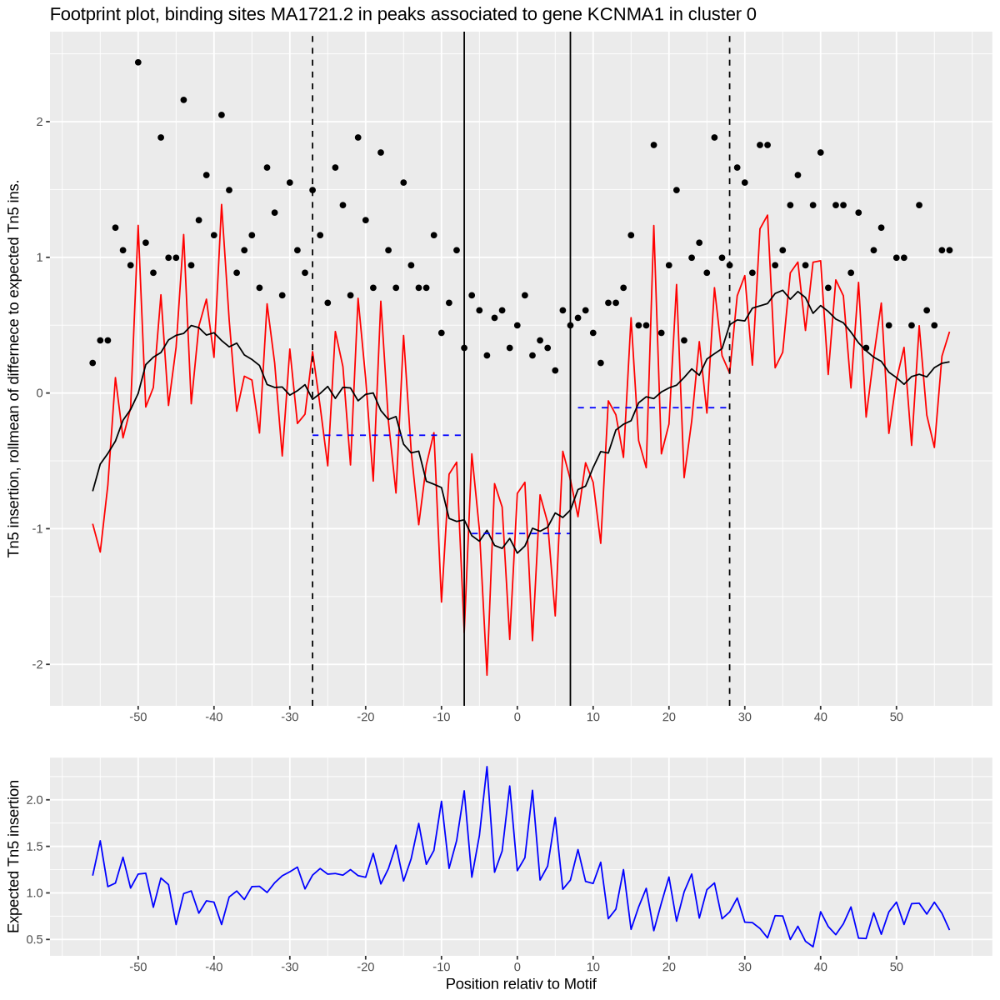

[1] "Footprint plot for gene: MYH11"
[1] "Plotting footprint for motif: MA0119.1 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:09:47 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15858256-15858269      + |   15.3709
  [2]    chr16 15858255-15858268      - |   11.2995
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:48 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


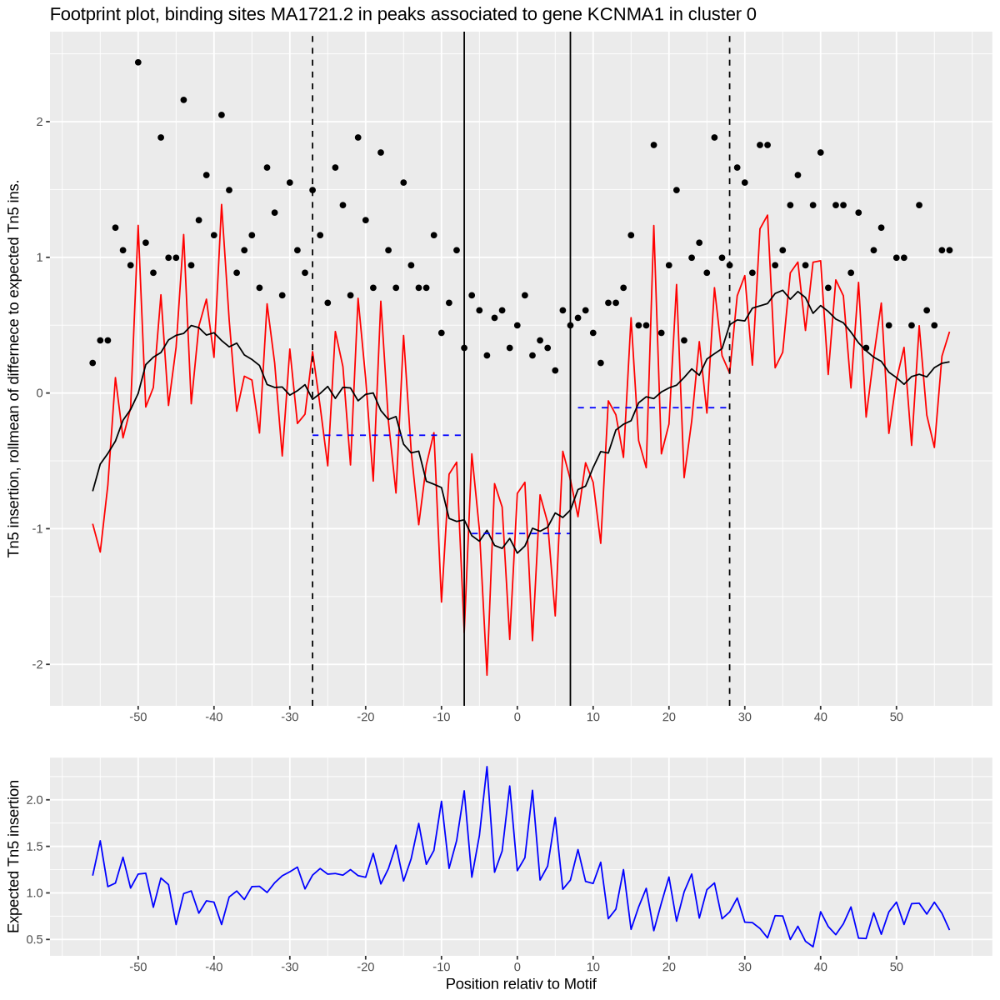

[1] "Plotting footprint for motif: MA0119.1 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:09:54 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15858256-15858269      + |   15.3709
  [2]    chr16 15858255-15858268      - |   11.2995
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:54 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


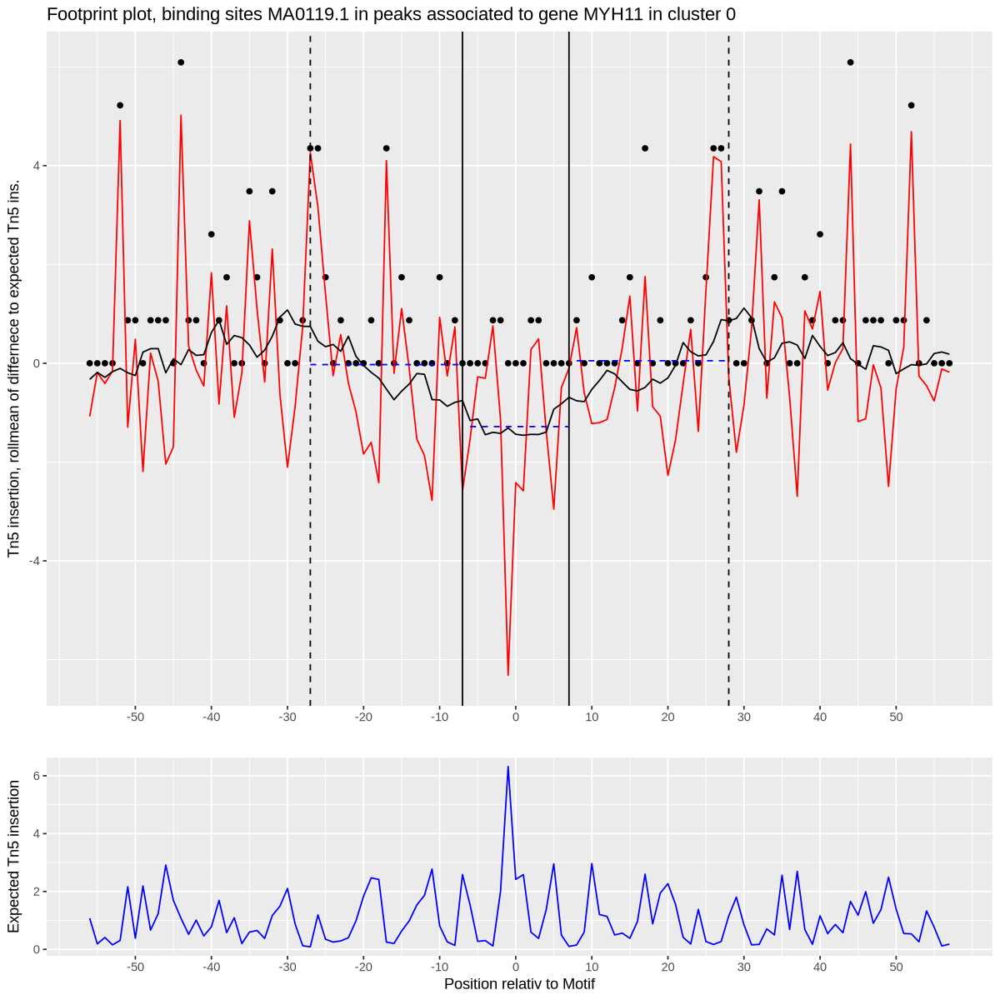

[1] "Plotting footprint for motif: MA0119.1 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:09:57 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15858256-15858269      + |   15.3709
  [2]    chr16 15858255-15858268      - |   11.2995
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:09:58 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


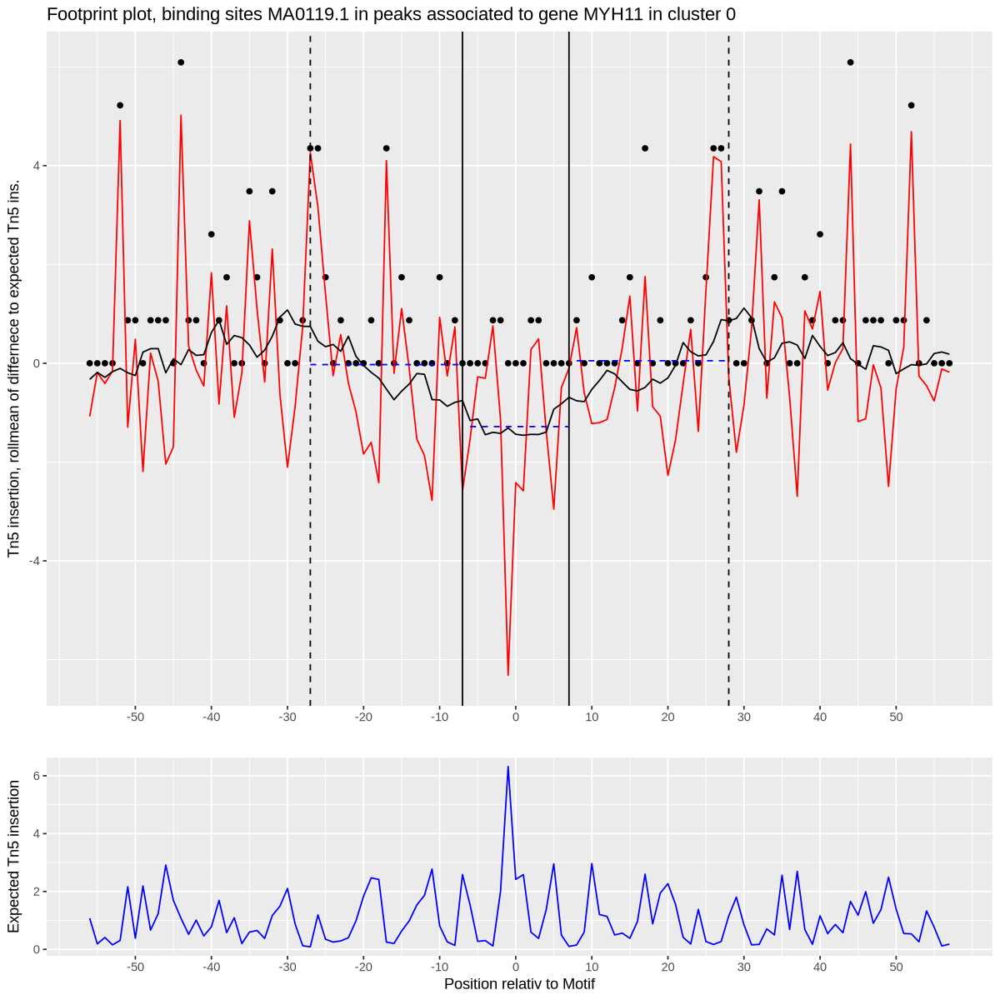

[1] "Plotting footprint for motif: MA0119.1 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:01 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15858256-15858269      + |   15.3709
  [2]    chr16 15858255-15858268      - |   11.2995
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:01 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


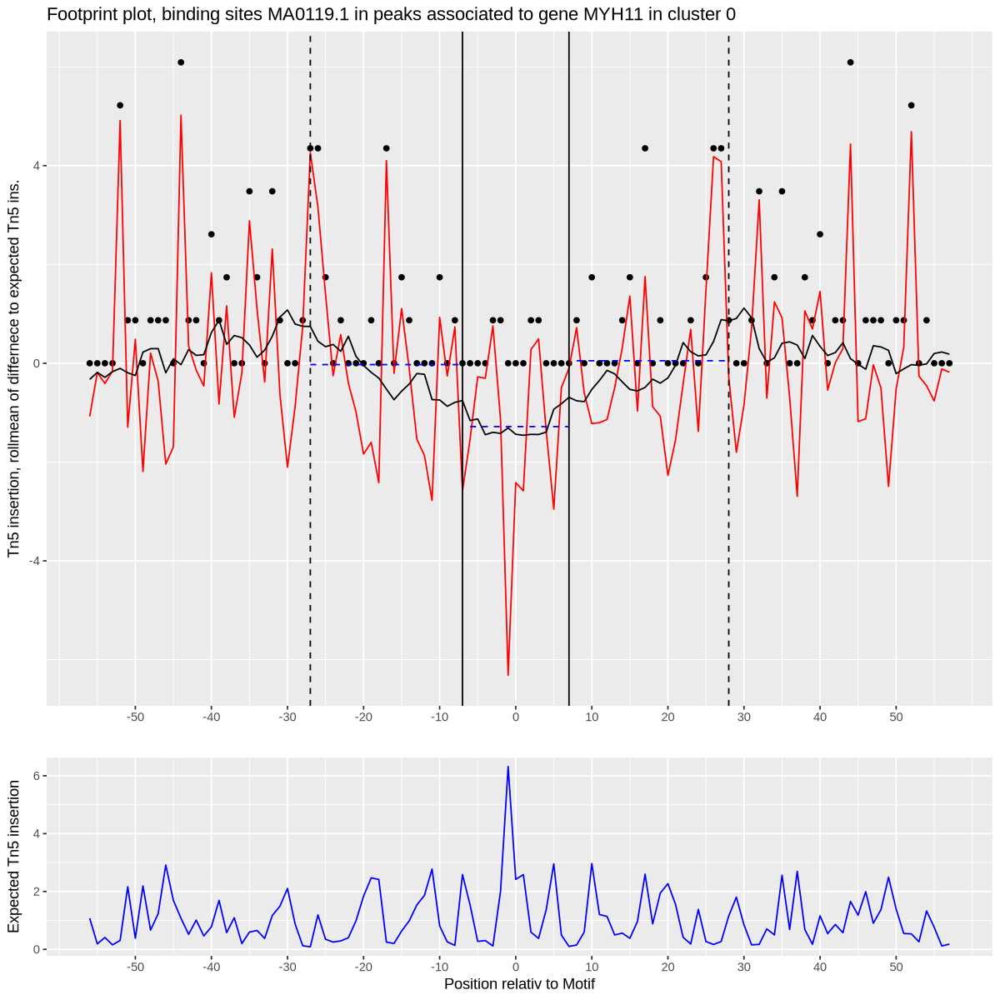

[1] "Plotting footprint for motif: MA0119.1 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:04 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15858256-15858269      + |   15.3709
  [2]    chr16 15858255-15858268      - |   11.2995
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:04 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


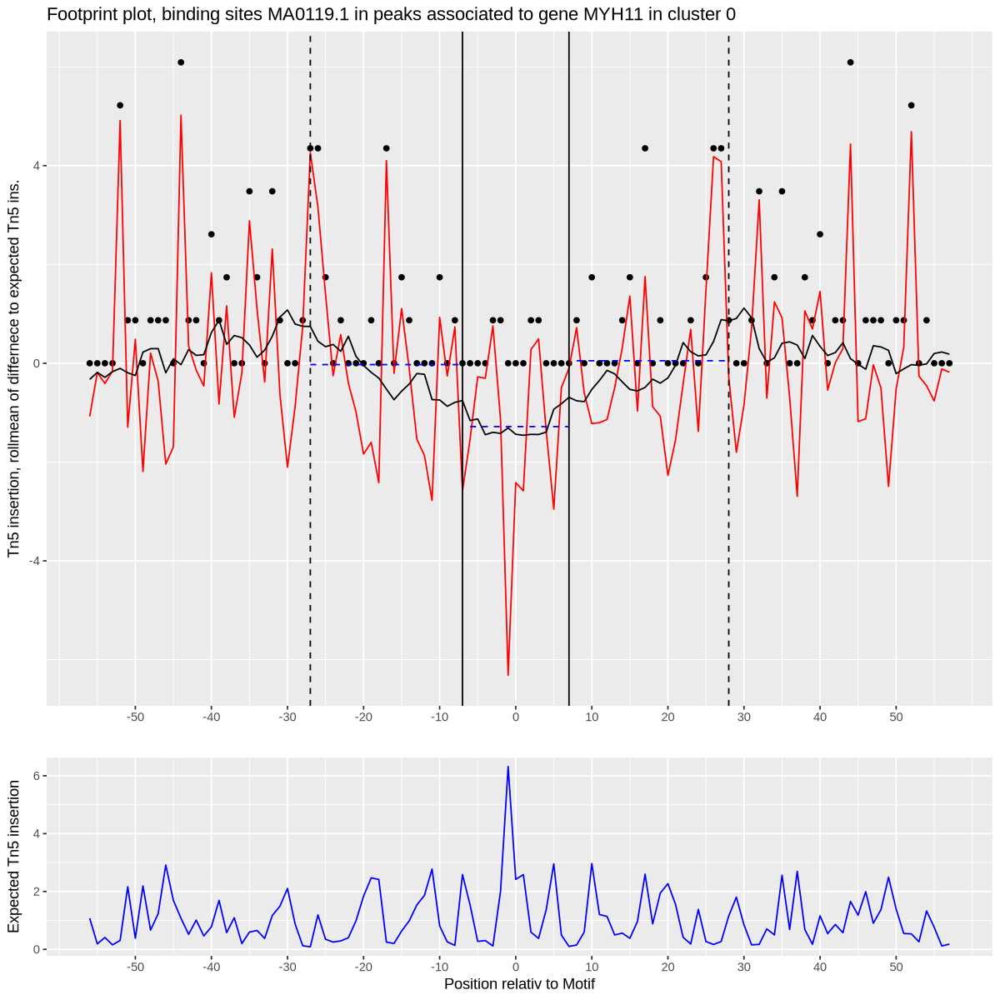

[1] "Plotting footprint for motif: MA0119.1 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:07 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15858256-15858269      + |   15.3709
  [2]    chr16 15858255-15858268      - |   11.2995
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:07 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


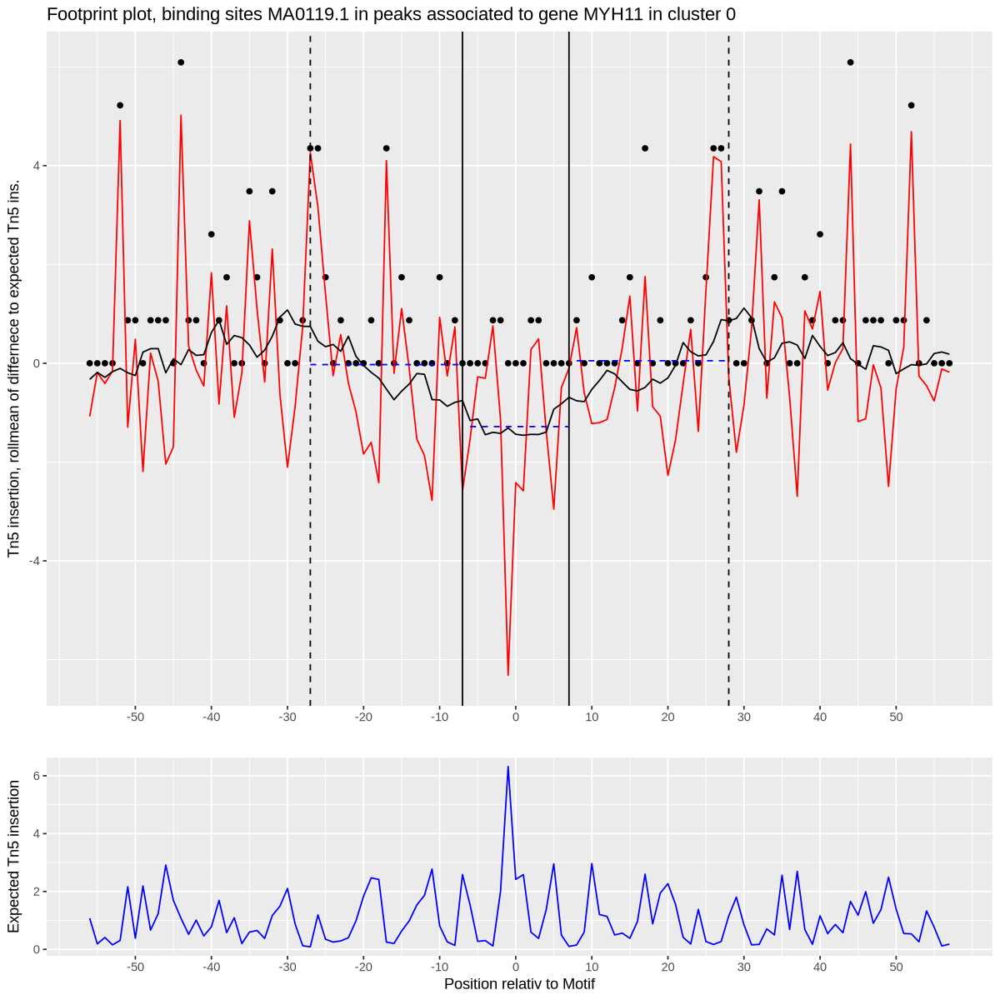

[1] "Plotting footprint for motif: MA0149.1 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:10 CEST"
GRanges object with 5 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15858182-15858199      - |  -2.44876
  [2]    chr16 15807725-15807742      - |   5.77750
  [3]    chr16 15807729-15807746      - |  -3.21036
  [4]    chr16 15807732-15807749      - |  -3.16578
  [5]    chr16 15807733-15807750      - |  -2.68196
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:10 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


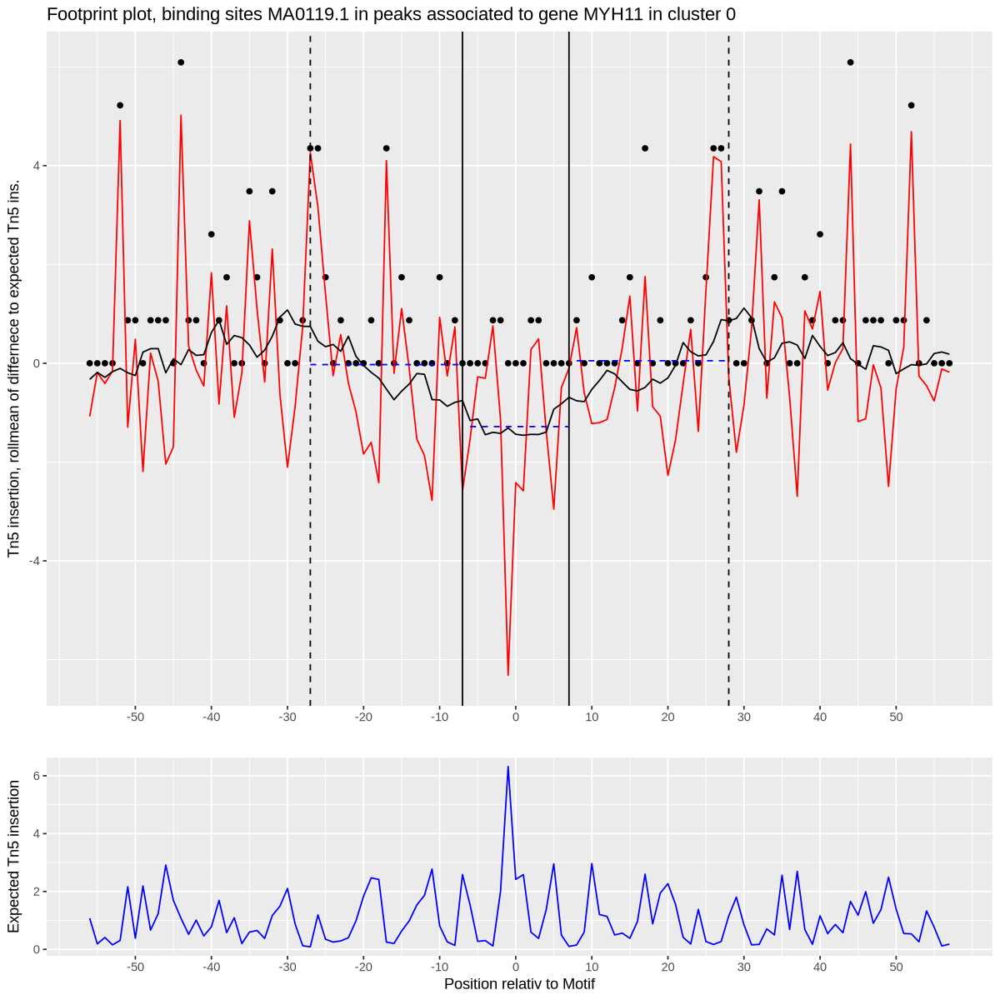

[1] "Plotting footprint for motif: MA0149.1 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:13 CEST"
GRanges object with 5 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15858182-15858199      - |  -2.44876
  [2]    chr16 15807725-15807742      - |   5.77750
  [3]    chr16 15807729-15807746      - |  -3.21036
  [4]    chr16 15807732-15807749      - |  -3.16578
  [5]    chr16 15807733-15807750      - |  -2.68196
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:13 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


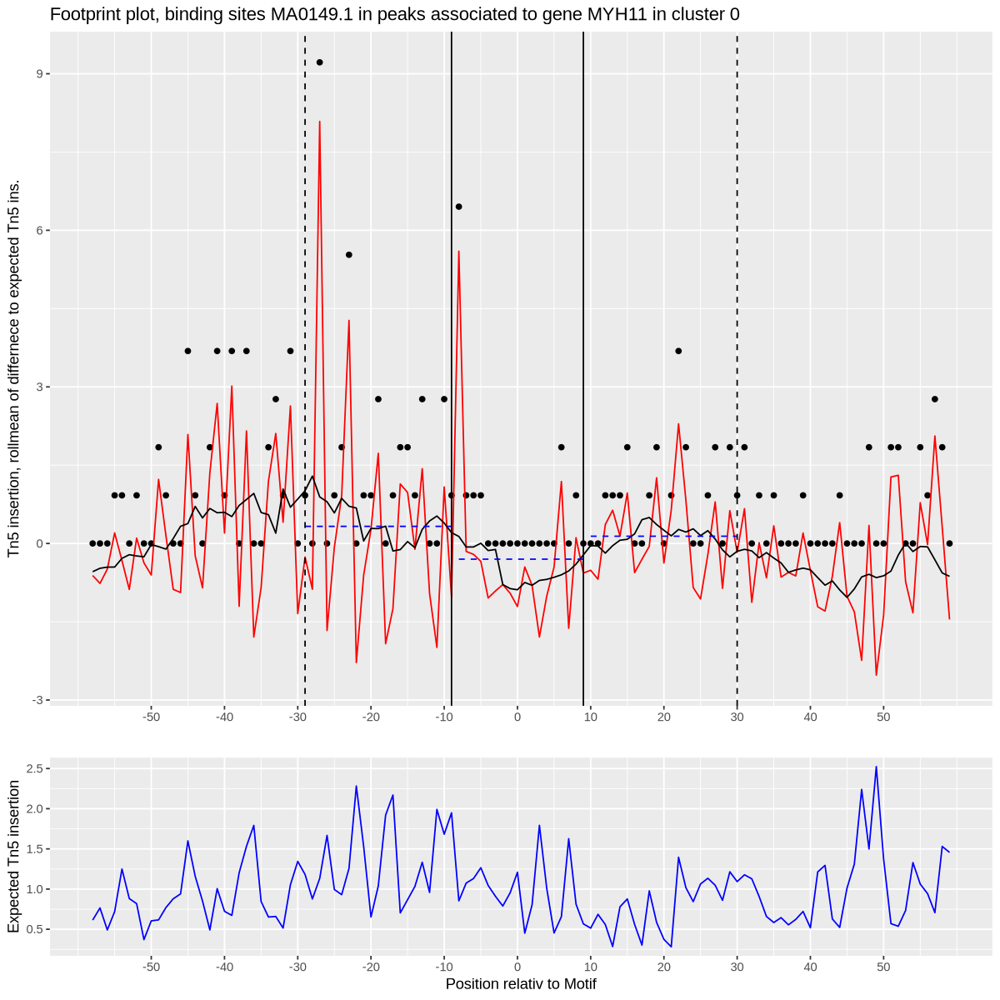

[1] "Plotting footprint for motif: MA0149.1 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:16 CEST"
GRanges object with 5 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15858182-15858199      - |  -2.44876
  [2]    chr16 15807725-15807742      - |   5.77750
  [3]    chr16 15807729-15807746      - |  -3.21036
  [4]    chr16 15807732-15807749      - |  -3.16578
  [5]    chr16 15807733-15807750      - |  -2.68196
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:16 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


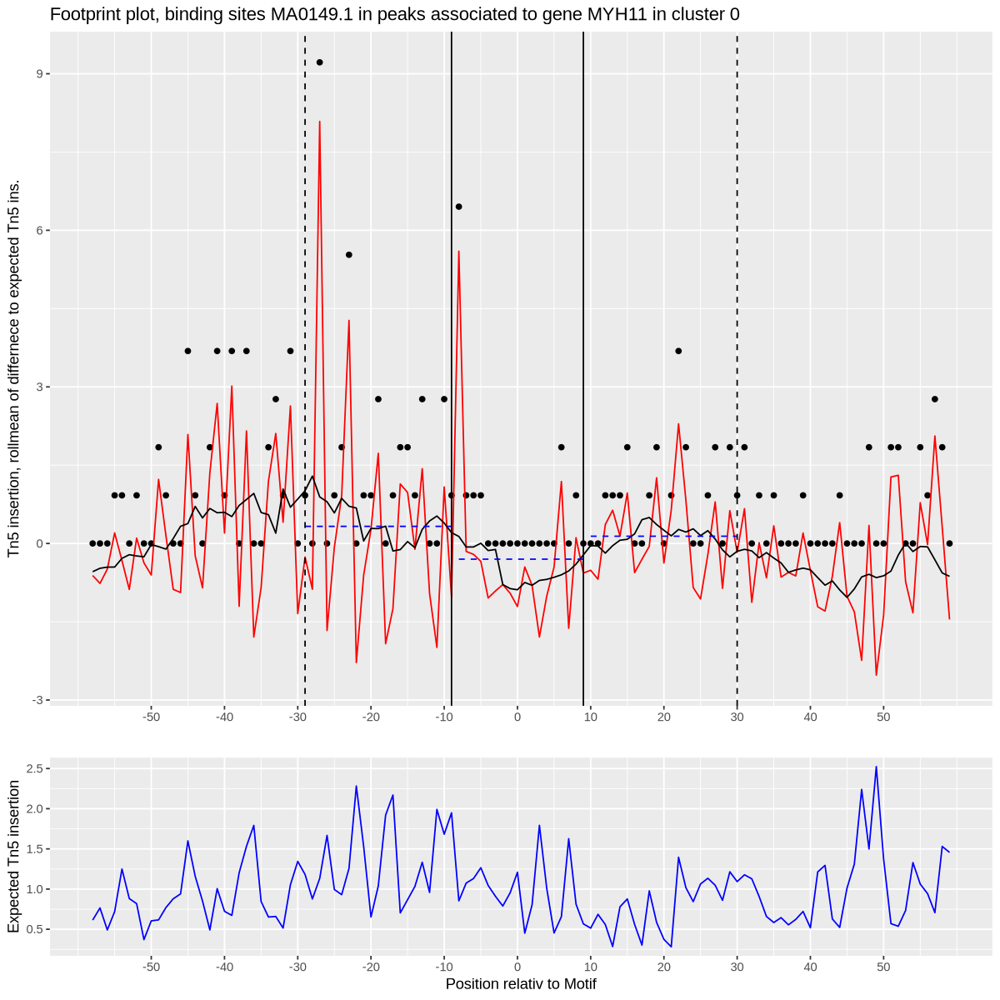

[1] "Plotting footprint for motif: MA1643.2 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:19 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15858254-15858270      + |   16.6643
  [2]    chr16 15858254-15858270      - |   16.7563
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:19 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


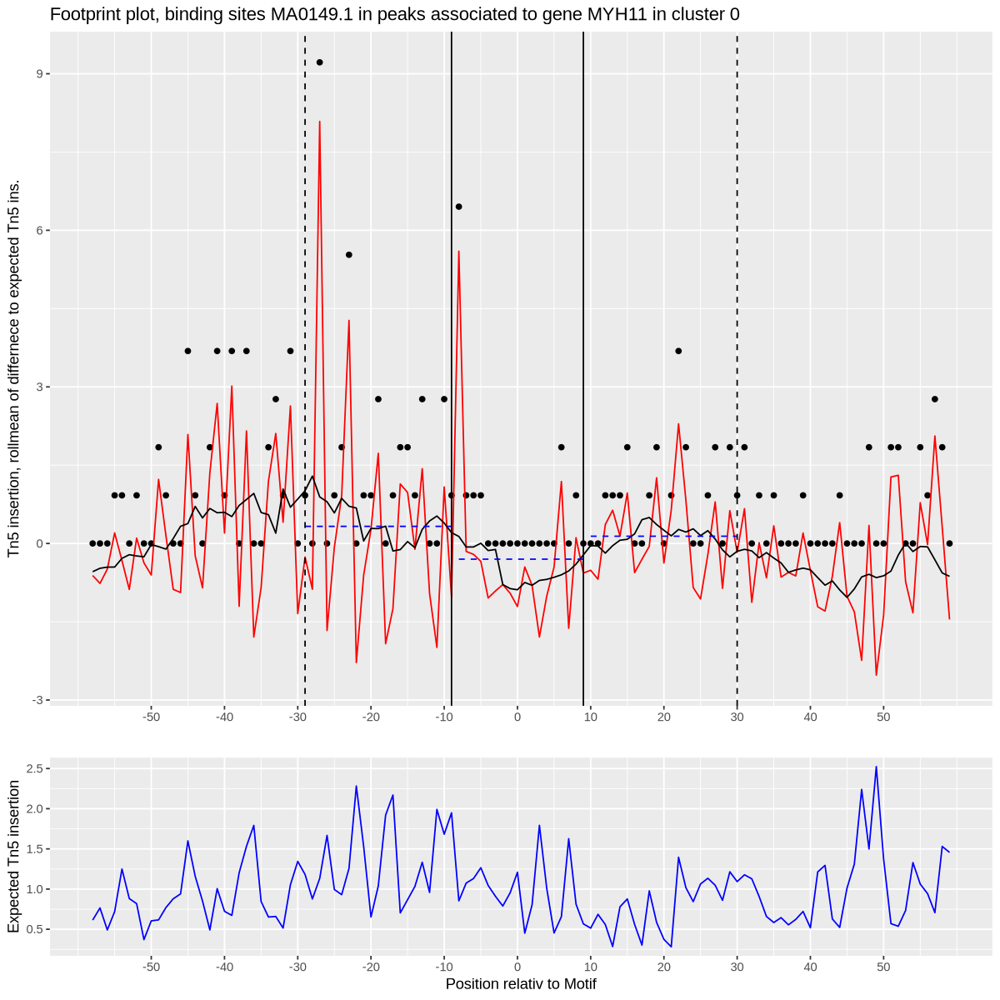

[1] "Plotting footprint for motif: MA1643.2 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:22 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15858254-15858270      + |   16.6643
  [2]    chr16 15858254-15858270      - |   16.7563
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:22 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


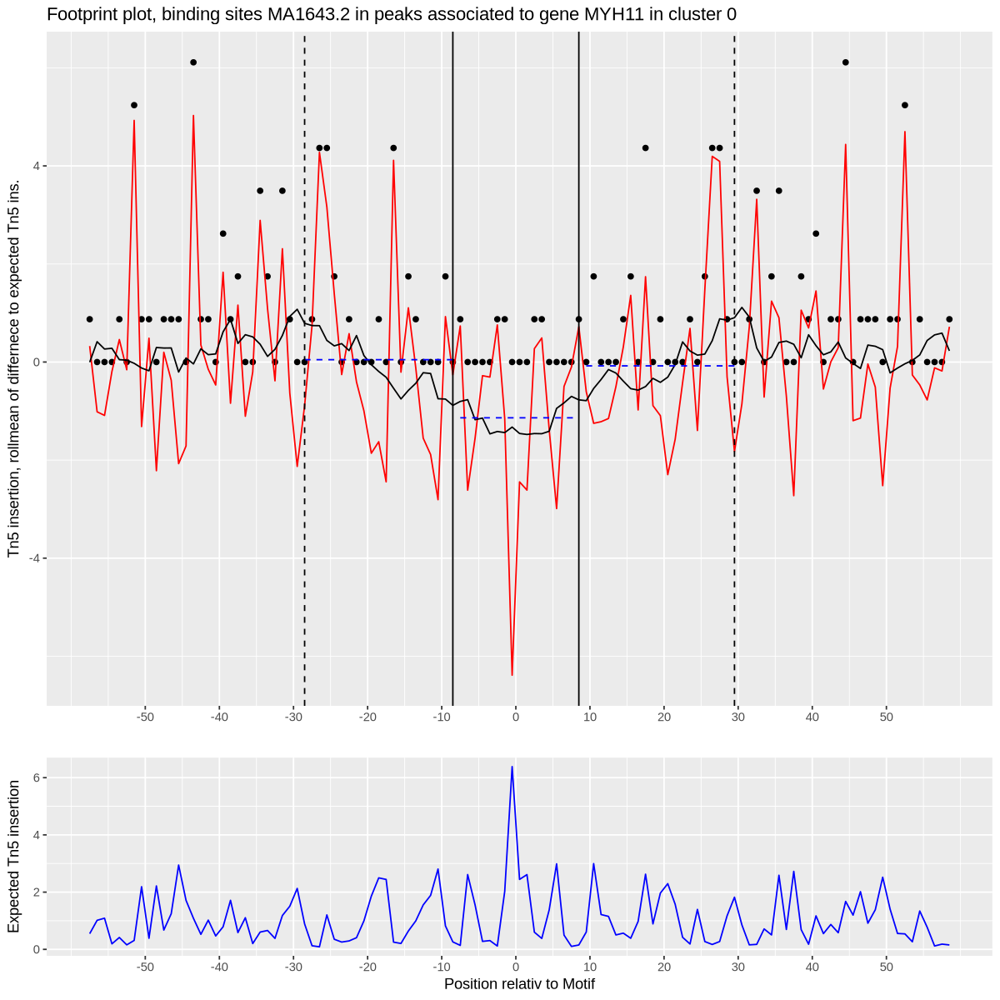

[1] "Plotting footprint for motif: MA1643.2 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:25 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15858254-15858270      + |   16.6643
  [2]    chr16 15858254-15858270      - |   16.7563
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:25 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


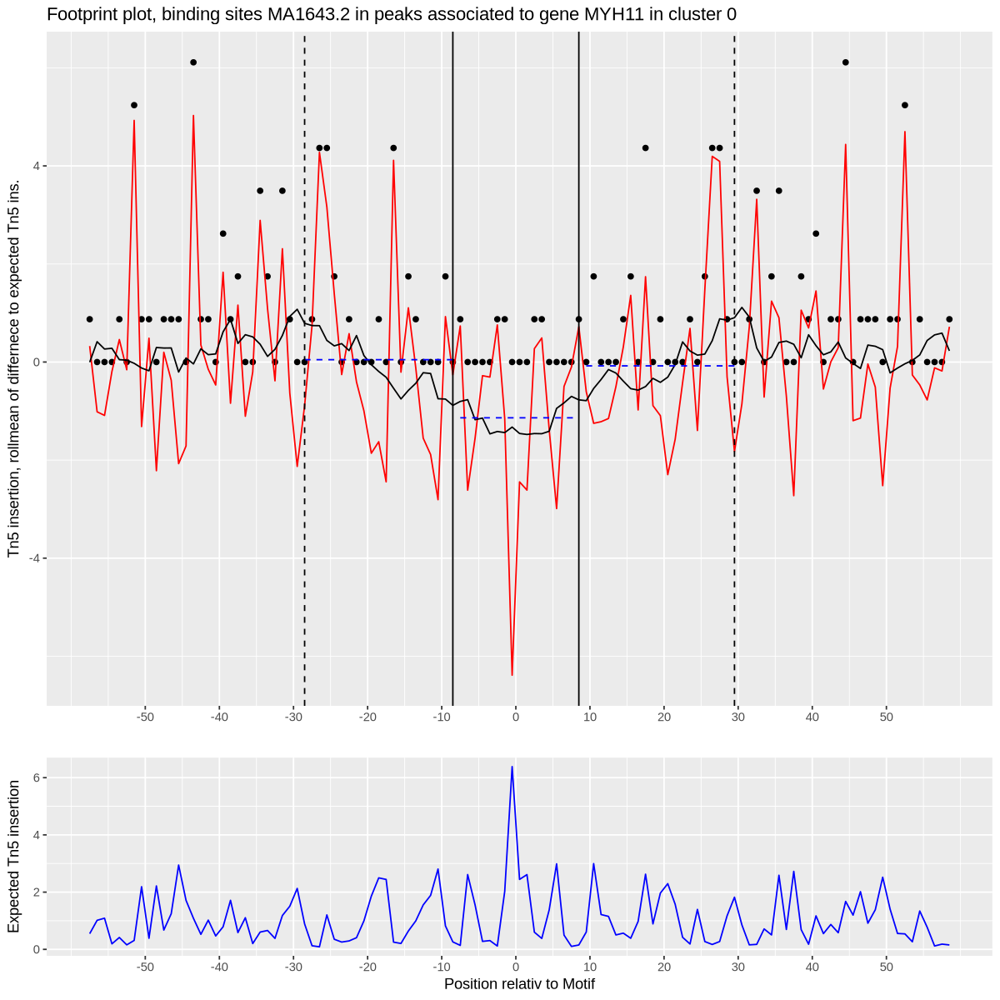

[1] "Plotting footprint for motif: MA1527.2 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:28 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15858255-15858269      + |   17.4892
  [2]    chr16 15858255-15858269      - |   17.2984
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:29 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


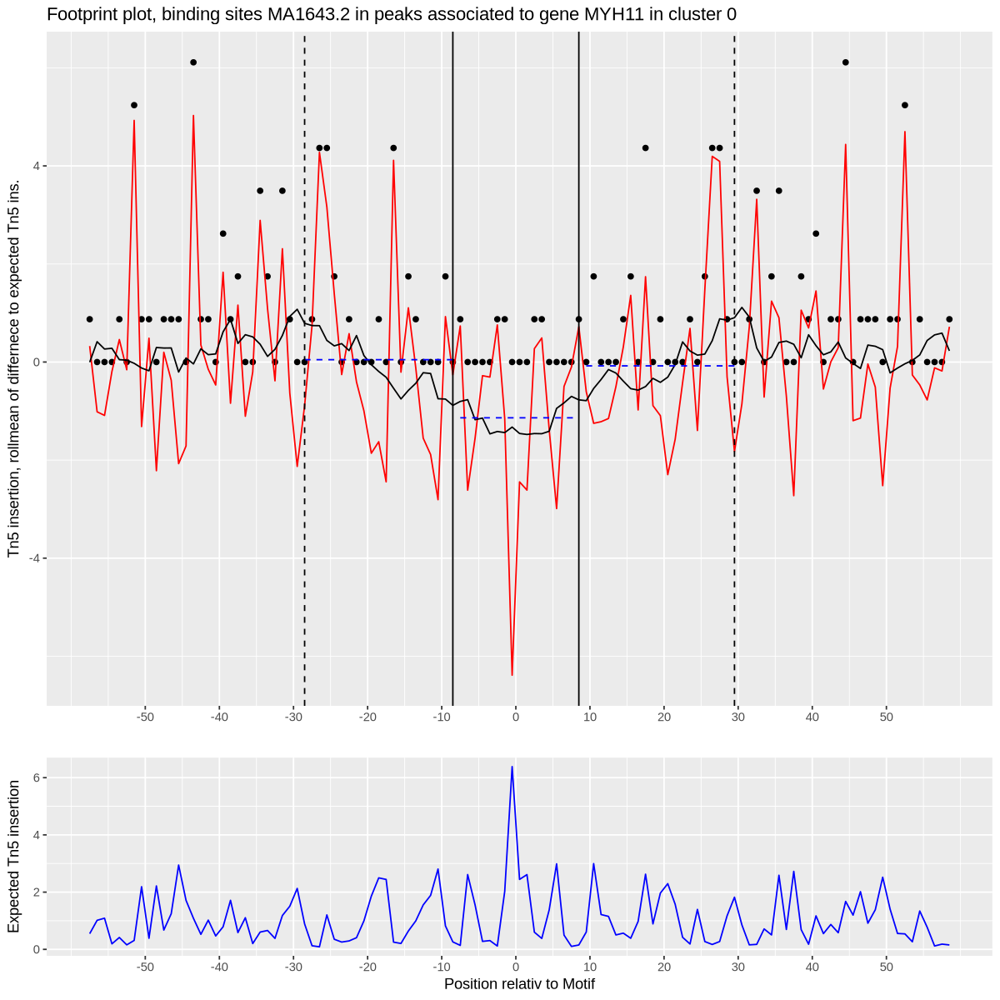

[1] "Plotting footprint for motif: MA1527.2 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:32 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15858255-15858269      + |   17.4892
  [2]    chr16 15858255-15858269      - |   17.2984
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:32 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


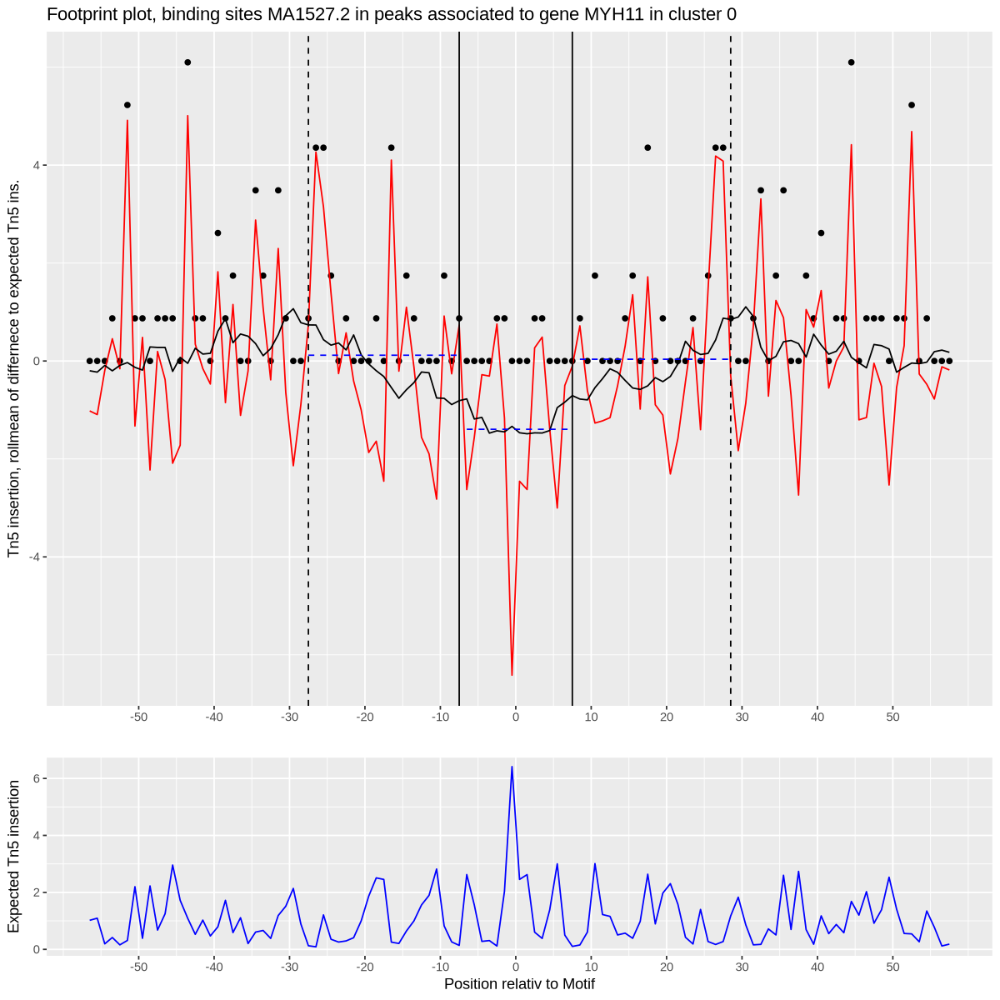

[1] "Plotting footprint for motif: MA1528.2 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:35 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15858255-15858268      + |   15.0209
  [2]    chr16 15858256-15858269      - |   16.1059
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:35 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


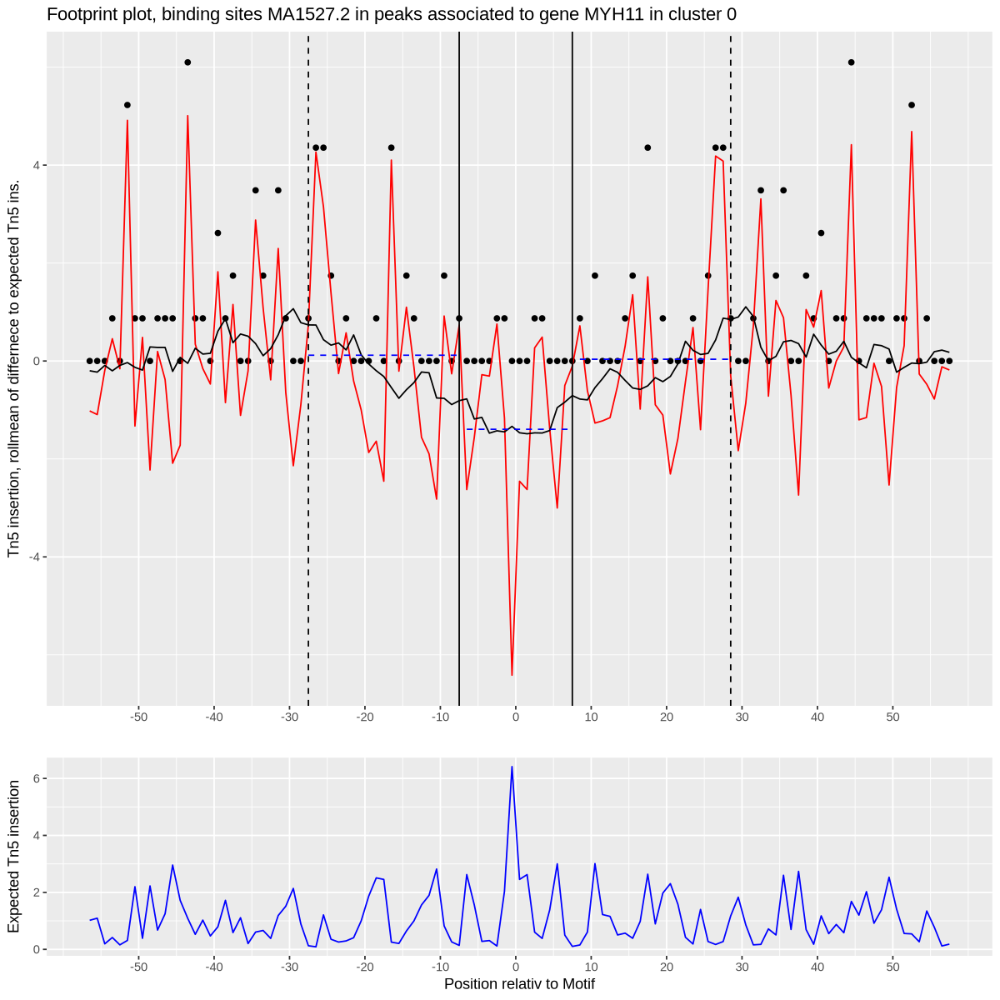

[1] "Plotting footprint for motif: MA0003.5 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:38 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15857274-15857282      + |   13.2066
  [2]    chr16 15807781-15807789      + |   13.2066
  [3]    chr16 15807660-15807668      - |   13.2066
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:38 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


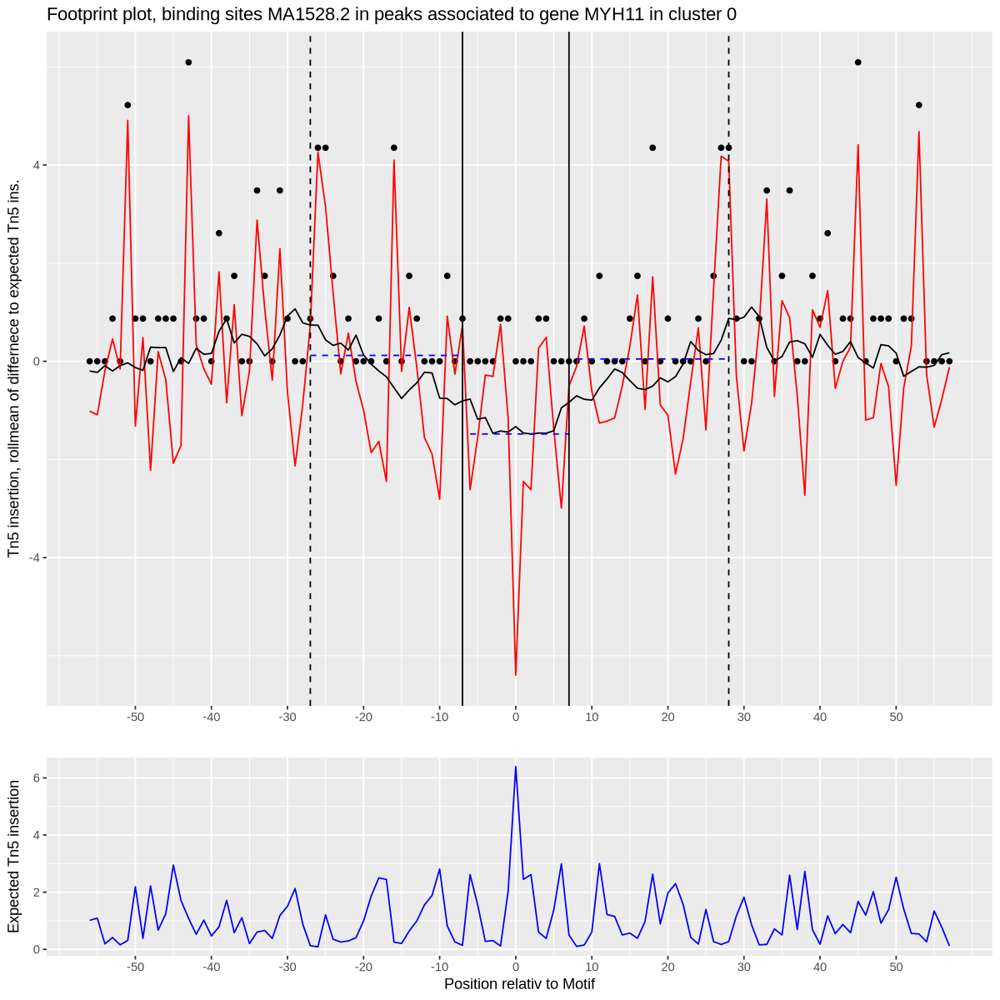

[1] "Plotting footprint for motif: MA0003.5 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:41 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15857274-15857282      + |   13.2066
  [2]    chr16 15807781-15807789      + |   13.2066
  [3]    chr16 15807660-15807668      - |   13.2066
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:41 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


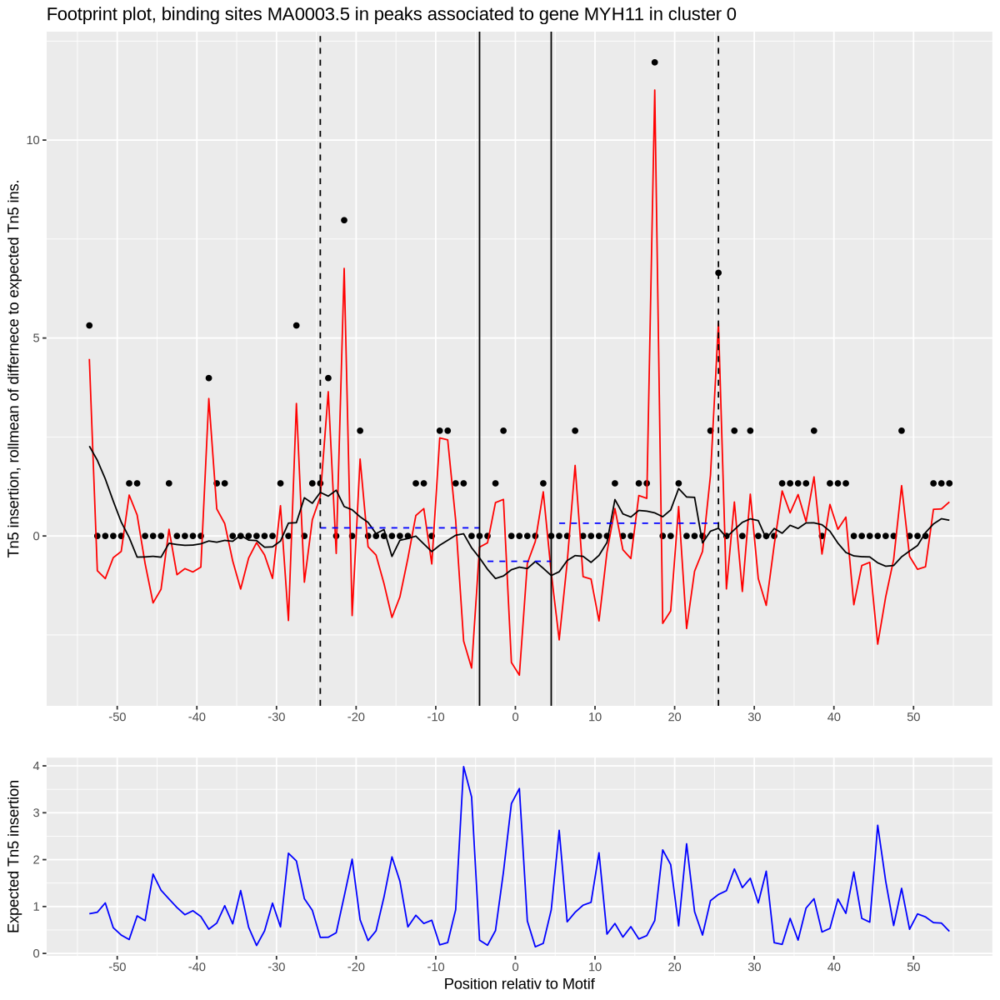

[1] "Plotting footprint for motif: MA0003.5 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:44 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15857274-15857282      + |   13.2066
  [2]    chr16 15807781-15807789      + |   13.2066
  [3]    chr16 15807660-15807668      - |   13.2066
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:44 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


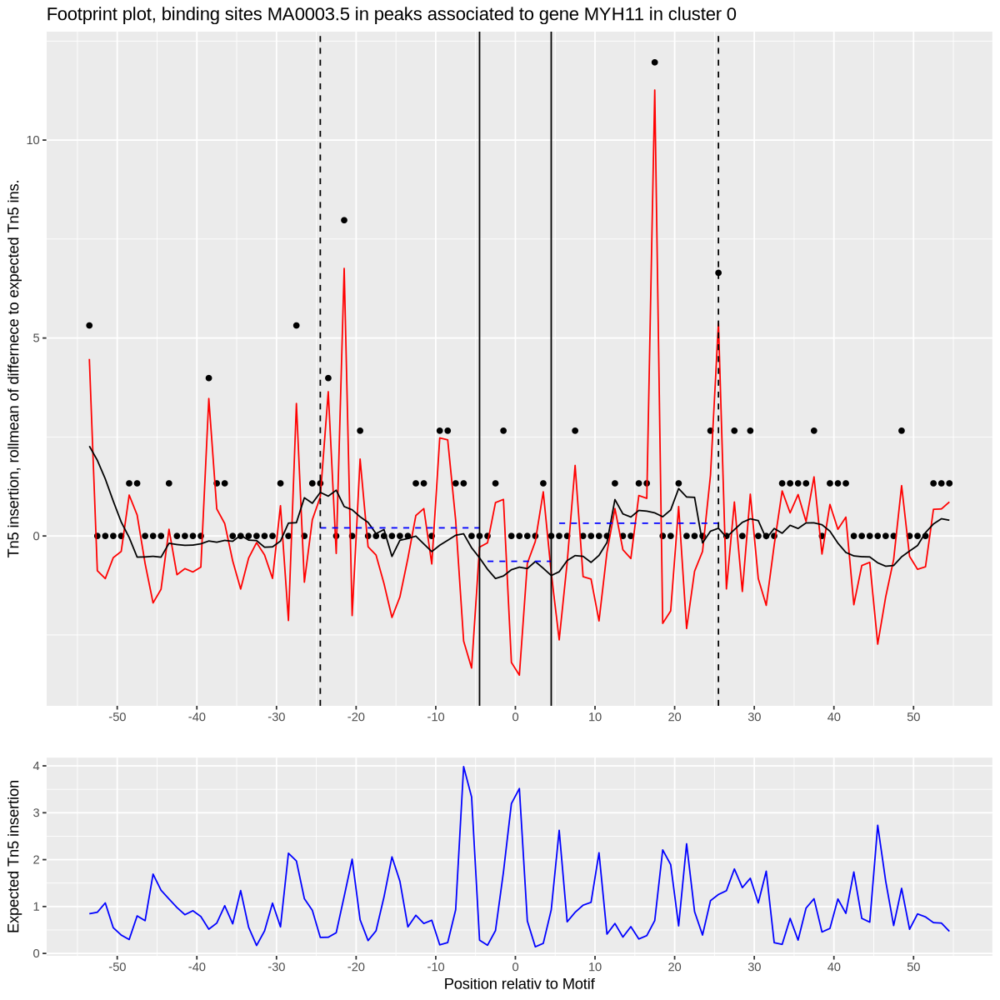

[1] "Plotting footprint for motif: MA0812.2 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:46 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15857274-15857282      + |     15.22
  [2]    chr16 15807781-15807789      + |     15.22
  [3]    chr16 15807660-15807668      - |     15.22
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:47 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


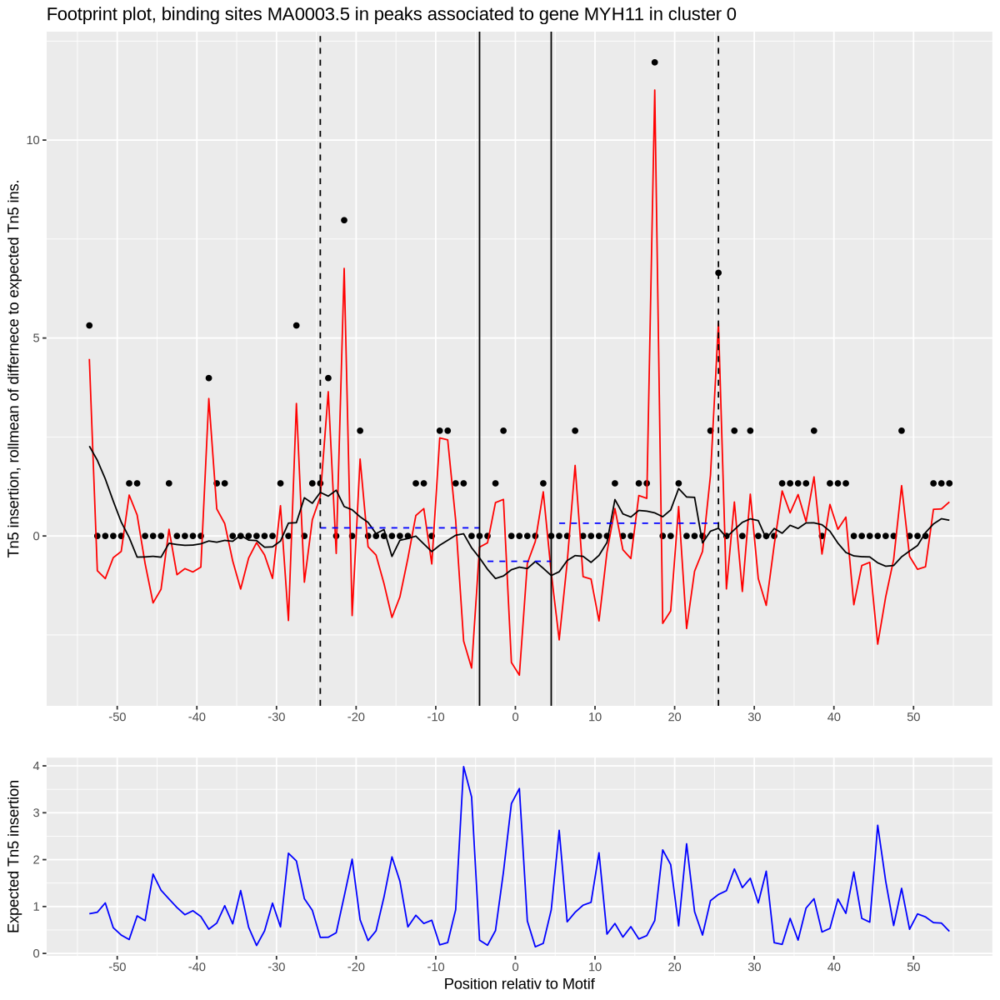

[1] "Plotting footprint for motif: MA0812.2 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:49 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15857274-15857282      + |     15.22
  [2]    chr16 15807781-15807789      + |     15.22
  [3]    chr16 15807660-15807668      - |     15.22
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:50 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


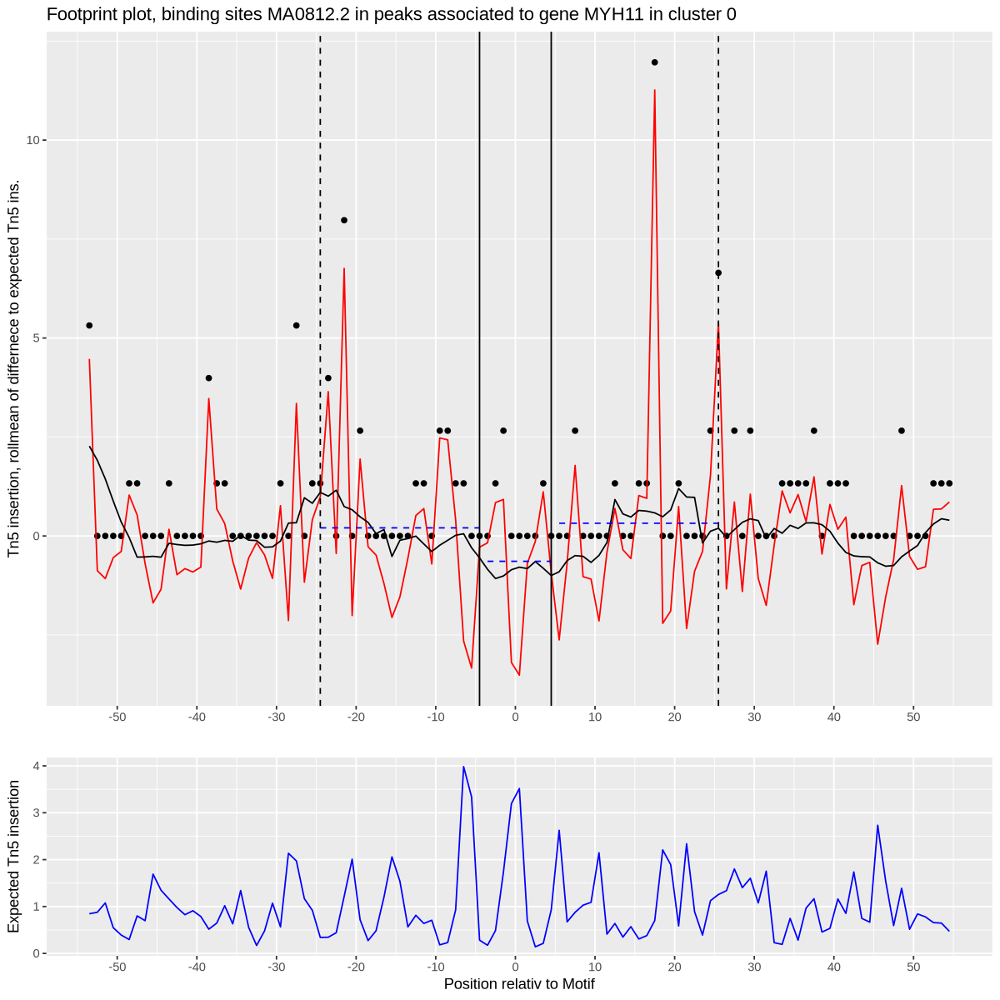

[1] "Plotting footprint for motif: MA1569.2 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:52 CEST"
GRanges object with 6 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15857274-15857282      + |   14.1511
  [2]    chr16 15857274-15857282      - |   14.0468
  [3]    chr16 15807660-15807668      + |   14.0468
  [4]    chr16 15807781-15807789      + |   14.1511
  [5]    chr16 15807660-15807668      - |   14.1511
  [6]    chr16 15807781-15807789      - |   14.0468
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:53 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


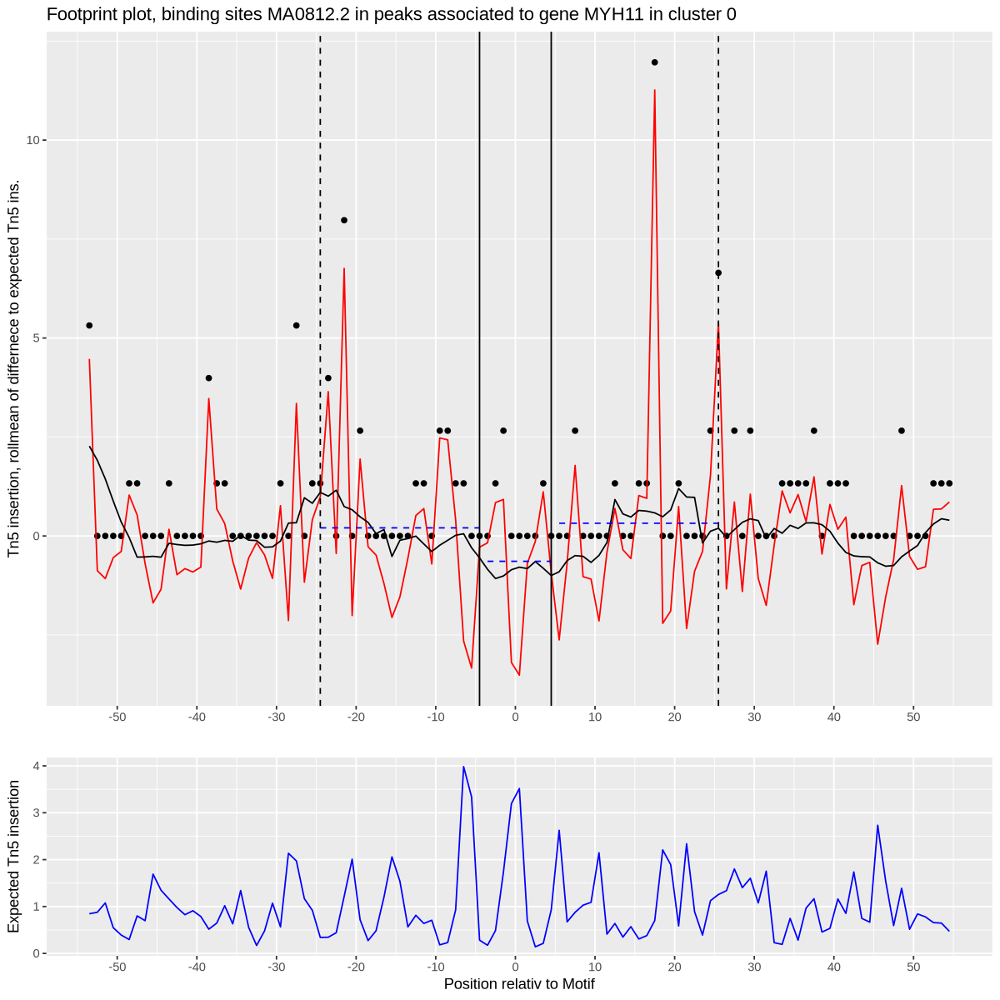

[1] "Plotting footprint for motif: MA1569.2 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:55 CEST"
GRanges object with 6 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15857274-15857282      + |   14.1511
  [2]    chr16 15857274-15857282      - |   14.0468
  [3]    chr16 15807660-15807668      + |   14.0468
  [4]    chr16 15807781-15807789      + |   14.1511
  [5]    chr16 15807660-15807668      - |   14.1511
  [6]    chr16 15807781-15807789      - |   14.0468
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:56 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


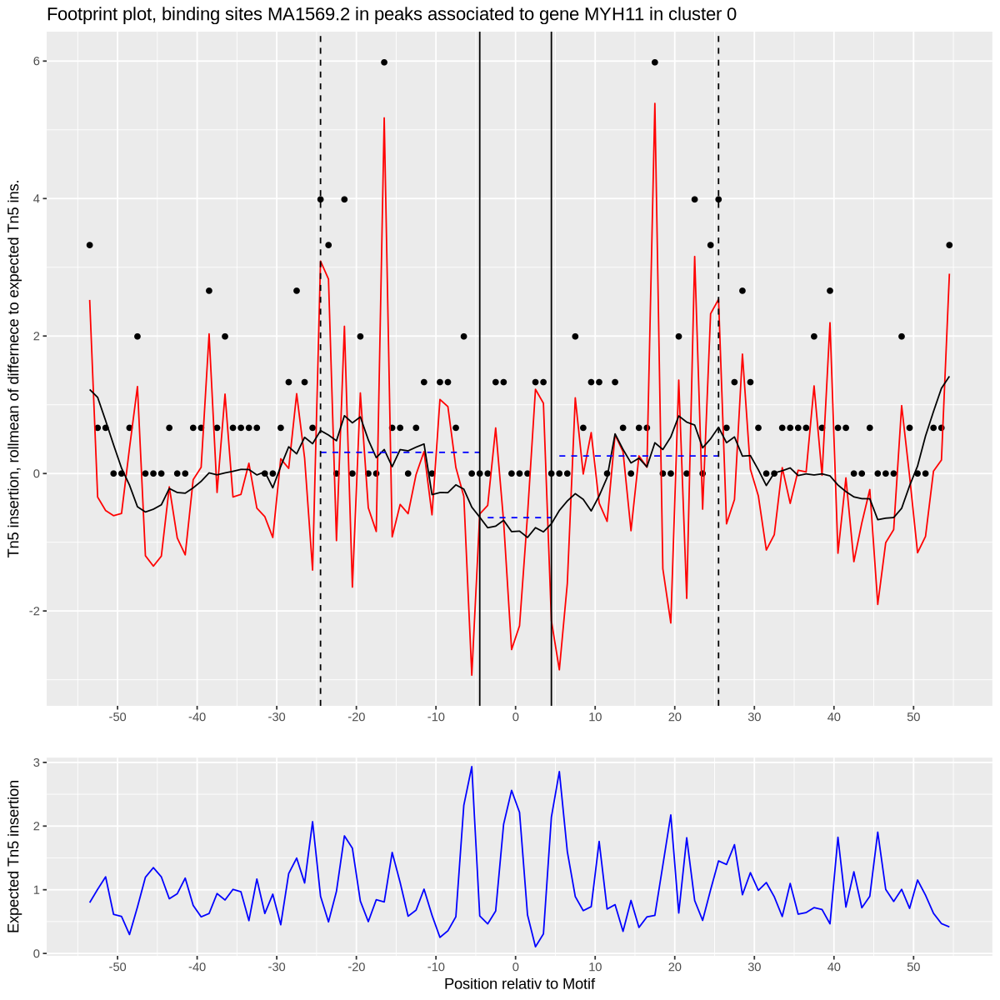

[1] "Plotting footprint for motif: MA1569.2 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:10:59 CEST"
GRanges object with 6 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15857274-15857282      + |   14.1511
  [2]    chr16 15857274-15857282      - |   14.0468
  [3]    chr16 15807660-15807668      + |   14.0468
  [4]    chr16 15807781-15807789      + |   14.1511
  [5]    chr16 15807660-15807668      - |   14.1511
  [6]    chr16 15807781-15807789      - |   14.0468
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:10:59 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


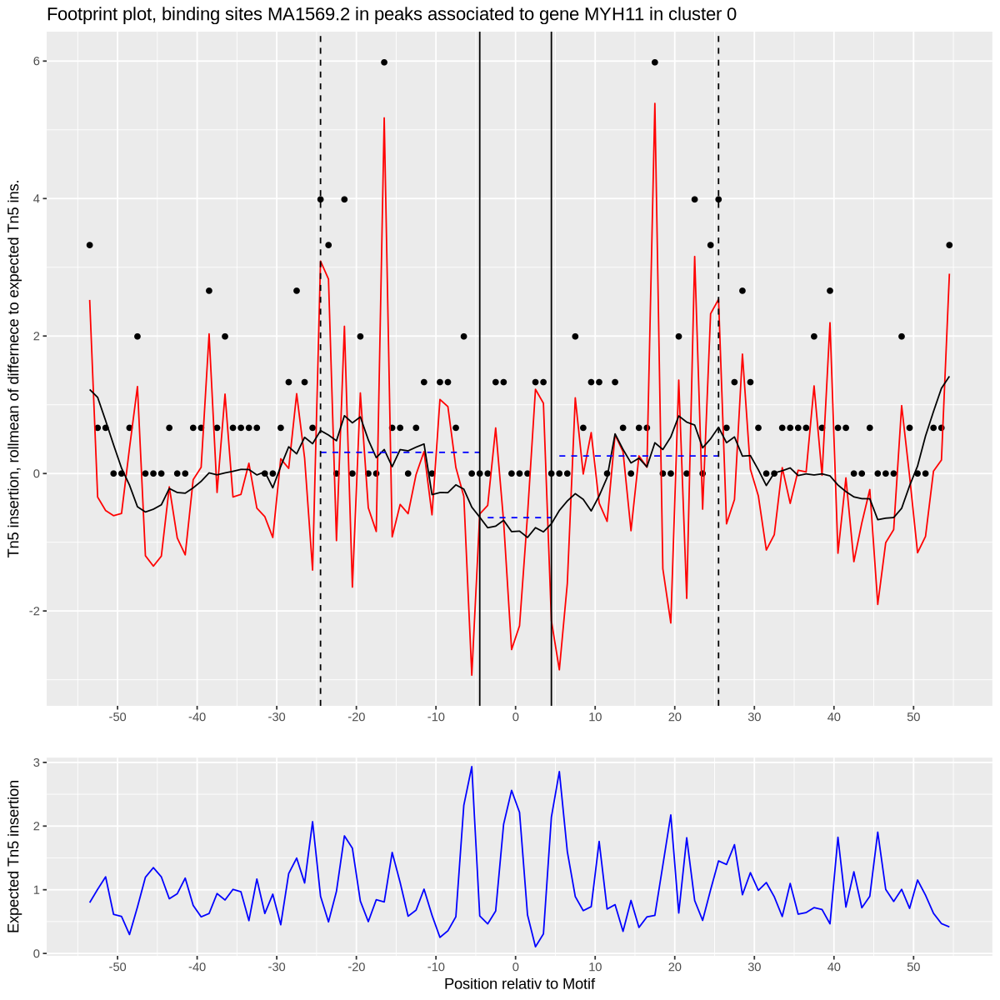

[1] "Plotting footprint for motif: MA1973.2 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:11:02 CEST"
GRanges object with 1 range and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15858251-15858264      - |   12.6826
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:11:03 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


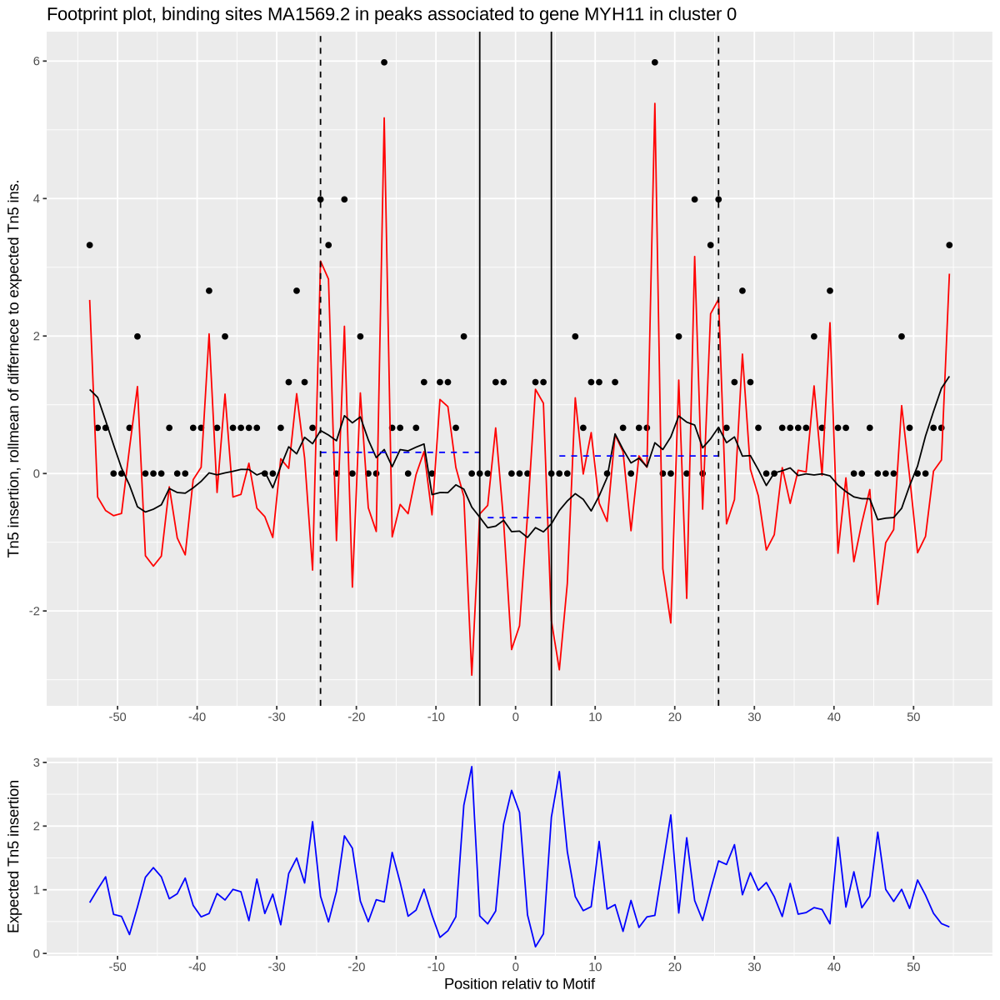

[1] "Plotting footprint for motif: MA0528.3 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:11:06 CEST"
GRanges object with 4 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15857087-15857093      + |    13.822
  [2]    chr16 15857396-15857402      - |    13.822
  [3]    chr16 15807743-15807749      - |    13.822
  [4]    chr16 15807823-15807829      - |    13.822
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:11:07 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


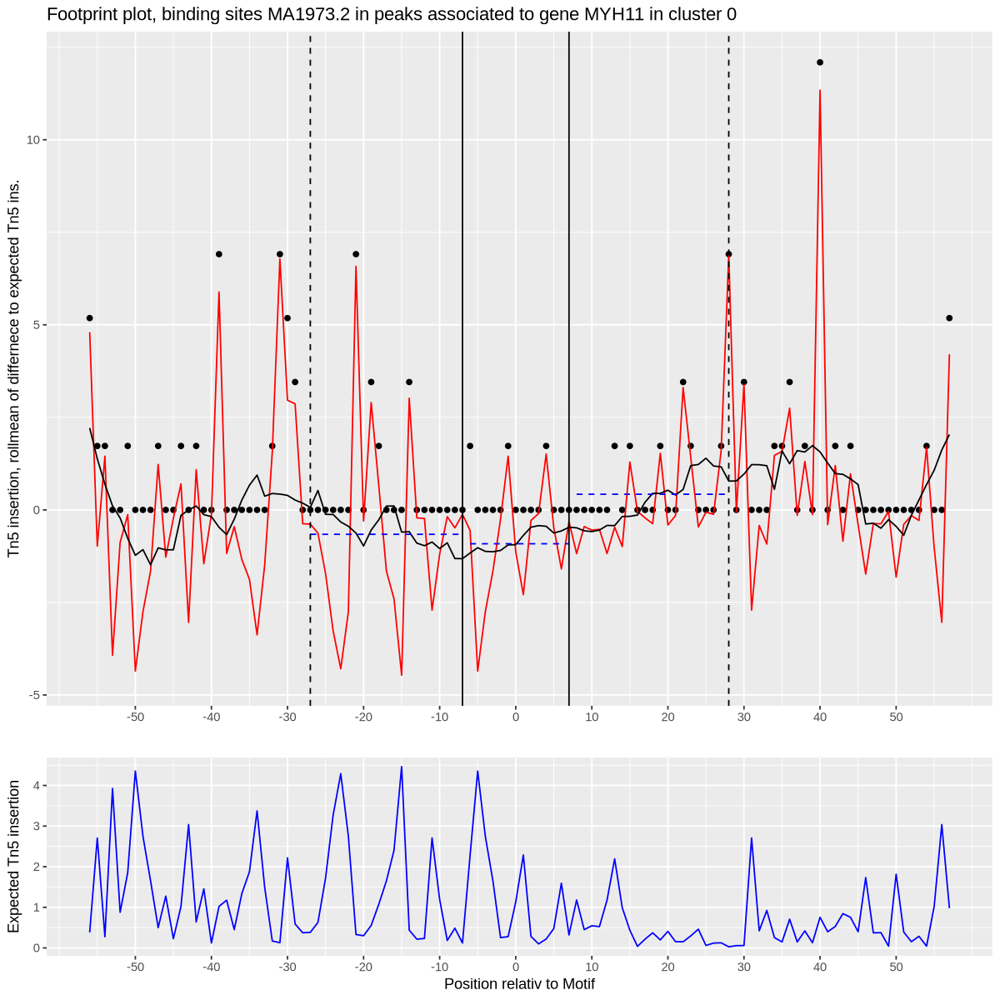

[1] "Plotting footprint for motif: MA0528.3 and gene: MYH11"


computing motifs to gene



[1] "2026-04-08 23:11:10 CEST"
GRanges object with 4 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr16 15857087-15857093      + |    13.822
  [2]    chr16 15857396-15857402      - |    13.822
  [3]    chr16 15807743-15807749      - |    13.822
  [4]    chr16 15807823-15807829      - |    13.822
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 23:11:10 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


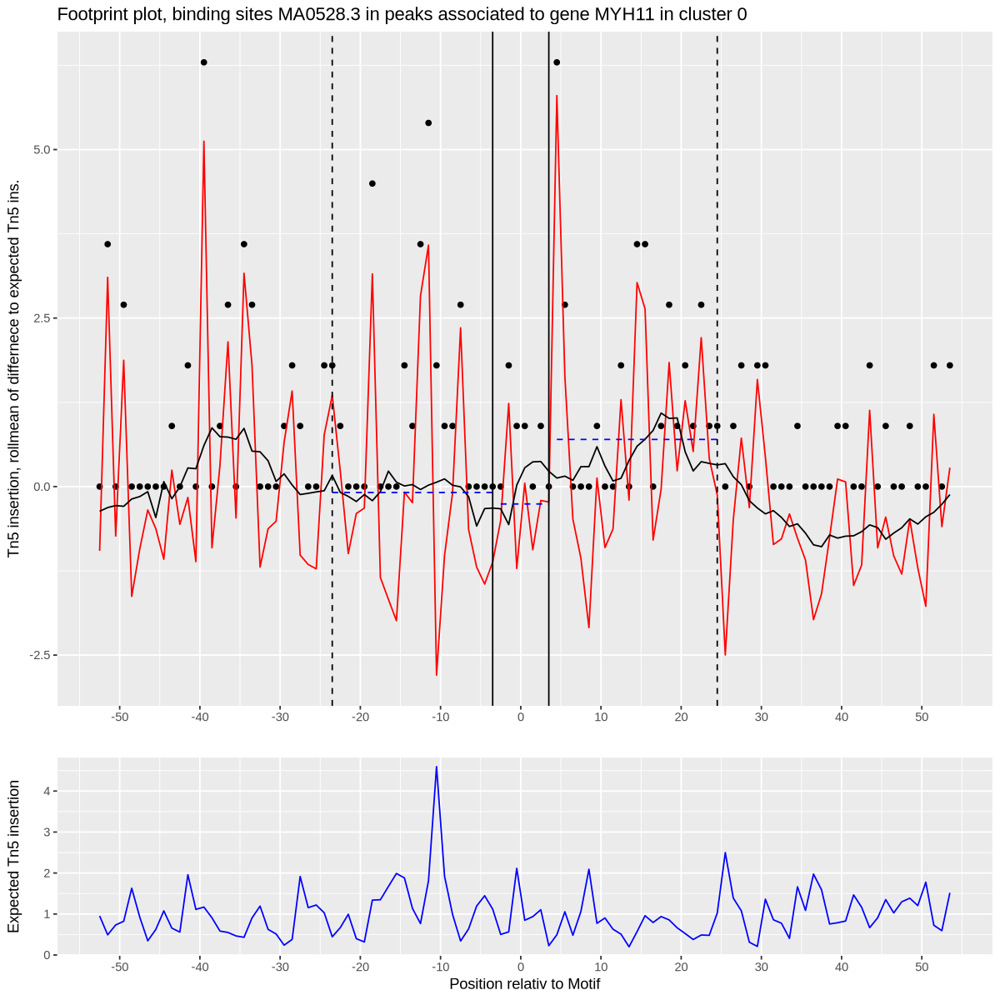

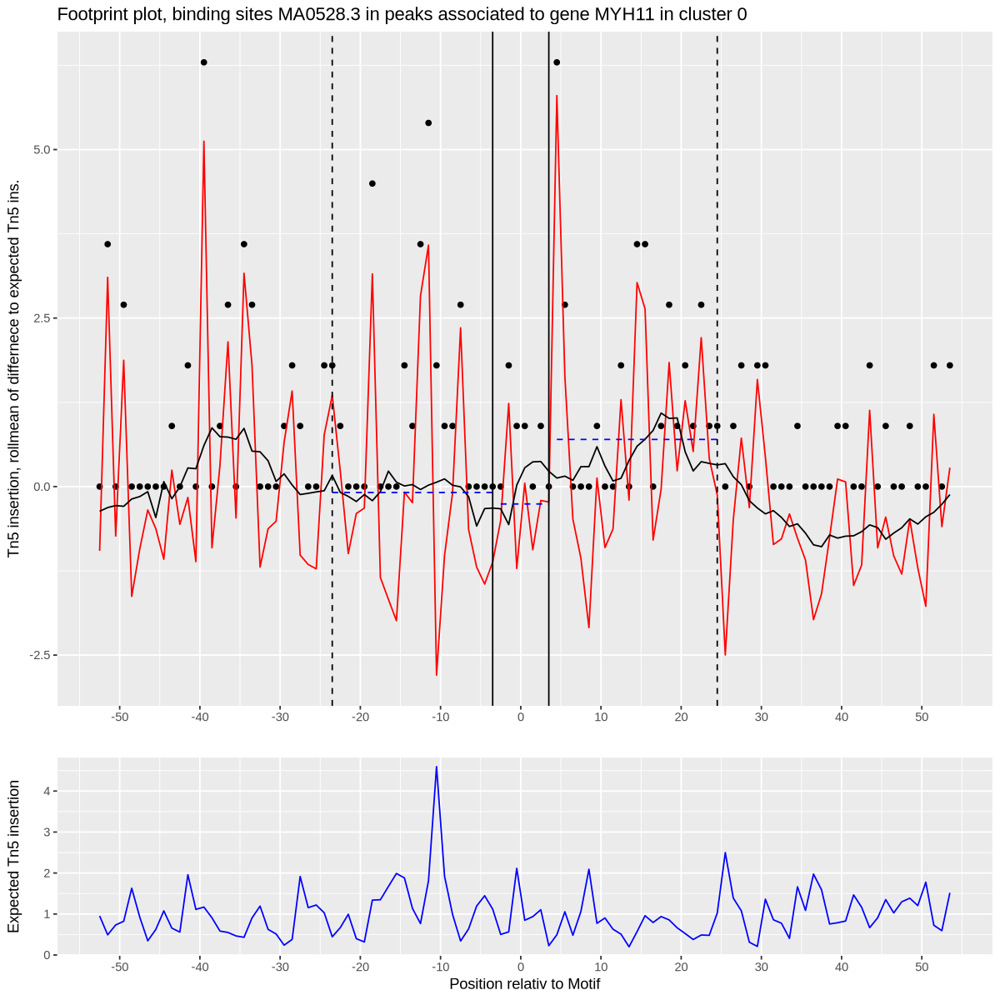

In [165]:
for (gene in c("MYLK", "KCNMA1", "MYH11")) {
    print(paste("Footprint plot for gene:", gene))
    green_motifs <- object_w_net@misc$seedNetwork$smooth_muscle_contraction_cluster_0_genes_with_peaks[[gene]][object_w_net@misc$seedNetwork$smooth_muscle_contraction_cluster_0_genes_with_peaks[[gene]]$result == "green", ]$motif


    for (motif in green_motifs) {
        print(paste("Plotting footprint for motif:", motif, "and gene:", gene))
        res <- footprint_plots_by_TF(
            object = object_w_net,
            gene = gene,
            cluster = 0,
            motif_id = motif,
            path = NULL
        )
        print(res)
    }
}
# for (i in seq_len(nrow(green_edges))) {
#     e <- green_edges[i, ]
#     TF <- e$from
#     gene <- e$to

#     res <- footprint_plots_by_TF(
#         object = object_w_net,
#         gene = gene,
#         cluster = 0,
#         TF = TF,
#         path = NULL
#     )

#     print(res)
# }


[1] "2026-04-03 14:46:19 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr14 37595905-37595910      + |   10.8605
  [2]    chr14 37595686-37595691      - |   10.8605
  [3]    chr14 37595788-37595793      - |   10.8605
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-03 14:46:19 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"
[1] "2026-04-03 14:46:20 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr14 37595905-37595910      + |    9.6718
  [2]    chr14 37595686-37595691      - |    9.6718
  [3]    chr14 37595788-37595793      - |    9.6718
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-03 14:46:20 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


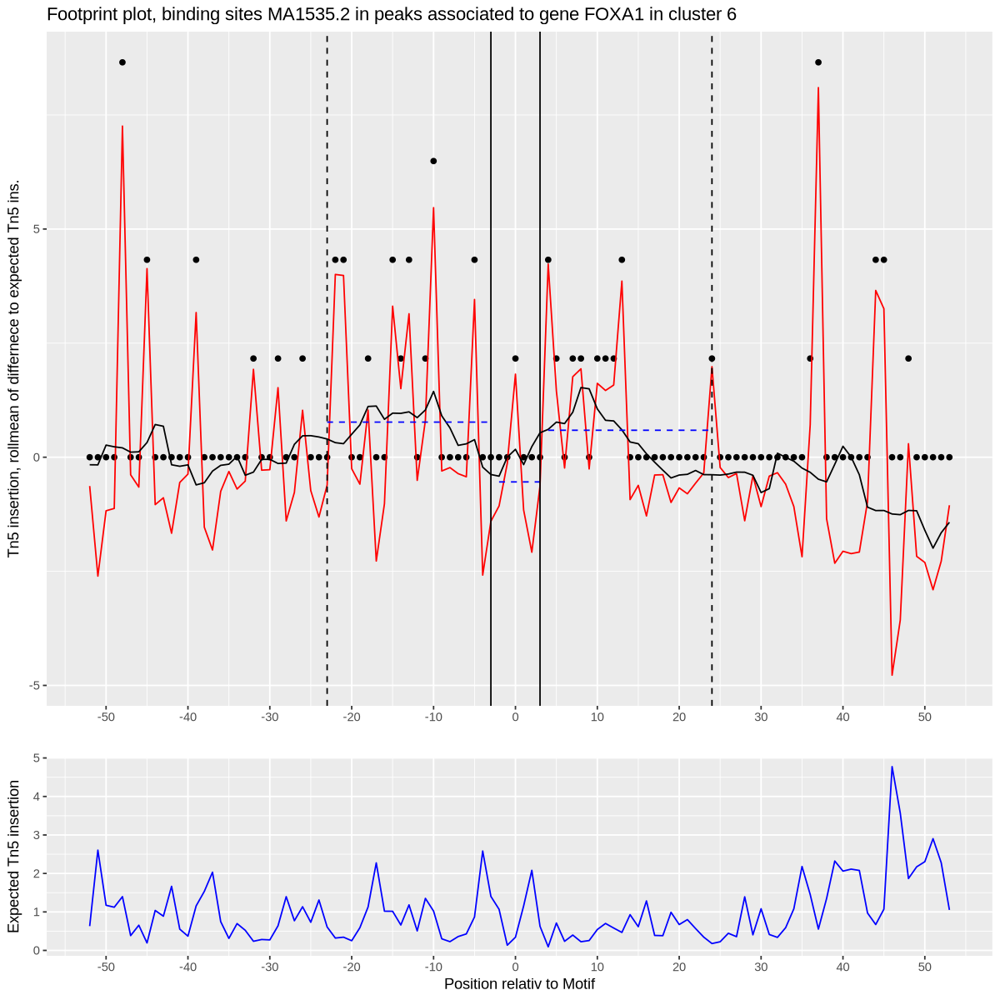

[1] "2026-04-03 14:46:21 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr14 37594792-37594802      + |   13.7948
  [2]    chr14 37595635-37595645      - |   13.7948
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-03 14:46:21 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


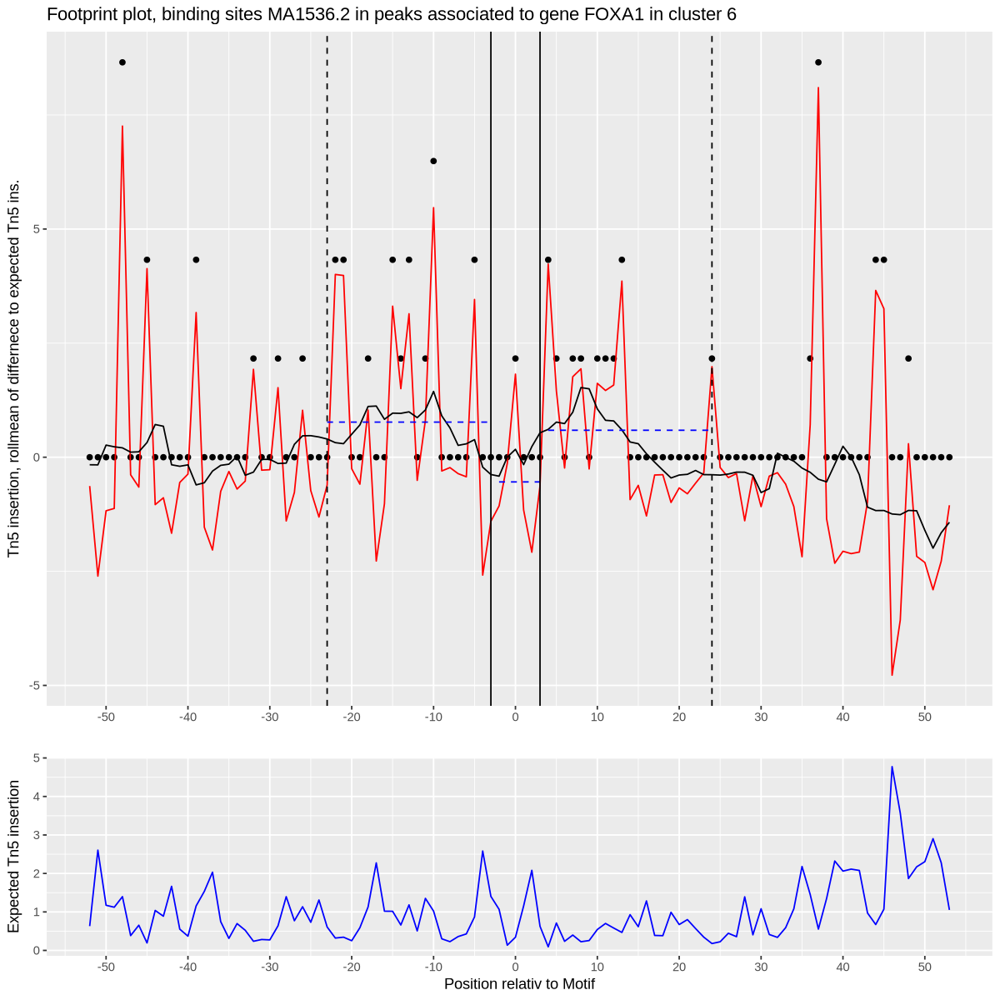

[1] "2026-04-03 14:46:21 CEST"
GRanges object with 4 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr14 37595142-37595155      + |   19.3589
  [2]    chr14 37595145-37595158      + |   21.7902
  [3]    chr14 37595148-37595161      + |   17.7851
  [4]    chr14 37595188-37595201      + |   13.5588
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-03 14:46:22 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


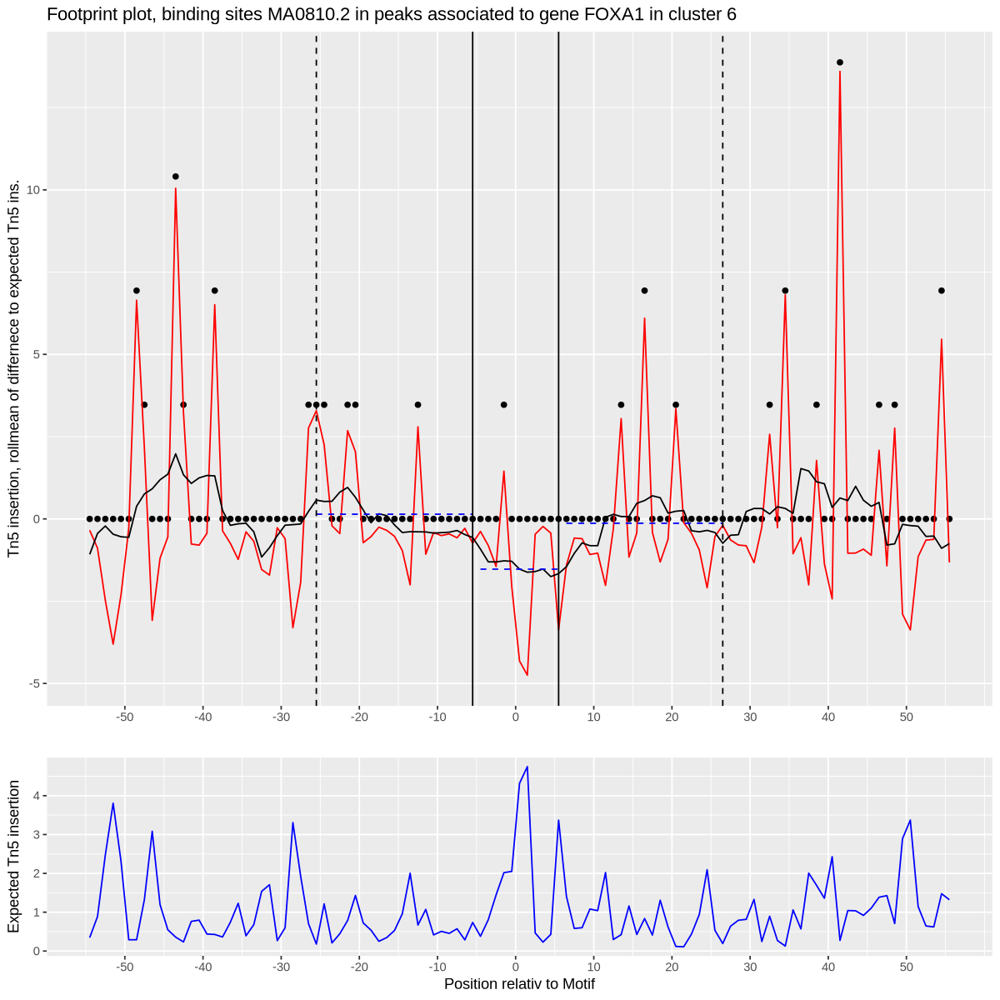

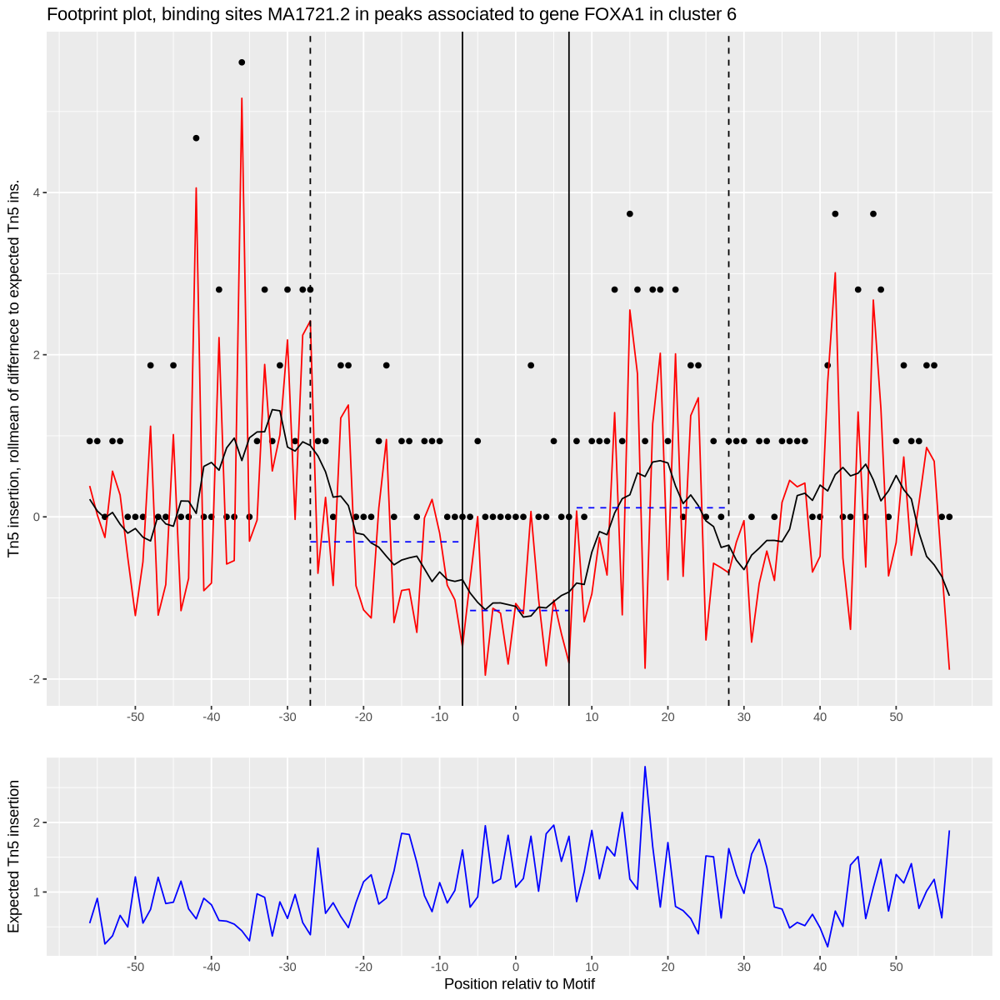

In [241]:

for(m in green_motifs){
    print(footprint_plots_by_TF(object=object_w_net, gene='FOXA1', cluster=6, motif_id=m, path=NULL))
}


# read obj again, look at denied motifs

In [32]:
# use output of global motif analysis
res_motifs_mapped <- readRDS("/nfs/home/students/m.back/multiome_scripts/res_motifs_mapped.rds")

In [33]:

footprint_plots_by_TF(object=res_motifs_mapped, gene='FOXA1', cluster=6, TF="VENTX", path=NULL)

TF provided, plotting all motifs for TF



[1] "NO MOTIFS FOR VENTX FOUND IN PEAKS LINKED TO FOXA1"

In [35]:

footprint_plots_by_TF(object=res_motifs_mapped, gene='FOXA1', cluster=6, TF="FOXK1", path=NULL)

TF provided, plotting all motifs for TF



[1] "NO MOTIFS FOR FOXK1 FOUND IN PEAKS LINKED TO FOXA1"

TF provided, plotting all motifs for TF



[1] "2026-04-07 12:01:43 CEST"
GRanges object with 1 range and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr14 37595494-37595504      - |   8.78424
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-07 12:01:44 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


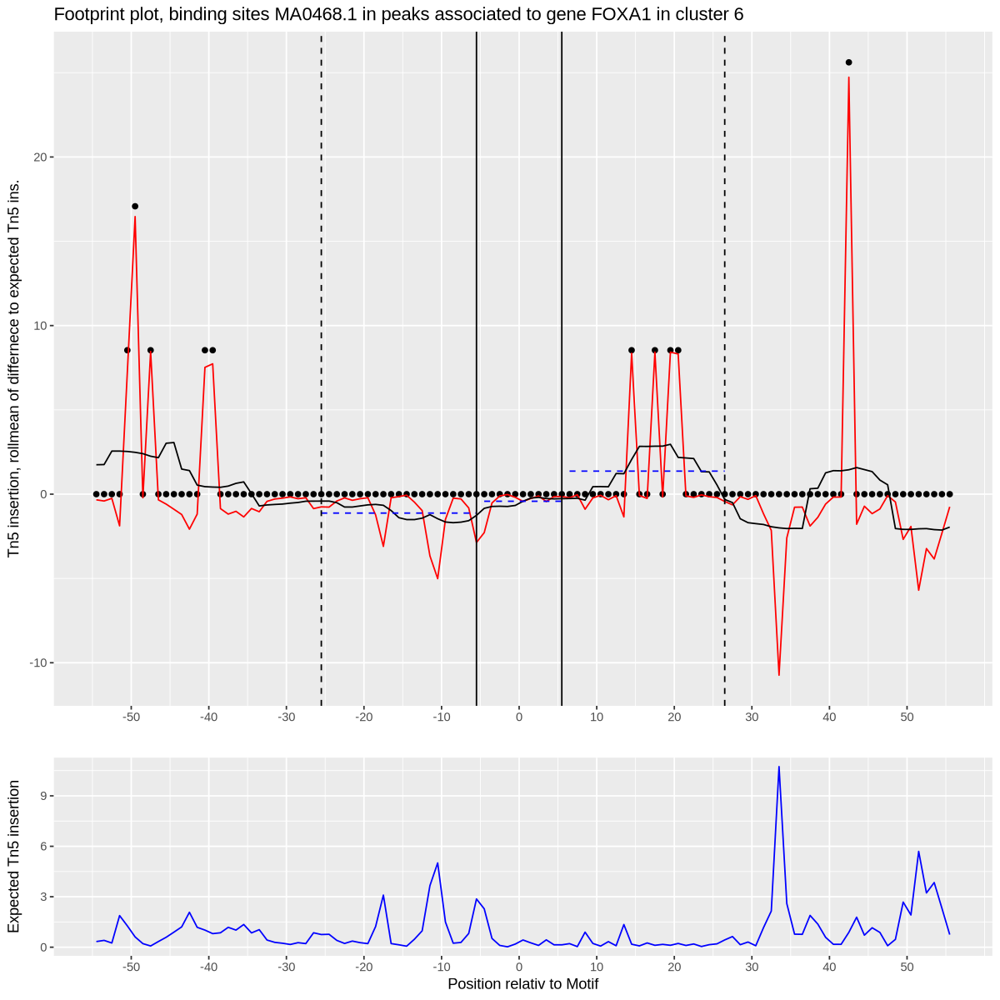

In [53]:

footprint_plots_by_TF(object=res_motifs_mapped, gene='FOXA1', cluster=6, TF="DUX4", path=NULL)

In [40]:
res_motifs_mapped@misc$seedNetwork$FOXA1_cluster6_new

NULL

In [61]:
colnames(object_w_net@misc$seedNetwork$FOXA1_cluster6_new$FOXA1[object_w_net@misc$seedNetwork$FOXA1_cluster6_new$FOXA1$result=="green",])

[1] "gene"                      "cluster"                  
 [3] "proximal.motif_count"      "proximal.background_count"
 [5] "log2FC.proximal"           "t_stat.proximal"          
 [7] "p_value.proximal"          "p_adjust.proximal"        
 [9] "distal.motif_count"        "distal.background_count"  
[11] "log2FC.distal"             "t_stat.distal"            
[13] "p_value.distal"            "p_adjust.distal"          
[15] "motif"                     "promoter.motif_count"     
[17] "footprint_score"           "bg_size"                  
[19] "bg_footprint_mean"         "footprint.t_stat"         
[21] "footprint.p_value"         "footprint.p_value_adj"    
[23] "sd.flanks"                 "bg_sd_mean"               
[25] "promoter.or.enriched"      "TF"                       
[27] "result"                    "priorTF"

In [63]:
object_w_net@misc$seedNetwork$FOXA1_cluster6_new$FOXA1[object_w_net@misc$seedNetwork$FOXA1_cluster6_new$FOXA1$result=="green",]

,gene,cluster,proximal.motif_count,proximal.background_count,log2FC.proximal,t_stat.proximal,p_value.proximal,p_adjust.proximal,distal.motif_count,distal.background_count,⋯,bg_footprint_mean,footprint.t_stat,footprint.p_value,footprint.p_value_adj,sd.flanks,bg_sd_mean,promoter.or.enriched,TF,result,priorTF
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<chr>,<chr>,<lgl>
FOXA1.DUX4,FOXA1,6,1,0.12,3.1,-16,1.5e-21,1.1e-18,0,0.08,⋯,-0.0005796,4.578,6.834e-06,1.3e-03,2.877,4.826,TRUE,DUX4,green,FALSE
FOXA1.JDP2,FOXA1,6,2,0.2,3.3,-22,1.4e-27,1e-24,0,0.08,⋯,0.0459600,4.844,2.350e-06,4.5e-04,2.449,4.306,TRUE,JDP2,green,FALSE
FOXA1.PHOX2A,FOXA1,6,1,0.1,3.3,-21,1.9e-26,1.4e-23,0,0,⋯,0.1652000,5.250,4.354e-07,8.4e-05,2.877,4.027,TRUE,PHOX2A,green,FALSE
FOXA1.PROP1,FOXA1,6,1,0.18,2.5,-13,4e-18,2.9e-15,0,0.02,⋯,-0.2266000,5.150,6.651e-07,1.3e-04,2.877,4.692,TRUE,PROP1,green,FALSE
FOXA1.ZNF460,FOXA1,6,2,3.4,-0.77,4.6,1,1,0,1.5,⋯,-0.3689000,8.437,1.377e-13,2.7e-11,3.666,3.795,TRUE,ZNF460,green,FALSE
FOXA1.ZNF707,FOXA1,6,1,0.94,0.089,-0.39,0.35,1,0,0.64,⋯,0.3910000,6.197,6.638e-09,1.3e-06,4.452,3.843,TRUE,ZNF707,green,FALSE
FOXA1.ZSCAN16,FOXA1,6,1,0.16,2.6,-16,2e-21,1.4e-18,0,0.1,⋯,0.4431000,12.260,7.175e-22,1.4e-19,3.950,3.471,TRUE,ZSCAN16,green,FALSE
FOXA1.ZFP14,FOXA1,6,2,2.1,-0.07,0.64,0.74,1,0,0.86,⋯,0.2865000,7.276,4.107e-11,7.9e-09,3.716,3.650,TRUE,ZFP14,green,FALSE
FOXA1.ATF3,FOXA1,6,2,0.28,2.8,-17,7.3e-23,5.3e-20,0,0.2,⋯,0.6335000,5.068,9.355e-07,1.8e-04,2.153,3.586,TRUE,ATF3,green,FALSE


In [70]:
object_w_net@misc$seedNetwork$FOXA1_cluster6_new$FOXA1[object_w_net@misc$seedNetwork$FOXA1_cluster6_new$FOXA1$result=="red",][c('proximal.motif_count','proximal.background_count','log2FC.proximal','t_stat.proximal','p_value.proximal','p_adjust.proximal','distal.motif_count','distal.background_count','log2FC.distal','t_stat.distal','p_value.distal','p_adjust.distal','motif','promoter.motif_count','footprint_score','bg_size','bg_footprint_mean','footprint.t_stat','footprint.p_value','footprint.p_value_adj','sd.flanks','bg_sd_mean','promoter.or.enriched','TF','result','priorTF')]

,proximal.motif_count,proximal.background_count,log2FC.proximal,t_stat.proximal,p_value.proximal,p_adjust.proximal,distal.motif_count,distal.background_count,log2FC.distal,t_stat.distal,⋯,bg_footprint_mean,footprint.t_stat,footprint.p_value,footprint.p_value_adj,sd.flanks,bg_sd_mean,promoter.or.enriched,TF,result,priorTF
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<chr>,<chr>,<lgl>
FOXA1.INSM1,1,0.94,0.089,-0.41,0.34,1,0,0.72,-Inf,5.4,⋯,-0.3880000,0.6853,0.247400,1.00,2.342,4.641,TRUE,INSM1,red,FALSE
FOXA1.BACH1,1,0.26,1.9,-9.9,1.3e-13,9.4e-11,0,0.04,-Inf,1.4,⋯,-0.2159000,2.4560,0.007899,1.00,3.926,5.584,TRUE,BACH1,red,FALSE
FOXA1.BARHL1,1,0.34,1.6,-6.5,1.9e-08,1.4e-05,0,0.04,-Inf,1.4,⋯,-0.6592000,2.0020,0.024000,1.00,3.690,4.510,TRUE,BARHL1,red,FALSE
FOXA1.BARX1,1,0.38,1.4,-6.3,4.1e-08,3e-05,0,0.1,-Inf,2.3,⋯,0.1934000,2.2820,0.012320,1.00,3.239,4.428,TRUE,BARX1,red,FALSE
FOXA1.BATF.199,2,0.4,2.3,-17,2.3e-22,1.7e-19,0,0.16,-Inf,2.7,⋯,-0.2196000,0.7115,0.239200,1.00,2.736,4.060,TRUE,BATF,red,FALSE
FOXA1.BATF.200,2,0.4,2.3,-17,2.3e-22,1.7e-19,0,0.16,-Inf,2.7,⋯,-0.2654000,0.4343,0.332500,1.00,2.736,4.496,TRUE,BATF,red,FALSE
FOXA1.JUN.200,2,0.4,2.3,-17,2.3e-22,1.7e-19,0,0.16,-Inf,2.7,⋯,-0.2654000,0.4343,0.332500,1.00,2.736,4.496,TRUE,JUN,red,FALSE
FOXA1.BATF3,2,0.4,2.3,-17,2.3e-22,1.7e-19,0,0.16,-Inf,2.7,⋯,-0.1467000,1.4690,0.072500,1.00,2.736,4.212,TRUE,BATF3,red,FALSE
FOXA1.BHLHE22.1,2,4.7,-1.2,7,1,1,2,2.8,-0.49,2.3,⋯,-0.2422000,1.7370,0.042770,1.00,2.470,3.681,TRUE,BHLHE22,red,FALSE


### tables to visualize:

In [73]:
str(object_w_net@misc, max.level = 1)

List of 12
 $ markers.annotated        :'data.frame':	4000 obs. of  8 variables:
 $ peak_stats               :'data.frame':	57 obs. of  43 variables:
 $ peak_stats.filtered      :'data.frame':	22 obs. of  51 variables:
 $ motifs.inProximalPeaks   :List of 1
 $ motifs.inDistalPeaks     :List of 1
 $ motif_enrichment         :'data.frame':	720 obs. of  16 variables:
 $ filtered.motif_enrichment:'data.frame':	193 obs. of  16 variables:
 $ motif_stats              :'data.frame':	193 obs. of  24 variables:
 $ motif2TF                 :List of 720
 $ TF2motif                 :List of 668
 $ seedNetwork              :List of 1
 $ context_subNetwork       :List of 1


In [75]:
head(object_w_net@misc$peak_stats.filtered)

,cluster,peak,gene,annotation,regulatorType,signac.scores,signac.zscores,signac.pvalues,t-stat_highly.acc,p.value-t.test_highly.acc,⋯,promotersLinkedToSeed,distalPeaksLinkedToSeed,acc_cells_cluster,delta_expr_given_acc.same_peak_bg,delta_expr_given_acc.other_peaks.same_cluster,delta_expr_given_acc.other_peaks.all,pass_cluster_specific,pass_global,pass_any,pass_type
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<chr>,<chr>,<table[1d]>,<dbl>,<dbl>,<dbl>,<lgl[1d]>,<lgl>,<lgl[1d]>,<chr[1d]>
1,6,chr12-75208970-75209804,KCNC2,marker.pos.6,proximal,0.06349911,2.886314,1.948918e-03,4.367902,1.002159e-05,⋯,1,0,32,0.7095757,NA,NA,TRUE,FALSE,TRUE,cluster_specific
2,6,chr6-135180380-135183763,MYB,marker.pos.6,proximal,0.06672512,2.686259,3.612850e-03,4.640813,3.058988e-06,⋯,1,0,95,0.5045884,NA,NA,TRUE,FALSE,TRUE,cluster_specific
9,6,chr14-37594269-37596269,TTC6,marker.pos.6,proximal,0.10269372,3.892794,4.954812e-05,7.560189,6.626128e-13,⋯,1,2,96,0.8915914,-0.006410256,-0.039972654,TRUE,FALSE,TRUE,cluster_specific
12,6,chr14-37622140-37622969,TTC6,marker.pos.6,distal,0.05633351,2.036325,2.085885e-02,3.205396,7.834133e-04,⋯,1,2,21,0.9679487,0.118589744,0.025288562,TRUE,FALSE,TRUE,cluster_specific
16,6,chr6-24402481-24403631,DCDC2,marker.pos.6,distal,0.06696882,1.654190,4.904442e-02,3.058728,1.257088e-03,⋯,1,1,51,0.4038491,0.101419878,-0.002903066,TRUE,FALSE,TRUE,cluster_specific
18,6,chr2-149037786-149039241,LYPD6B,marker.pos.6,proximal,0.05826890,1.920044,2.742616e-02,5.581221,3.758744e-08,⋯,1,0,63,0.4046078,NA,NA,TRUE,FALSE,TRUE,cluster_specific


In [78]:
head(object_w_net@misc$peak_stats)

,cluster,peak,gene,annotation,regulatorType,signac.scores,signac.zscores,signac.pvalues,t-stat_highly.acc,p.value-t.test_highly.acc,⋯,expr_not_0.bg_other_peaks.all,acc_not_0.bg_other_peaks.all,expr_not_0.given_acc.bg_other_peaks.all,expr_and_acc_not_0.bg_other_peaks.all,FC.expr_given_acc.bg_other_peaks.all,n.bg_other_peaks.all,high_cor_distal,high_cor_distal_zScore,promotersLinkedToSeed,distalPeaksLinkedToSeed
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<chr>,<chr>
1,6,chr12-75208970-75209804,KCNC2,marker.pos.6,proximal,0.06349911,2.886314,1.948918e-03,4.367902,1.002159e-05,⋯,NA,NA,NA,NA,NA,0,NA,NA,1,0
2,6,chr6-135180380-135183763,MYB,marker.pos.6,proximal,0.06672512,2.686259,3.612850e-03,4.640813,3.058988e-06,⋯,NA,NA,NA,NA,NA,0,NA,NA,1,0
3,6,chr10-37274923-37275867,ANKRD30A,marker.pos.6,distal,0.09850731,3.333406,4.289482e-04,2.704581,3.712423e-03,⋯,NA,NA,NA,NA,NA,0,NA,NA,0,1
4,6,chr14-37583386-37585333,TTC6,marker.pos.6,distal,0.05600614,2.285779,1.113360e-02,8.307455,7.071513e-15,⋯,0.04521073,0.1216475,0.1251389,0.01331418,2.767903,2,NA,NA,1,2
9,6,chr14-37594269-37596269,TTC6,marker.pos.6,proximal,0.10269372,3.892794,4.954812e-05,7.560189,6.626128e-13,⋯,0.04521073,0.0710728,0.1433578,0.01005747,3.170881,2,NA,NA,1,2
12,6,chr14-37622140-37622969,TTC6,marker.pos.6,distal,0.05633351,2.036325,2.085885e-02,3.205396,7.834133e-04,⋯,0.04521073,0.1588123,0.1216041,0.01839080,2.689718,2,NA,NA,1,2


In [77]:
head(object_w_net@misc$motif_stats)

,gene,cluster,proximal.motif_count,proximal.background_count,log2FC.proximal,t_stat.proximal,p_value.proximal,p_adjust.proximal,distal.motif_count,distal.background_count,⋯,motif,promoter.motif_count,footprint_score,bg_size,bg_footprint_mean,footprint.t_stat,footprint.p_value,footprint.p_value_adj,sd.flanks,bg_sd_mean
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
4,FOXA1,6,1,0.44,1.2,-5.9,1.9e-07,0.00014,0,0.12,⋯,MA0101.1,3,0.1251,100,-0.0803600,-1.0970,8.623e-01,1.0000,2.235,4.453
5,FOXA1,6,1,0.46,1.1,-5.6,4.1e-07,3e-04,0,0.14,⋯,MA0107.1,1,0.1251,100,0.0456700,-0.3326,6.299e-01,1.0000,2.235,4.561
9,FOXA1,6,3,4.6,-0.62,2.5,0.99,1,0,1.4,⋯,MA0149.1,0,0.4703,100,0.0865800,-3.1690,9.990e-01,1.0000,1.605,3.877
10,FOXA1,6,1,0.94,0.089,-0.41,0.34,1,0,0.72,⋯,MA0155.1,1,-0.5262,100,-0.3880000,0.6853,2.474e-01,1.0000,2.342,4.641
12,FOXA1,6,1,1.4,-0.49,2.1,0.98,1,0,0.72,⋯,MA0163.1,0,3.0020,100,0.0410700,-16.4400,1.000e+00,1.0000,2.997,4.011
13,FOXA1,6,1,0.12,3.1,-16,1.5e-21,1.1e-18,0,0.08,⋯,MA0468.1,5,-0.7952,100,-0.0005796,4.5780,6.834e-06,0.0013,2.877,4.826


In [79]:
head(object_w_net@misc$filtered.motif_enrichment)

,gene,cluster,proximal.motif_count,proximal.background_count,log2FC.proximal,t_stat.proximal,p_value.proximal,p_adjust.proximal,distal.motif_count,distal.background_count,log2FC.distal,t_stat.distal,p_value.distal,p_adjust.distal,motif,promoter.motif_count
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>
4,FOXA1,6,1,0.44,1.2,-5.9,1.9e-07,0.00014,0,0.12,-Inf,2.6,0.99,1,MA0101.1,3
5,FOXA1,6,1,0.46,1.1,-5.6,4.1e-07,3e-04,0,0.14,-Inf,2.4,0.99,1,MA0107.1,1
9,FOXA1,6,3,4.6,-0.62,2.5,0.99,1,0,1.4,-Inf,5,1,1,MA0149.1,0
10,FOXA1,6,1,0.94,0.089,-0.41,0.34,1,0,0.72,-Inf,5.4,1,1,MA0155.1,1
12,FOXA1,6,1,1.4,-0.49,2.1,0.98,1,0,0.72,-Inf,6.7,1,1,MA0163.1,0
13,FOXA1,6,1,0.12,3.1,-16,1.5e-21,1.1e-18,0,0.08,-Inf,2.1,0.98,1,MA0468.1,5


In [81]:

head(object_w_net@misc$seedNetwork$FOXA1_cluster6_new$FOXA1
)

,gene,cluster,proximal.motif_count,proximal.background_count,log2FC.proximal,t_stat.proximal,p_value.proximal,p_adjust.proximal,distal.motif_count,distal.background_count,⋯,bg_footprint_mean,footprint.t_stat,footprint.p_value,footprint.p_value_adj,sd.flanks,bg_sd_mean,promoter.or.enriched,TF,result,priorTF
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<chr>,<chr>,<lgl>
FOXA1.VENTX,FOXA1,6,0,0.04,-Inf,1.4,0.92,1,0,0,⋯,NA,NA,NA,1.00000,NaN,NA,FALSE,VENTX,blue,TRUE
FOXA1.FOXK1,FOXA1,6,0,0.14,-Inf,2.8,1,1,0,0.02,⋯,NA,NA,NA,1.00000,NaN,NA,FALSE,FOXK1,blue,TRUE
FOXA1.TCF7,FOXA1,6,0,0.16,-Inf,2.2,0.98,1,0,0.08,⋯,NA,NA,NA,1.00000,NaN,NA,FALSE,TCF7,blue,TRUE
FOXA1.INSM1,FOXA1,6,1,0.94,0.089,-0.41,0.34,1,0,0.72,⋯,-0.3880000,0.6853,2.474e-01,1.00000,2.342,4.641,TRUE,INSM1,red,FALSE
FOXA1.DUX4,FOXA1,6,1,0.12,3.1,-16,1.5e-21,1.1e-18,0,0.08,⋯,-0.0005796,4.5780,6.834e-06,0.00130,2.877,4.826,TRUE,DUX4,green,FALSE
FOXA1.JDP2,FOXA1,6,2,0.2,3.3,-22,1.4e-27,1e-24,0,0.08,⋯,0.0459600,4.8440,2.350e-06,0.00045,2.449,4.306,TRUE,JDP2,green,FALSE


In [2]:
object <- readRDS("object_w_net.rds")

In [30]:
source("../multiome_methods/binding_site_identification.r")
source("../multiome_methods/function_calls.r")

In [5]:
# test whether flank counts work
object@misc$motif_stats <- NULL
object <- do_local_motif_stats(object=object, 
                               seeds=data.frame(gene="FOXA1", cluster="6", annotation="seed"),
                               fragpath=NULL,
                               peaks_assay='peaks',
                               background_size=5,
                               min_count=1, min_log2FC=1, max_t_stat=0, min_p_adjust=0.05)

Calculating motif enrichment

counting motifs in linked peaks



[1] 1
[1] 1
[1] "2026-04-08 11:58:32 CEST"


computed motif count



[1] "chr14-37594269-37596269" "chr14-37594269-37596269"


counting motifs in promoter region

Filtering motif enrichment

Adding footprint stats

Warning message:
"The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead."
Detected 160 cores. Using 8 cores for parallel processing.

Attempting parallelized processing for 382 Seed-motif pairs. Using 8 cores.



R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call


[1] "2026-04-08 11:19:07 CEST"
GRanges object with 4 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr14 37595142-37595155      + |   19.3589
  [2]    chr14 37595145-37595158      + |   21.7902
  [3]    chr14 37595148-37595161      + |   17.7851
  [4]    chr14 37595188-37595201      + |   13.5588
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-08 11:19:07 CEST"


Finding + strand cut sites

Finding - strand cut sites



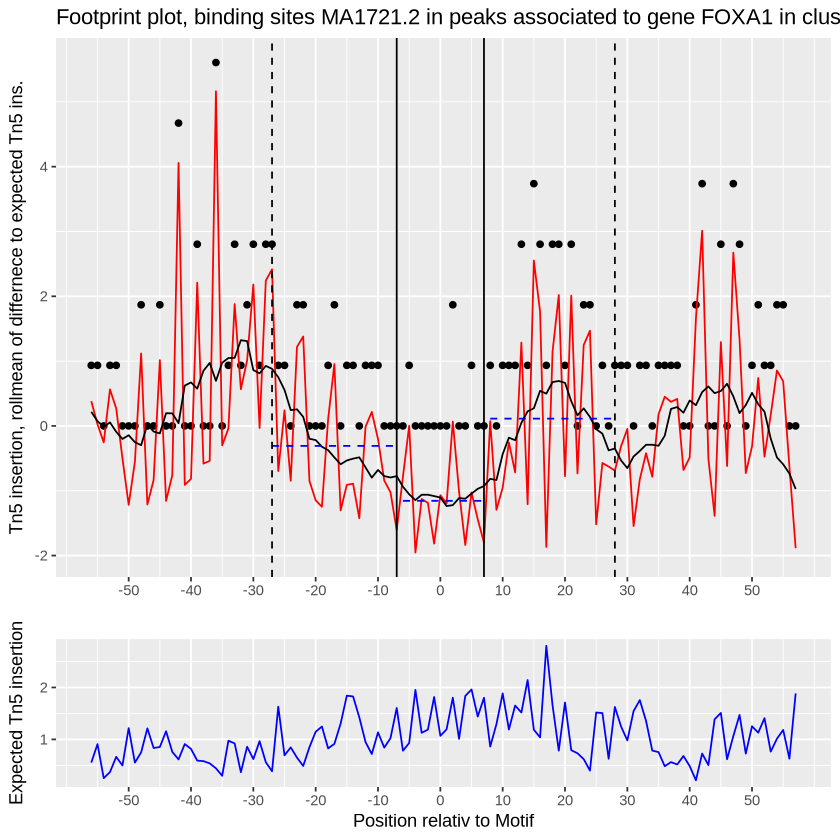

In [32]:
tmp <- Footprint_gene_motif(object, gene="FOXA1", cluster="6", motif="MA1721.2", flank_width = 20,
                                        plotting=TRUE,
                                        return_data=TRUE
                                        )

In [33]:
str(tmp@misc, max.level=1)

List of 14
 $ markers.annotated        :'data.frame':	4000 obs. of  8 variables:
 $ peak_stats               :'data.frame':	57 obs. of  43 variables:
 $ peak_stats.filtered      :'data.frame':	22 obs. of  51 variables:
 $ motifs.inProximalPeaks   :List of 1
 $ motifs.inDistalPeaks     :List of 1
 $ motif_enrichment         :'data.frame':	720 obs. of  16 variables:
 $ filtered.motif_enrichment:'data.frame':	193 obs. of  16 variables:
 $ motif_stats              :'data.frame':	193 obs. of  24 variables:
 $ motif2TF                 :List of 720
 $ TF2motif                 :List of 668
 $ seedNetwork              :List of 1
 $ context_subNetwork       :List of 1
 $ position.enrichment      :List of 1
 $ footprint                :List of 1


In [35]:
colnames(tmp@misc$motif_stats)

[1] "gene"                      "cluster"                  
 [3] "proximal.motif_count"      "proximal.background_count"
 [5] "log2FC.proximal"           "t_stat.proximal"          
 [7] "p_value.proximal"          "p_adjust.proximal"        
 [9] "distal.motif_count"        "distal.background_count"  
[11] "log2FC.distal"             "t_stat.distal"            
[13] "p_value.distal"            "p_adjust.distal"          
[15] "motif"                     "promoter.motif_count"     
[17] "footprint_score"           "bg_size"                  
[19] "bg_footprint_mean"         "footprint.t_stat"         
[21] "footprint.p_value"         "footprint.p_value_adj"    
[23] "sd.flanks"                 "bg_sd_mean"

In [28]:
sum(colSums(tmp@misc$position.enrichment$`FOXA1 6`$MA1721.2)!=0)

[1] 67

In [26]:
tmp@misc$motif_stats

,gene,cluster,proximal.motif_count,proximal.background_count,log2FC.proximal,t_stat.proximal,p_value.proximal,p_adjust.proximal,distal.motif_count,distal.background_count,⋯,motif,promoter.motif_count,footprint_score,bg_size,bg_footprint_mean,footprint.t_stat,footprint.p_value,footprint.p_value_adj,sd.flanks,bg_sd_mean
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
4,FOXA1,6,1,0.44,1.2,-5.9,1.9e-07,0.00014,0,0.12,⋯,MA0101.1,3,0.1251,100,-0.0803600,-1.0970,8.623e-01,1.0e+00,2.235,4.453
5,FOXA1,6,1,0.46,1.1,-5.6,4.1e-07,3e-04,0,0.14,⋯,MA0107.1,1,0.1251,100,0.0456700,-0.3326,6.299e-01,1.0e+00,2.235,4.561
9,FOXA1,6,3,4.6,-0.62,2.5,0.99,1,0,1.4,⋯,MA0149.1,0,0.4703,100,0.0865800,-3.1690,9.990e-01,1.0e+00,1.605,3.877
10,FOXA1,6,1,0.94,0.089,-0.41,0.34,1,0,0.72,⋯,MA0155.1,1,-0.5262,100,-0.3880000,0.6853,2.474e-01,1.0e+00,2.342,4.641
12,FOXA1,6,1,1.4,-0.49,2.1,0.98,1,0,0.72,⋯,MA0163.1,0,3.0020,100,0.0410700,-16.4400,1.000e+00,1.0e+00,2.997,4.011
13,FOXA1,6,1,0.12,3.1,-16,1.5e-21,1.1e-18,0,0.08,⋯,MA0468.1,5,-0.7952,100,-0.0005796,4.5780,6.834e-06,1.3e-03,2.877,4.826
14,FOXA1,6,2,0.58,1.8,-13,1.5e-17,1.1e-14,0,0.44,⋯,MA0258.2,1,0.1958,100,0.0790600,-0.6978,7.565e-01,1.0e+00,2.676,3.714
17,FOXA1,6,2,4.6,-1.2,6.1,1,1,0,2.7,⋯,MA0599.1,8,1.5740,100,-0.3524000,-12.5400,1.000e+00,1.0e+00,1.645,3.061
26,FOXA1,6,2,0.2,3.3,-22,1.4e-27,1e-24,0,0.08,⋯,MA0655.1,0,-0.8859,100,0.0459600,4.8440,2.350e-06,4.5e-04,2.449,4.306


### test

In [39]:
tmp@misc$motif_stats <- NULL

In [41]:
tmp2 <- do_local_motif_stats(object=tmp, 
                               seeds=data.frame(gene="FOXA1", cluster="6", annotation="seed"),
                               fragpath=NULL,
                               peaks_assay='peaks',
                               background_size=5,
                               min_count=1, min_log2FC=1, max_t_stat=0, min_p_adjust=0.05)

Calculating motif enrichment

counting motifs in linked peaks



[1] 1
[1] 1
[1] "2026-04-08 11:54:05 CEST"


computed motif count

